In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import textwrap
from matplotlib.patches import Patch
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from matplotlib_venn import venn2
from matplotlib import cm
from pathlib import Path
from matplotlib.colors import Normalize, LinearSegmentedColormap

import requests
from io import StringIO

In [33]:
file_path = "GO_file.xlsx"
sheets = pd.read_excel(file_path, sheet_name=None)

In [34]:
for sheet_name, df in sheets.items():

    if "Name" in df.columns:

        # Extract GeneID from Name
        df["GO_GeneID"] = (
            df["Name"]
            .astype(str)
            .str.extract(r"^LOC(\d+)$")[0]
        )

        # Check matching with GeneID column
        if "GeneID" in df.columns:

            def match_gene_id(row):
                gene_id = row["GO_GeneID"]

                if pd.isna(gene_id):
                    return None

                gene_ids = [
                    x.strip()
                    for x in str(row["GeneID"]).split(",")
                ]

                return gene_id if gene_id in gene_ids else None

            df["GO_GeneID"] = df.apply(match_gene_id, axis=1)

        sheets[sheet_name] = df

        print(f"{sheet_name}: {df['GO_GeneID'].notna().sum()} matched genes")

# Update the original Excel file
with pd.ExcelWriter(
    file_path,
    engine="openpyxl",
    mode="w"
) as writer:

    for sheet_name, df in sheets.items():
        df.to_excel(writer, sheet_name=sheet_name, index=False)

GA: 5935 matched genes
PAC: 4053 matched genes
GA-PAC: 2161 matched genes


In [35]:
gene_lists = {}

for sheet_name, df in sheets.items():

    required = [
        "GO_GeneID",
        "Log₂ fold change",
        "FDR p-value"
    ]

    if not all(col in df.columns for col in required):
        print(f"Skipped: {sheet_name}")
        continue

    df = df.copy()

    df["Log₂ fold change"] = pd.to_numeric(
        df["Log₂ fold change"], errors="coerce"
    )

    df["FDR p-value"] = pd.to_numeric(
        df["FDR p-value"], errors="coerce"
    )

    # All tested genes
    background = df.loc[
        df["FDR p-value"].notna(),
        "GO_GeneID"
    ].dropna().astype(str).unique().tolist()

    # Upregulated
    up = df.loc[
        (df["FDR p-value"] < 0.05) &
        (df["Log₂ fold change"] >= 1),
        "GO_GeneID"
    ].dropna().astype(str).unique().tolist()

    # Downregulated
    down = df.loc[
        (df["FDR p-value"] < 0.05) &
        (df["Log₂ fold change"] <= -1),
        "GO_GeneID"
    ].dropna().astype(str).unique().tolist()

    gene_lists[sheet_name] = {
        "up": up,
        "down": down,
        "background": background
    }

    print(f"\n{sheet_name}")
    print("Upregulated:", len(up))
    print("Downregulated:", len(down))
    print("Background:", len(background))


GA
Upregulated: 2547
Downregulated: 1676
Background: 5935

PAC
Upregulated: 1692
Downregulated: 856
Background: 4053

GA-PAC
Upregulated: 562
Downregulated: 284
Background: 2161


# GO Functional Classification

In [5]:
chunks = []

for chunk in pd.read_csv(
    r"gene2go.gz",
    sep="\t",
    compression="gzip",
    chunksize=100000):
    
    filtered = chunk[chunk["#tax_id"] == 71139]

    if not filtered.empty:
        chunks.append(filtered)

go_eucalyptus = pd.concat(chunks, ignore_index=True)

print("GO annotation rows:", len(go_eucalyptus))
print("Unique genes:", go_eucalyptus["GeneID"].nunique())

go_eucalyptus.head()

GO annotation rows: 77077
Unique genes: 25512


,#tax_id,GeneID,GO_ID,Evidence,Qualifier,GO_term,PubMed,Category
0,71139,104414023,GO:0004553,IEA,enables,"hydrolase activity, hydrolyzing O-glycosyl com...",22301074,Function
1,71139,104414023,GO:0005975,IEA,involved_in,carbohydrate metabolic process,22301074,Process
2,71139,104414024,GO:0005515,IEA,enables,protein binding,22301074,Function
3,71139,104414024,GO:0009507,IEA,located_in,chloroplast,30032202,Component
4,71139,104414024,GO:0009658,IEA,involved_in,chloroplast organization,30032202,Process


In [36]:
go_eucalyptus = pd.read_parquet("go_eucalyptus.parquet")

In [37]:
# GA upregulated genes
ga_up = set(gene_lists["GA"]["up"])
pac_up = set(gene_lists["PAC"]["up"])
ga_pac_up = set(gene_lists["GA-PAC"]["up"])

# GA downregulated genes
ga_down = set(gene_lists["GA"]["down"])
pac_down = set(gene_lists["PAC"]["down"])
ga_pac_down = set(gene_lists["GA-PAC"]["down"])

In [38]:
def go_Functional(gene_list,go_annotation):
# Genes available in GO annotation
    annotated_ids = set(
        go_annotation["GeneID"].astype(str)
    )
    
    # Find matching genes
    matched = gene_list.intersection(annotated_ids)
    
    gene_list_go = go_annotation[
        go_annotation["GeneID"].astype(str).isin(matched)
    ].copy()
    
    go_counts = (
        gene_list_go
        .groupby(["Category", "GO_ID", "GO_term"])
        ["GeneID"]
        .nunique()
        .reset_index(name="Gene_Count")
        .sort_values("Gene_Count", ascending=False)
    )

    # Total gene_list genes with GO annotation
    total_annotated = gene_list_go["GeneID"].nunique()
    
    go_counts["Percentage"] = (
        go_counts["Gene_Count"] / total_annotated * 100
    ).round(2)
   
    bp = go_counts[go_counts["Category"] == "Process"] # Biological Processe
    mf = go_counts[go_counts["Category"] == "Function"] # Molecular Function
    cc = go_counts[go_counts["Category"] == "Component"] # Cellular Component
    
    print("Total genes:", len(gene_list))
    print("Genes with GO annotation:", len(matched))
    print(
        "Annotation coverage:",
        round(len(matched) / len(gene_list) * 100, 2)
        if gene_list else 0,
        "%")

    return bp , mf, cc

In [39]:
ga_up_bp, ga_up_mf, ga_up_cc = go_Functional(ga_up,go_eucalyptus)

Total genes: 2547
Genes with GO annotation: 1707
Annotation coverage: 67.02 %


In [40]:
pac_up_bp, pac_up_mf, pac_up_cc = go_Functional(pac_up,go_eucalyptus)

Total genes: 1692
Genes with GO annotation: 1215
Annotation coverage: 71.81 %


In [41]:
ga_pac_up_bp, ga_pac_up_mf, ga_pac_up_cc = go_Functional(ga_pac_up,go_eucalyptus)

Total genes: 562
Genes with GO annotation: 370
Annotation coverage: 65.84 %


In [42]:
ga_down_bp, ga_down_mf, ga_down_cc = go_Functional(ga_down,go_eucalyptus)

Total genes: 1676
Genes with GO annotation: 1224
Annotation coverage: 73.03 %


In [43]:
pac_down_bp, pac_down_mf, pac_down_cc = go_Functional(pac_down,go_eucalyptus)

Total genes: 856
Genes with GO annotation: 583
Annotation coverage: 68.11 %


In [44]:
ga_pac_down_bp, ga_pac_down_mf, ga_pac_down_cc = go_Functional(ga_pac_down,go_eucalyptus)

Total genes: 284
Genes with GO annotation: 212
Annotation coverage: 74.65 %


# Gene Enrichment Analysis

In [45]:
print("Total GO annotations:", len(go_eucalyptus))

print(
    "Unique genes:",
    go_eucalyptus["GeneID"].nunique()
)

print(
    "Unique GO terms:",
    go_eucalyptus["GO_ID"].nunique()
)

print(go_eucalyptus.columns.tolist())

Total GO annotations: 77077
Unique genes: 25512
Unique GO terms: 3875
['#tax_id', 'GeneID', 'GO_ID', 'Evidence', 'Qualifier', 'GO_term', 'PubMed', 'Category']


In [46]:
for sheet_name, df in sheets.items():

    background_genes = set(
        go_eucalyptus["GeneID"].astype(str)
    )
    
    deg_genes = set(
        df["GO_GeneID"].astype(str)
    )
    
    overlap = deg_genes & background_genes
    
    print("Background genes:", len(background_genes))
    print(f"DEG {sheet_name} genes:", len(deg_genes))
    print("DEGs with GO annotation:", len(overlap))
    
    print("GO annotation coverage:",round(len(overlap) / len(deg_genes) * 100, 2),"%\n")

Background genes: 25512
DEG GA genes: 5936
DEGs with GO annotation: 3889
GO annotation coverage: 65.52 %

Background genes: 25512
DEG PAC genes: 4054
DEGs with GO annotation: 2627
GO annotation coverage: 64.8 %

Background genes: 25512
DEG GA-PAC genes: 2162
DEGs with GO annotation: 1386
GO annotation coverage: 64.11 %



In [47]:
def go_Enrichment(gene_list, go_annotation, min_genes=5):

    go = go_annotation[
        ["GeneID", "GO_ID", "GO_term", "Category"]
    ].copy()

    go["GeneID"] = go["GeneID"].astype(str)

    # Remove duplicate gene-GO associations
    go = go.drop_duplicates(
        subset=["GeneID", "GO_ID", "Category"]
    )

    # Background: all genes with GO annotation
    background = set(go["GeneID"])
    N = len(background)

    # Target genes within background
    targets = set(map(str, gene_list)) & background
    n = len(targets)

    if n == 0:
        raise ValueError(
            "No target genes overlap with GO background."
        )

    results = []

    for (category, go_id), group in go.groupby(
        ["Category", "GO_ID"]
    ):

        term_genes = set(group["GeneID"])
        K = len(term_genes)

        if K < min_genes:
            continue

        # Genes in DEG list associated with GO term
        target_term_genes = targets & term_genes

        # Contingency table
        a = len(target_term_genes)
        b = n - a
        c = K - a
        d = N - a - b - c

        odds_ratio, p_value = fisher_exact(
            [[a, b], [c, d]],
            alternative="greater"
        )

        # Gene ratio
        gene_ratio = a / n

        # Background ratio
        background_ratio = K / N

        # Fold enrichment
        fold_enrichment = (
            gene_ratio / background_ratio
        )

        results.append({
            "Category": category,
            "GO_ID": go_id,
            "GO_term": group["GO_term"].iloc[0],

            "target_Gene_ids": ", ".join(
                sorted(target_term_genes)
            ),

            "background_Gene_ids": ", ".join(
                sorted(term_genes)
            ),

            "Gene_Count": a,
            "Background_Count": K,

            "Target_Total": n,
            "Background_Total": N,

            "Gene_Ratio": gene_ratio,
            "Background_Ratio": background_ratio,
            "Fold_Enrichment": fold_enrichment,

            "P_value": p_value,
            "Odds_Ratio": odds_ratio
        })

    result_df = pd.DataFrame(results)

    if result_df.empty:
        return result_df

    # Multiple testing correction
    result_df["FDR"] = multipletests(
        result_df["P_value"],
        method="fdr_bh"
    )[1]

    result_df["minus_log10_FDR"] = -np.log10(
        result_df["FDR"].clip(lower=1e-300)
    )

    return (
        result_df
        .sort_values("FDR")
        .reset_index(drop=True)
    )


In [48]:
go_enrichment_results = {}

for experiment in ["GA", "PAC", "GA-PAC"]:

    go_enrichment_results[experiment] = {}

    for direction in ["up", "down"]:

        result = go_Enrichment(
            gene_lists[experiment][direction],
            go_eucalyptus,
            min_genes=5
        )

        go_enrichment_results[experiment][direction] = result

        significant = result[result["FDR"] < 0.05]

        print(f"\n{experiment} - {direction}")
        print("Tested GO terms:", len(result))
        print("Significant GO terms:", len(significant))


GA - up
Tested GO terms: 1650
Significant GO terms: 46

GA - down
Tested GO terms: 1650
Significant GO terms: 84

PAC - up
Tested GO terms: 1650
Significant GO terms: 59

PAC - down
Tested GO terms: 1650
Significant GO terms: 37

GA-PAC - up
Tested GO terms: 1650
Significant GO terms: 23

GA-PAC - down
Tested GO terms: 1650
Significant GO terms: 18


## Treatment Enrichment

In [49]:
ga_up_enrichment = go_enrichment_results["GA"]["up"]
ga_down_enrichment = go_enrichment_results["GA"]["down"]

pac_up_enrichment = go_enrichment_results["PAC"]["up"]
pac_down_enrichment = go_enrichment_results["PAC"]["down"]

ga_pac_up_enrichment = go_enrichment_results["GA-PAC"]["up"]
ga_pac_down_enrichment = go_enrichment_results["GA-PAC"]["down"]

with pd.ExcelWriter("Treatment_GO_Enrichment.xlsx") as writer:

    ga_up_enrichment.to_excel(writer, sheet_name="GA Up", index=False)
    ga_down_enrichment.to_excel(writer, sheet_name="GA Down", index=False)
    pac_up_enrichment.to_excel(writer, sheet_name="PAC Up", index=False)
    pac_down_enrichment.to_excel(writer, sheet_name="PAC Down", index=False)
    ga_pac_up_enrichment.to_excel(writer, sheet_name="GA-PAC Up", index=False)
    ga_pac_down_enrichment.to_excel(writer, sheet_name="GA-PAC Down", index=False)

enrichment_dfs = {
    "GA Up": ga_up_enrichment,
    "GA Down": ga_down_enrichment,
    "PAC Up": pac_up_enrichment,
    "PAC Down": pac_down_enrichment,
    "GA-PAC Up": ga_pac_up_enrichment,
    "GA-PAC Down": ga_pac_down_enrichment
}

summary = []

for name, df in enrichment_dfs.items():

    sig = df[df["FDR"] < 0.05]

    summary.append({
        "Experiment": name,
        "Tested_GO": len(df),
        "Significant_GO": len(sig),
        "BP": (sig["Category"] == "Process").sum(),
        "MF": (sig["Category"] == "Function").sum(),
        "CC": (sig["Category"] == "Component").sum()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Experiment,Tested_GO,Significant_GO,BP,MF,CC
0,GA Up,1650,46,19,26,1
1,GA Down,1650,84,36,26,22
2,PAC Up,1650,59,21,35,3
3,PAC Down,1650,37,11,11,15
4,GA-PAC Up,1650,23,9,11,3
5,GA-PAC Down,1650,18,7,7,4


In [50]:
sig_enrichment = {}

for name, df in enrichment_dfs.items():

    sig_enrichment[name] = (
        df[df["FDR"] < 0.05]
        .sort_values("FDR")
        .reset_index(drop=True)
    )

## Group Enrichment

In [51]:
both_up = ga_up & pac_up
both_down = ga_down & pac_down
both_up_df = sheets["GA"][sheets["GA"]["GO_GeneID"].astype(str).isin(both_up)].copy()
both_down_df = sheets["GA"][sheets["GA"]["GO_GeneID"].astype(str).isin(both_down)].copy()

# Unique to each treatment
ga_up_only = ga_up - (pac_up | pac_down)
ga_down_only = ga_down - (pac_up | pac_down)
ga_up_only_df = sheets["GA"][sheets["GA"]["GO_GeneID"].astype(str).isin(ga_up_only)].copy()
ga_down_only_df = sheets["GA"][sheets["GA"]["GO_GeneID"].astype(str).isin(ga_down_only)].copy()

pac_up_only = pac_up - (ga_up | ga_down)
pac_down_only = pac_down - (ga_up | ga_down)
pac_up_only_df = sheets["PAC"][sheets["PAC"]["GO_GeneID"].astype(str).isin(pac_up_only)].copy()
pac_down_only_df = sheets["PAC"][sheets["PAC"]["GO_GeneID"].astype(str).isin(pac_down_only)].copy()

ga_up_pac_down = ga_up & pac_down
pac_up_ga_down = pac_up & ga_down
ga_up_pac_down_df = sheets["GA"][sheets["GA"]["GO_GeneID"].astype(str).isin(ga_up_pac_down)].copy()
pac_up_ga_down_df = sheets["PAC"][sheets["PAC"]["GO_GeneID"].astype(str).isin(pac_up_ga_down)].copy()

# GA-specific and PAC-specific Up genes supported by direct comparison
ga_specific_up = ga_up_only & ga_pac_up
pac_specific_up = pac_up_only & ga_pac_down
ga_specific_up_df = sheets["GA"][sheets["GA"]["GO_GeneID"].astype(str).isin(ga_specific_up)].copy()
pac_specific_up_df = sheets["PAC"][sheets["PAC"]["GO_GeneID"].astype(str).isin(pac_specific_up)].copy()

# GA-specific and PAC-specific Down genes supported by direct comparison
ga_specific_down = ga_down_only & ga_pac_down
pac_specific_down = pac_down_only & ga_pac_up
ga_specific_down_df = sheets["GA"][sheets["GA"]["GO_GeneID"].astype(str).isin(ga_specific_down)].copy()
pac_specific_down_df = sheets["PAC"][sheets["PAC"]["GO_GeneID"].astype(str).isin(pac_specific_down)].copy()

id_col = "GO_GeneID"
# Prepare each comparison
def prepare_comparison(df, label):
    data = df.copy()

    data[id_col] = data[id_col].astype("string").str.strip()

    data = data.rename(columns={
        "Log₂ fold change": f"Log2FC_{label}",
        "FDR p-value": f"FDR_{label}",
        "P-value": f"Pvalue_{label}"
    })

    return data

ga = prepare_comparison(sheets["GA"], "GA")
pac = prepare_comparison(sheets["PAC"], "PAC")
ga_pac = prepare_comparison(sheets["GA-PAC"], "GA_vs_PAC")

# Keep gene annotation from GA and PAC
annotation_cols = ["Name", "Chromosome", "Region","GeneID", "GO_GeneID", "RefSeq"]

product_col = next(
    col for col in ga.columns
    if col.startswith("product")
)

annotation_cols.insert(4, product_col)

annotations = pd.concat([
    ga[annotation_cols],
    pac[annotation_cols],
    ga_pac[annotation_cols]
]).drop_duplicates(subset=["GO_GeneID"])

# Comparison columns
def expression_cols(df, label):
    return df[[
        "GO_GeneID",
        f"Log2FC_{label}",
        f"Pvalue_{label}",
        f"FDR_{label}"
    ]].drop_duplicates(subset=["GO_GeneID"])


master_df = annotations.copy()

for data, label in [
    (ga, "GA"),
    (pac, "PAC"),
    (ga_pac, "GA_vs_PAC")
]:
    master_df = master_df.merge(
        expression_cols(data, label),
        on="GO_GeneID",
        how="left",
        validate="one_to_one"
    )
gene_groups = {
    "Both Up": both_up,
    "Both Down": both_down,
    "GA Up Only": ga_up_only,
    "GA Down Only": ga_down_only,
    "PAC Up Only": pac_up_only,
    "PAC Down Only": pac_down_only,
    "GA Up PAC Down": ga_up_pac_down,
    "PAC Up GA Down": pac_up_ga_down,
    "GA Specific Up": ga_specific_up,
    "GA Specific Down": ga_specific_down,
    "PAC Specific Up": pac_specific_up,
    "PAC Specific Down": pac_specific_down
}

with pd.ExcelWriter("DEG_Groups.xlsx") as writer:

    for name, genes in gene_groups.items():

        group_df = master_df[
            master_df["GO_GeneID"].isin(
                set(map(str, genes))
            )
        ].copy()

        group_df.to_excel(
            writer,
            sheet_name=name,
            index=False
        )

        print(name, len(group_df))


Both Up 1443
Both Down 519
GA Up Only 1103
GA Down Only 1157
PAC Up Only 249
PAC Down Only 336
GA Up PAC Down 1
PAC Up GA Down 0
GA Specific Up 283
GA Specific Down 184
PAC Specific Up 38
PAC Specific Down 108


In [53]:
group_enrichment = {}

background = set(
    go_eucalyptus["GeneID"].dropna().astype(str)
)

with pd.ExcelWriter("DEG_Group_GO_Enrichment.xlsx") as writer:

    for name, genes in gene_groups.items():

        genes = set(map(str, genes))
        matched_genes = genes & background

        if len(matched_genes) == 0:
            print(f"SKIPPED: {name} | No matched genes")
            continue

        result = go_Enrichment(
            matched_genes,
            go_eucalyptus,
            min_genes=5
        )

        group_enrichment[name] = result

        significant = result[result["FDR"] < 0.05]

        print(
            name,
            "| Genes:", len(genes),
            "| Matched:", len(matched_genes),
            "| Significant GO terms:", len(significant)
        )

        result.to_excel(
            writer,
            sheet_name=name,
            index=False
        )


Both Up | Genes: 1443 | Matched: 1027 | Significant GO terms: 49
Both Down | Genes: 519 | Matched: 354 | Significant GO terms: 31
ga_up_only | Genes: 1103 | Matched: 679 | Significant GO terms: 8
ga_down_only | Genes: 1157 | Matched: 870 | Significant GO terms: 47
pac_up_only | Genes: 249 | Matched: 188 | Significant GO terms: 8
pac_down_only | Genes: 336 | Matched: 228 | Significant GO terms: 11
GA Up PAC Down | Genes: 1 | Matched: 1 | Significant GO terms: 0
SKIPPED: PAC Up GA Down | No matched genes
GA Specific Up | Genes: 283 | Matched: 170 | Significant GO terms: 13
GA Specific Down | Genes: 184 | Matched: 140 | Significant GO terms: 24
PAC Specific Up | Genes: 38 | Matched: 32 | Significant GO terms: 5
PAC Specific Down | Genes: 108 | Matched: 74 | Significant GO terms: 4


## plot

### plot venn diagram

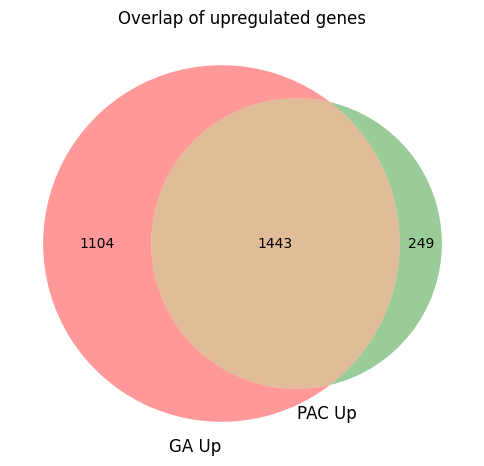

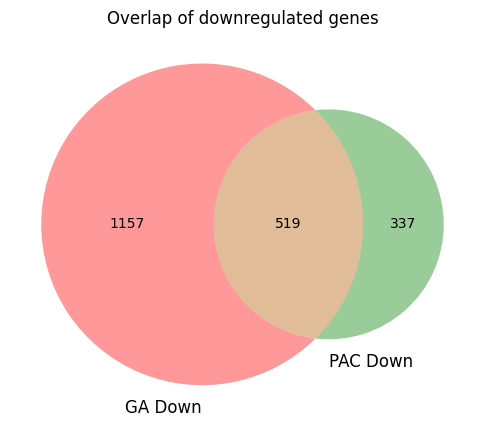

In [25]:
plt.figure(figsize=(6,6))
venn2([ga_up, pac_up], set_labels=("GA Up", "PAC Up"))
plt.title("Overlap of upregulated genes")
plt.savefig('Overlap of upregulated genes.png')
plt.show()

plt.figure(figsize=(6,6))
venn2([ga_down, pac_down], set_labels=("GA Down", "PAC Down"))
plt.title("Overlap of downregulated genes")
plt.savefig('Overlap of downregulated genes.png')
plt.show()

### plot barchart

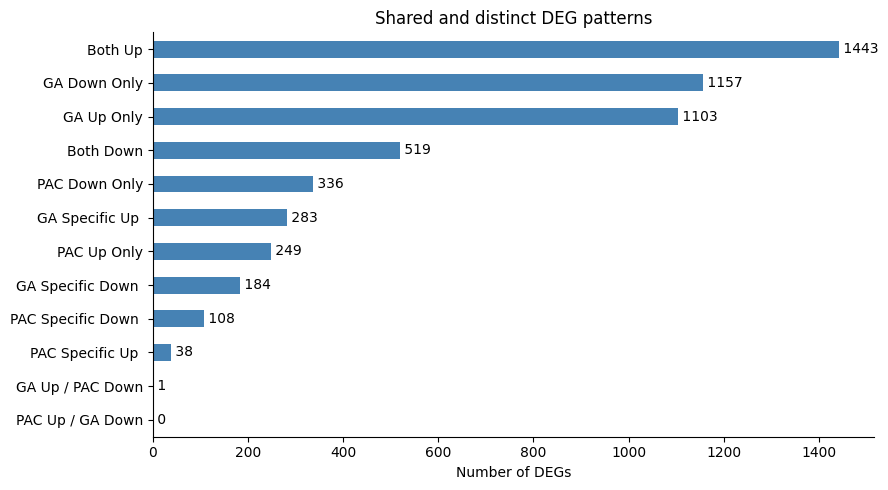

In [68]:
gene_counts = {
    "Both Up": len(both_up),
    "Both Down": len(both_down),
    "GA Up Only": len(ga_up_only),
    "GA Down Only": len(ga_down_only),
    "PAC Up Only": len(pac_up_only),
    "PAC Down Only": len(pac_down_only),
    "GA Up / PAC Down": len(ga_up_pac_down),
    "PAC Up / GA Down": len(pac_up_ga_down),
    "GA Specific Up ": len(ga_specific_up),
    "GA Specific Down ": len(ga_specific_down),
    "PAC Specific Up ": len(pac_specific_up),
    "PAC Specific Down ": len(pac_specific_down),
}

counts = pd.Series(gene_counts).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))

counts.plot.barh(ax=ax, color="steelblue")

for i, value in enumerate(counts):
    ax.text(value, i, f" {value}", va="center")

ax.set_xlabel("Number of DEGs")
ax.set_title("Shared and distinct DEG patterns")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig('Shared and distinct DEG patterns.png')
plt.show()

### plot scatterplot


Analysis: Treatment
Groups: 6
BP: 70 significant GO terms
Saved: GO_Bubble_Heatmaps\Treatment\GO_BP_Bubble_01.png


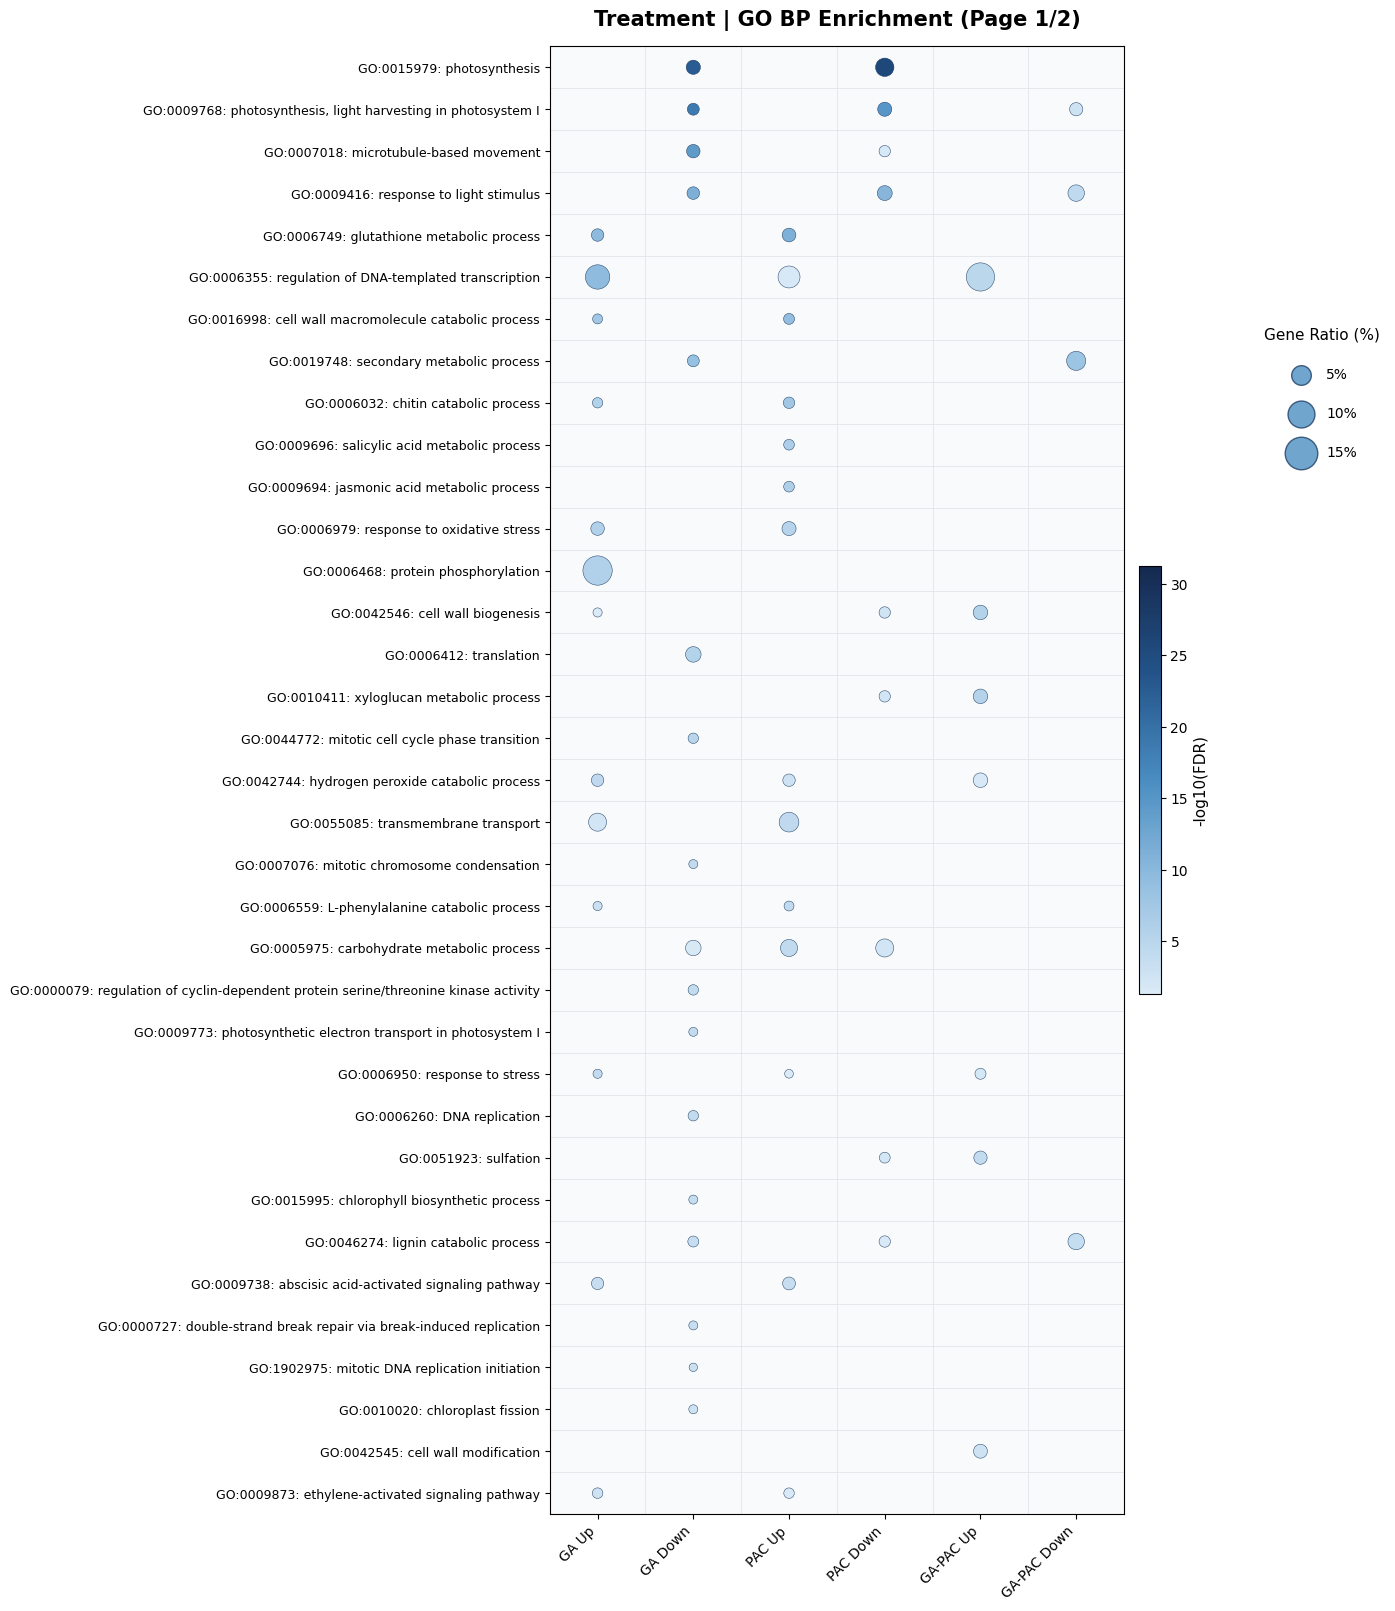

Saved: GO_Bubble_Heatmaps\Treatment\GO_BP_Bubble_02.png


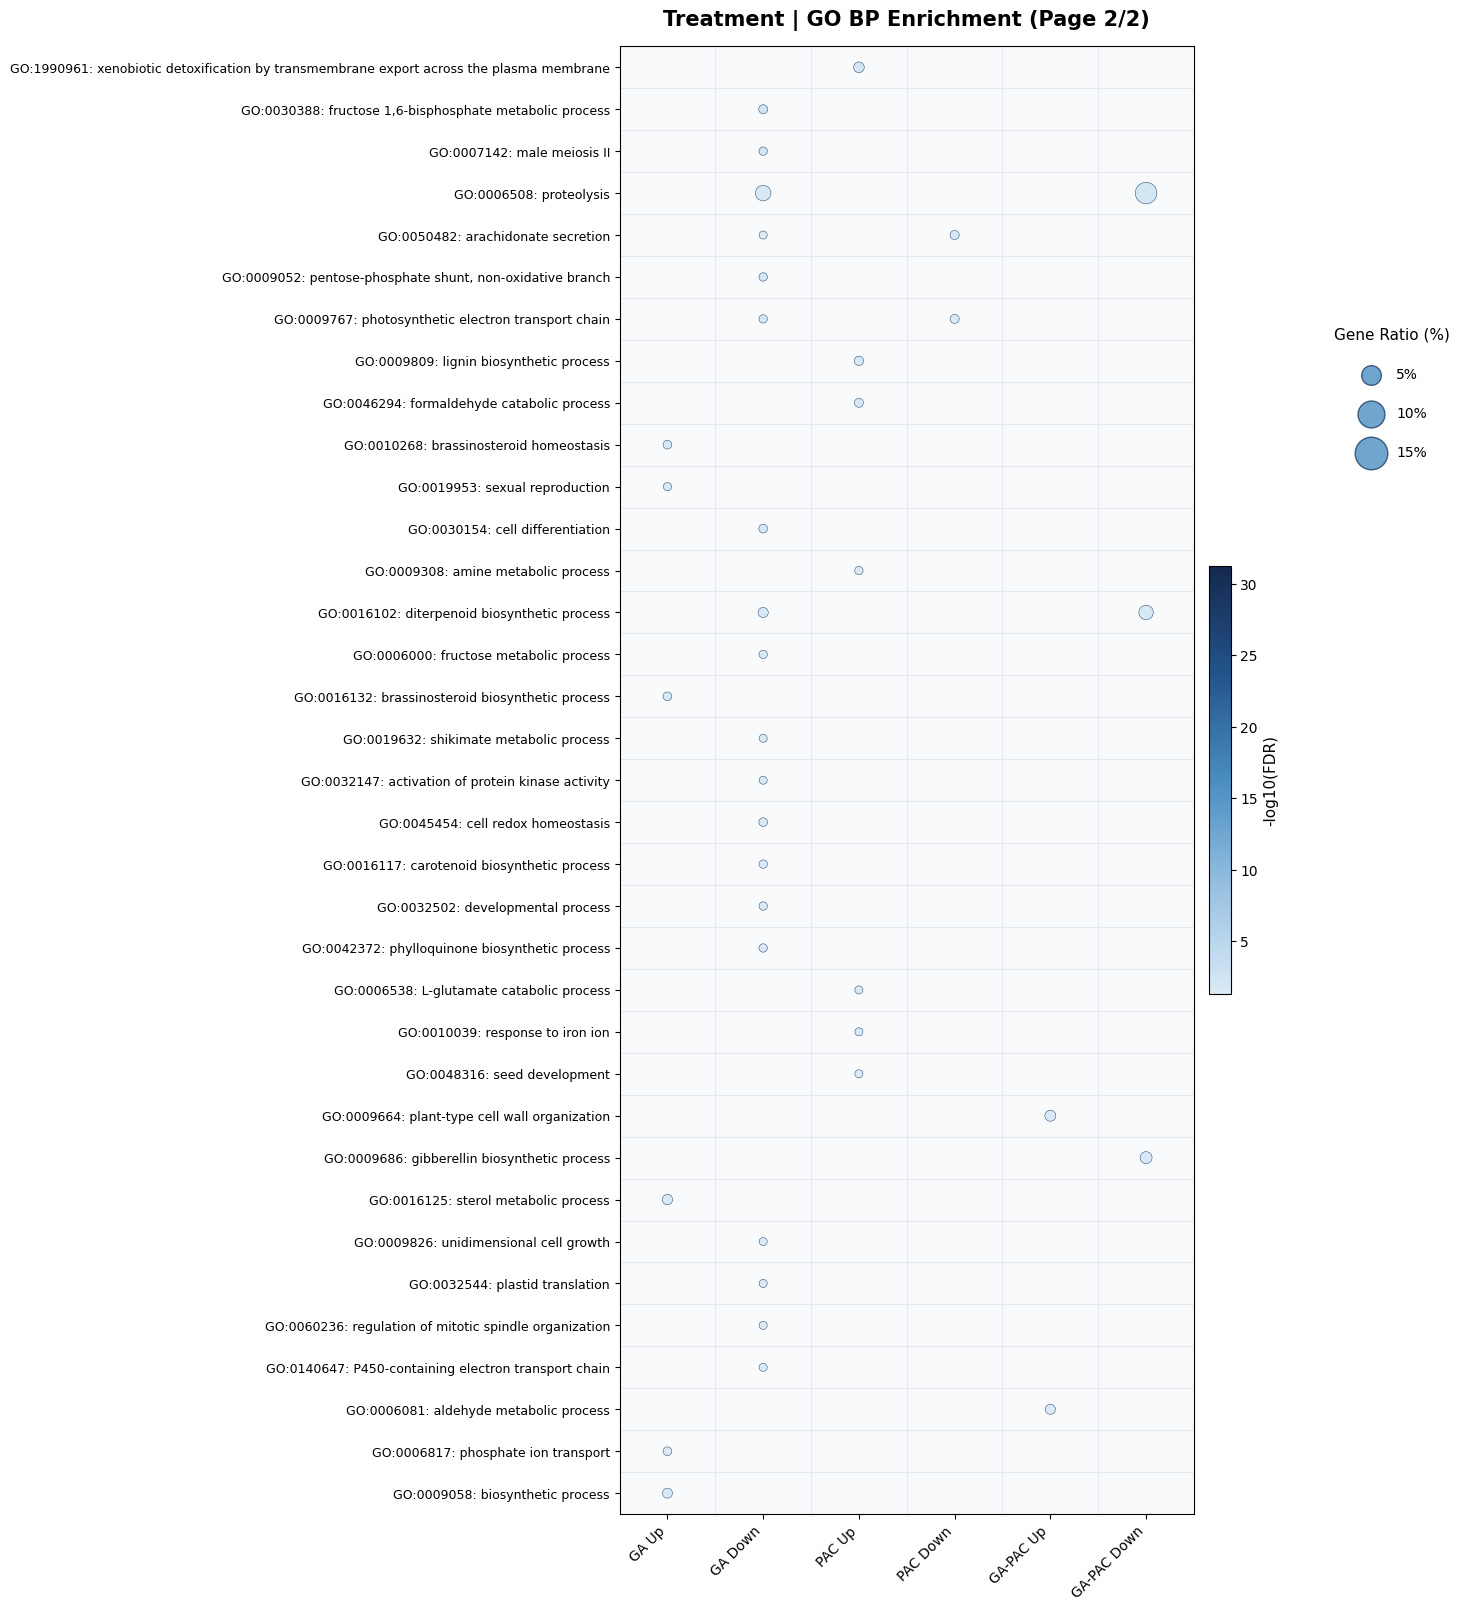

CC: 27 significant GO terms
Saved: GO_Bubble_Heatmaps\Treatment\GO_CC_Bubble_01.png


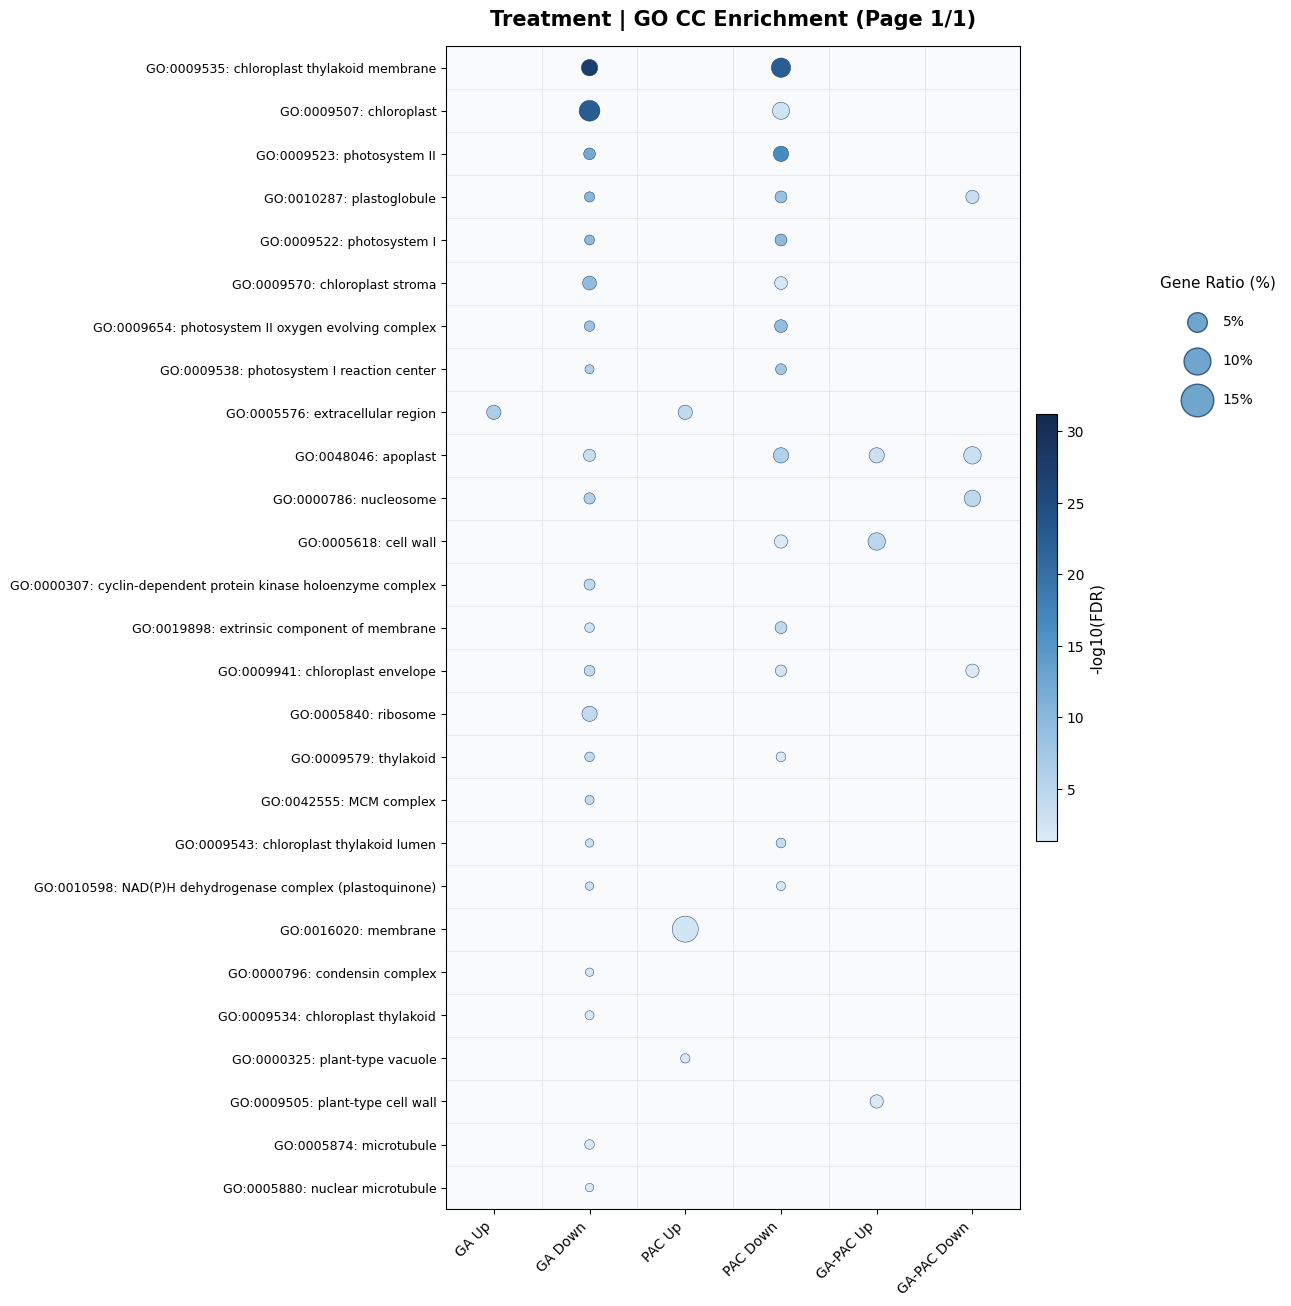

MF: 73 significant GO terms
Saved: GO_Bubble_Heatmaps\Treatment\GO_MF_Bubble_01.png


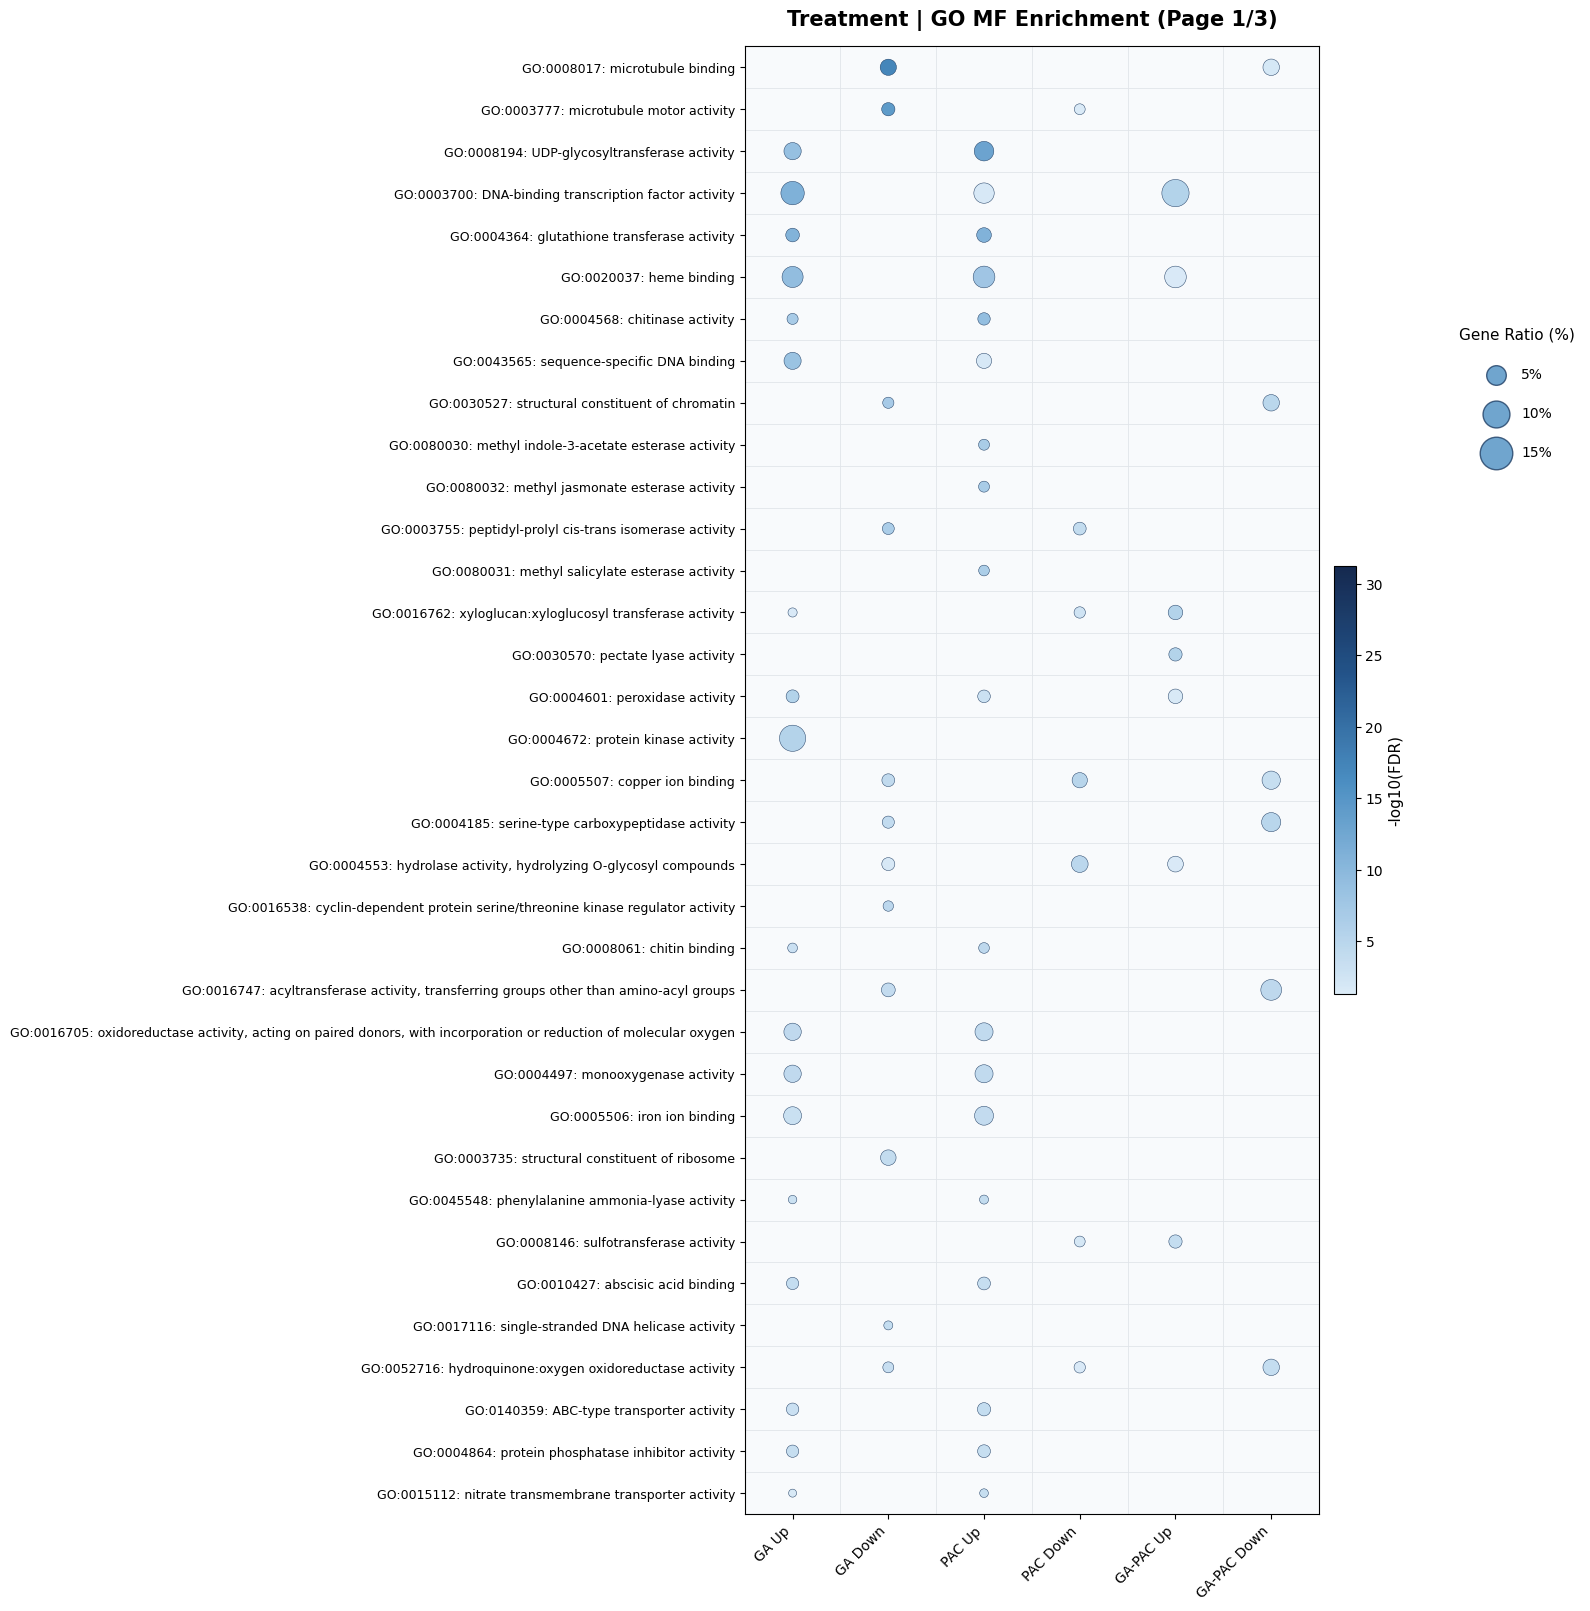

Saved: GO_Bubble_Heatmaps\Treatment\GO_MF_Bubble_02.png


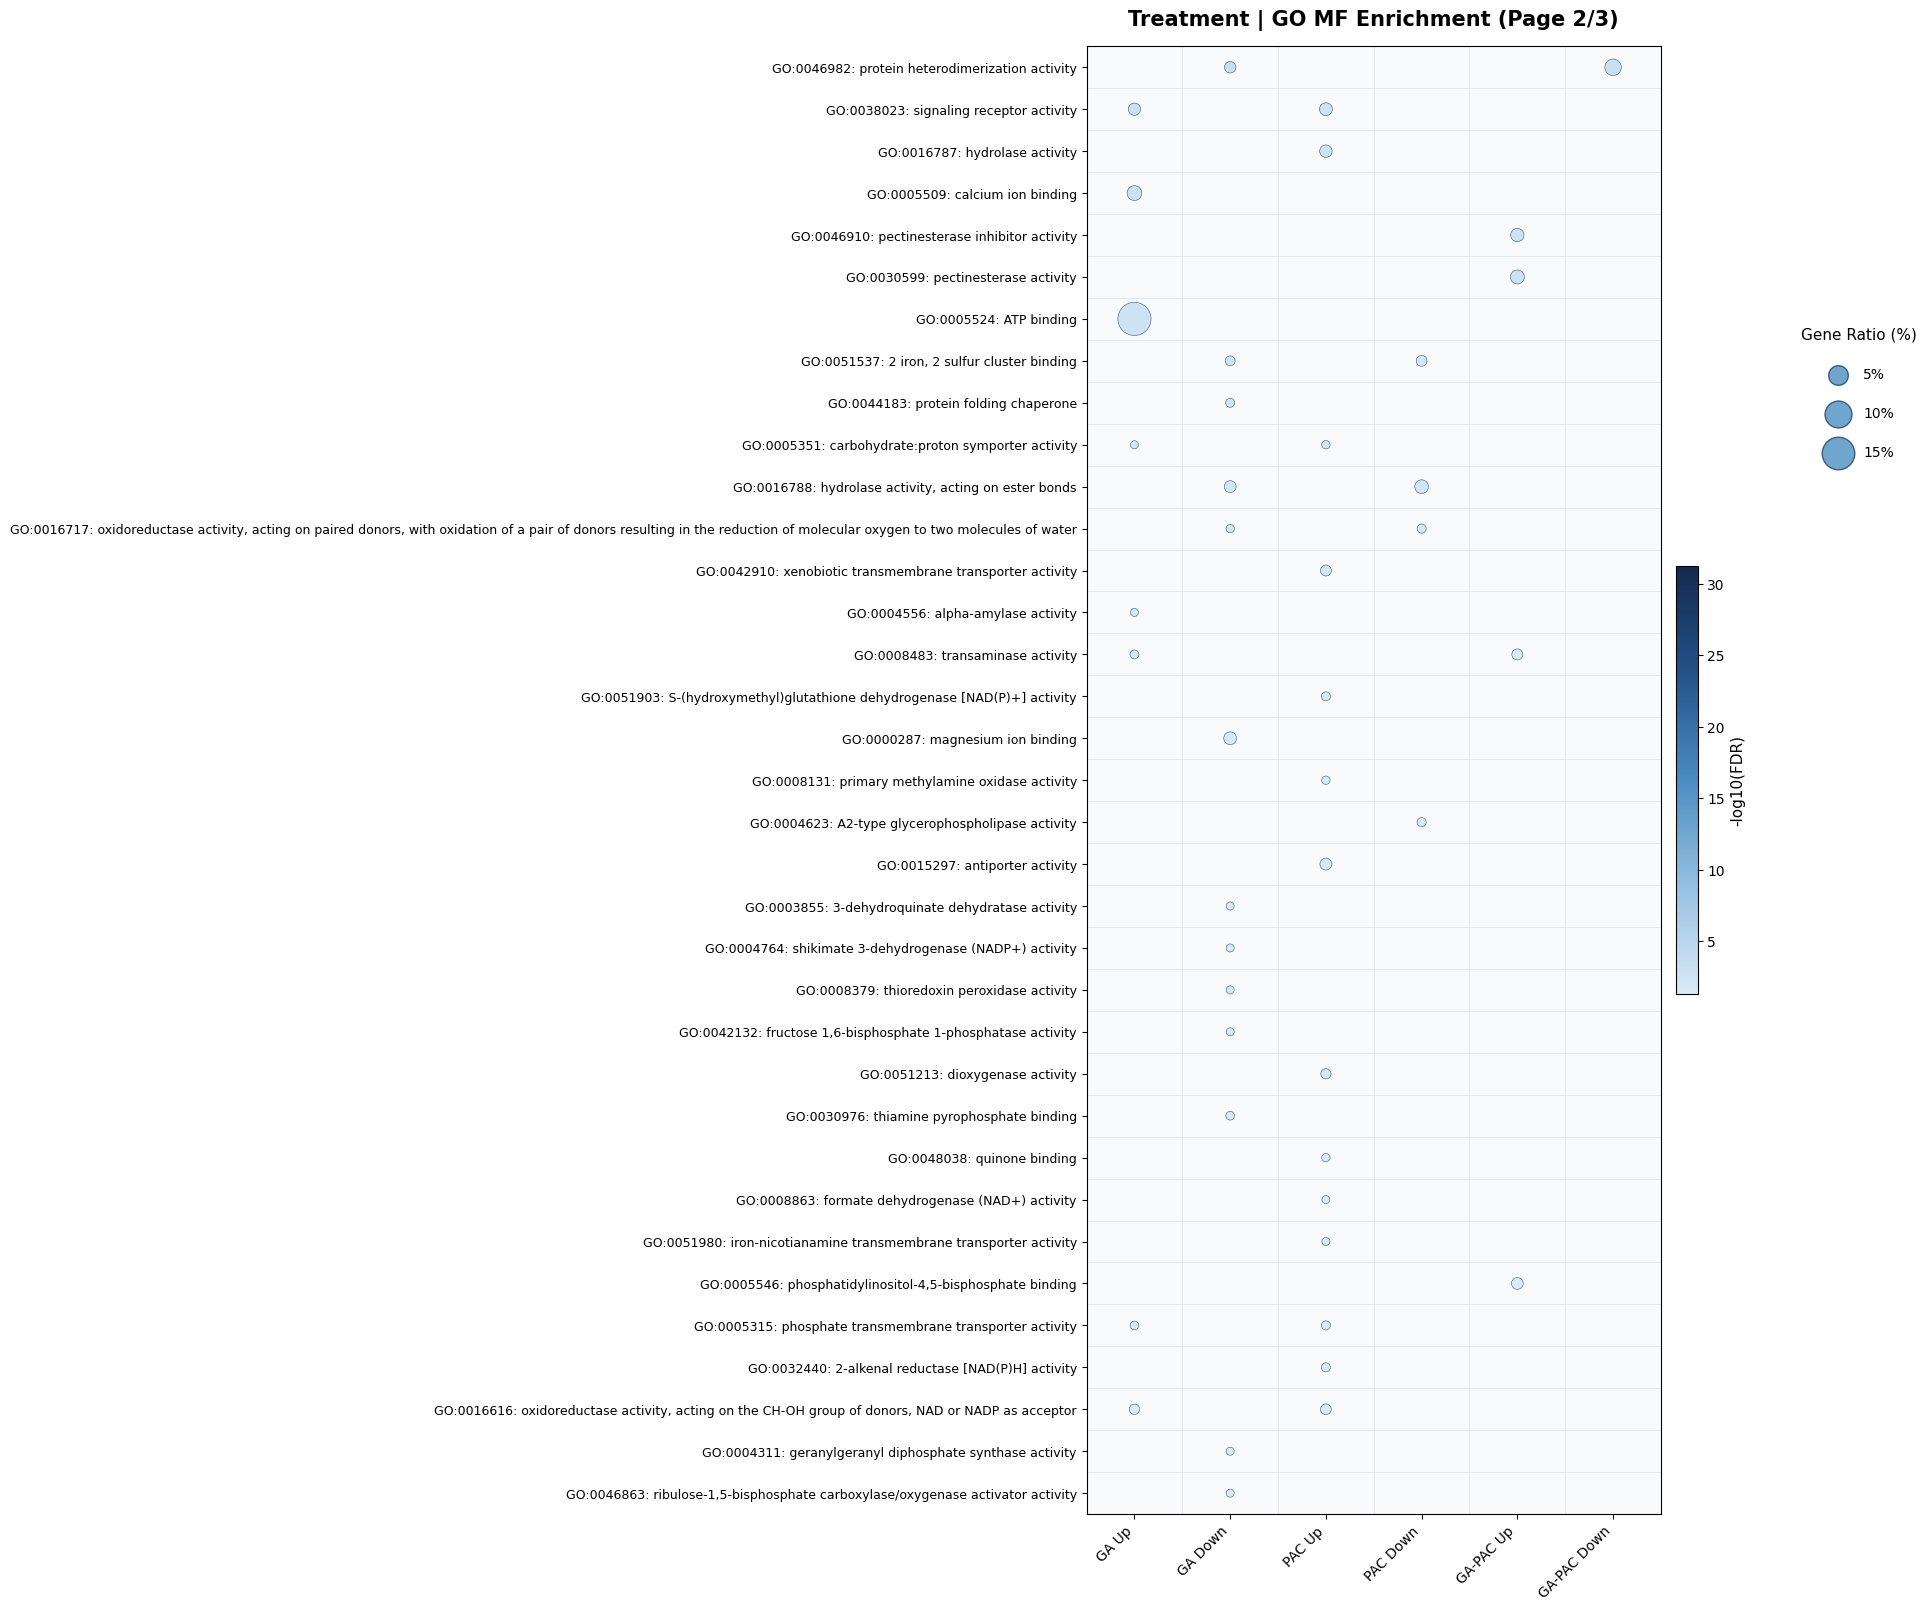

Saved: GO_Bubble_Heatmaps\Treatment\GO_MF_Bubble_03.png


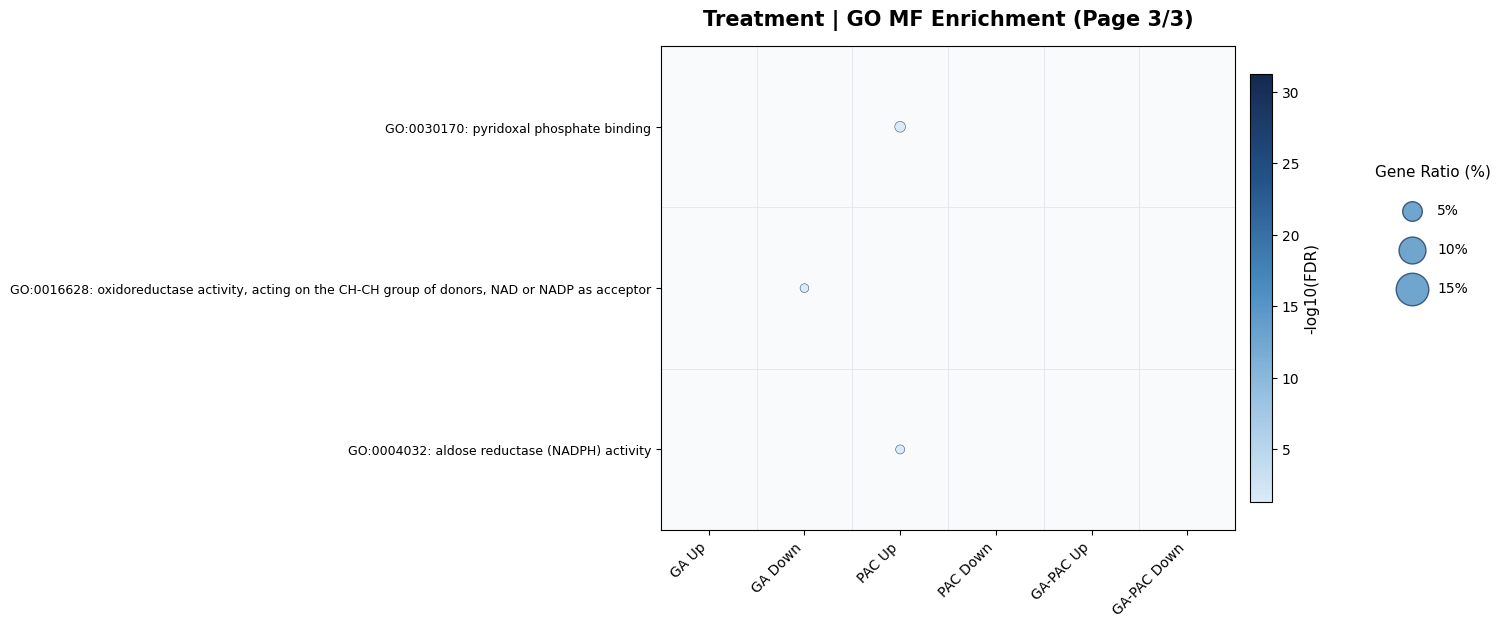


Analysis: Group
Groups: 12
BP: 63 significant GO terms
Saved: GO_Bubble_Heatmaps\Group\GO_BP_Bubble_01.png


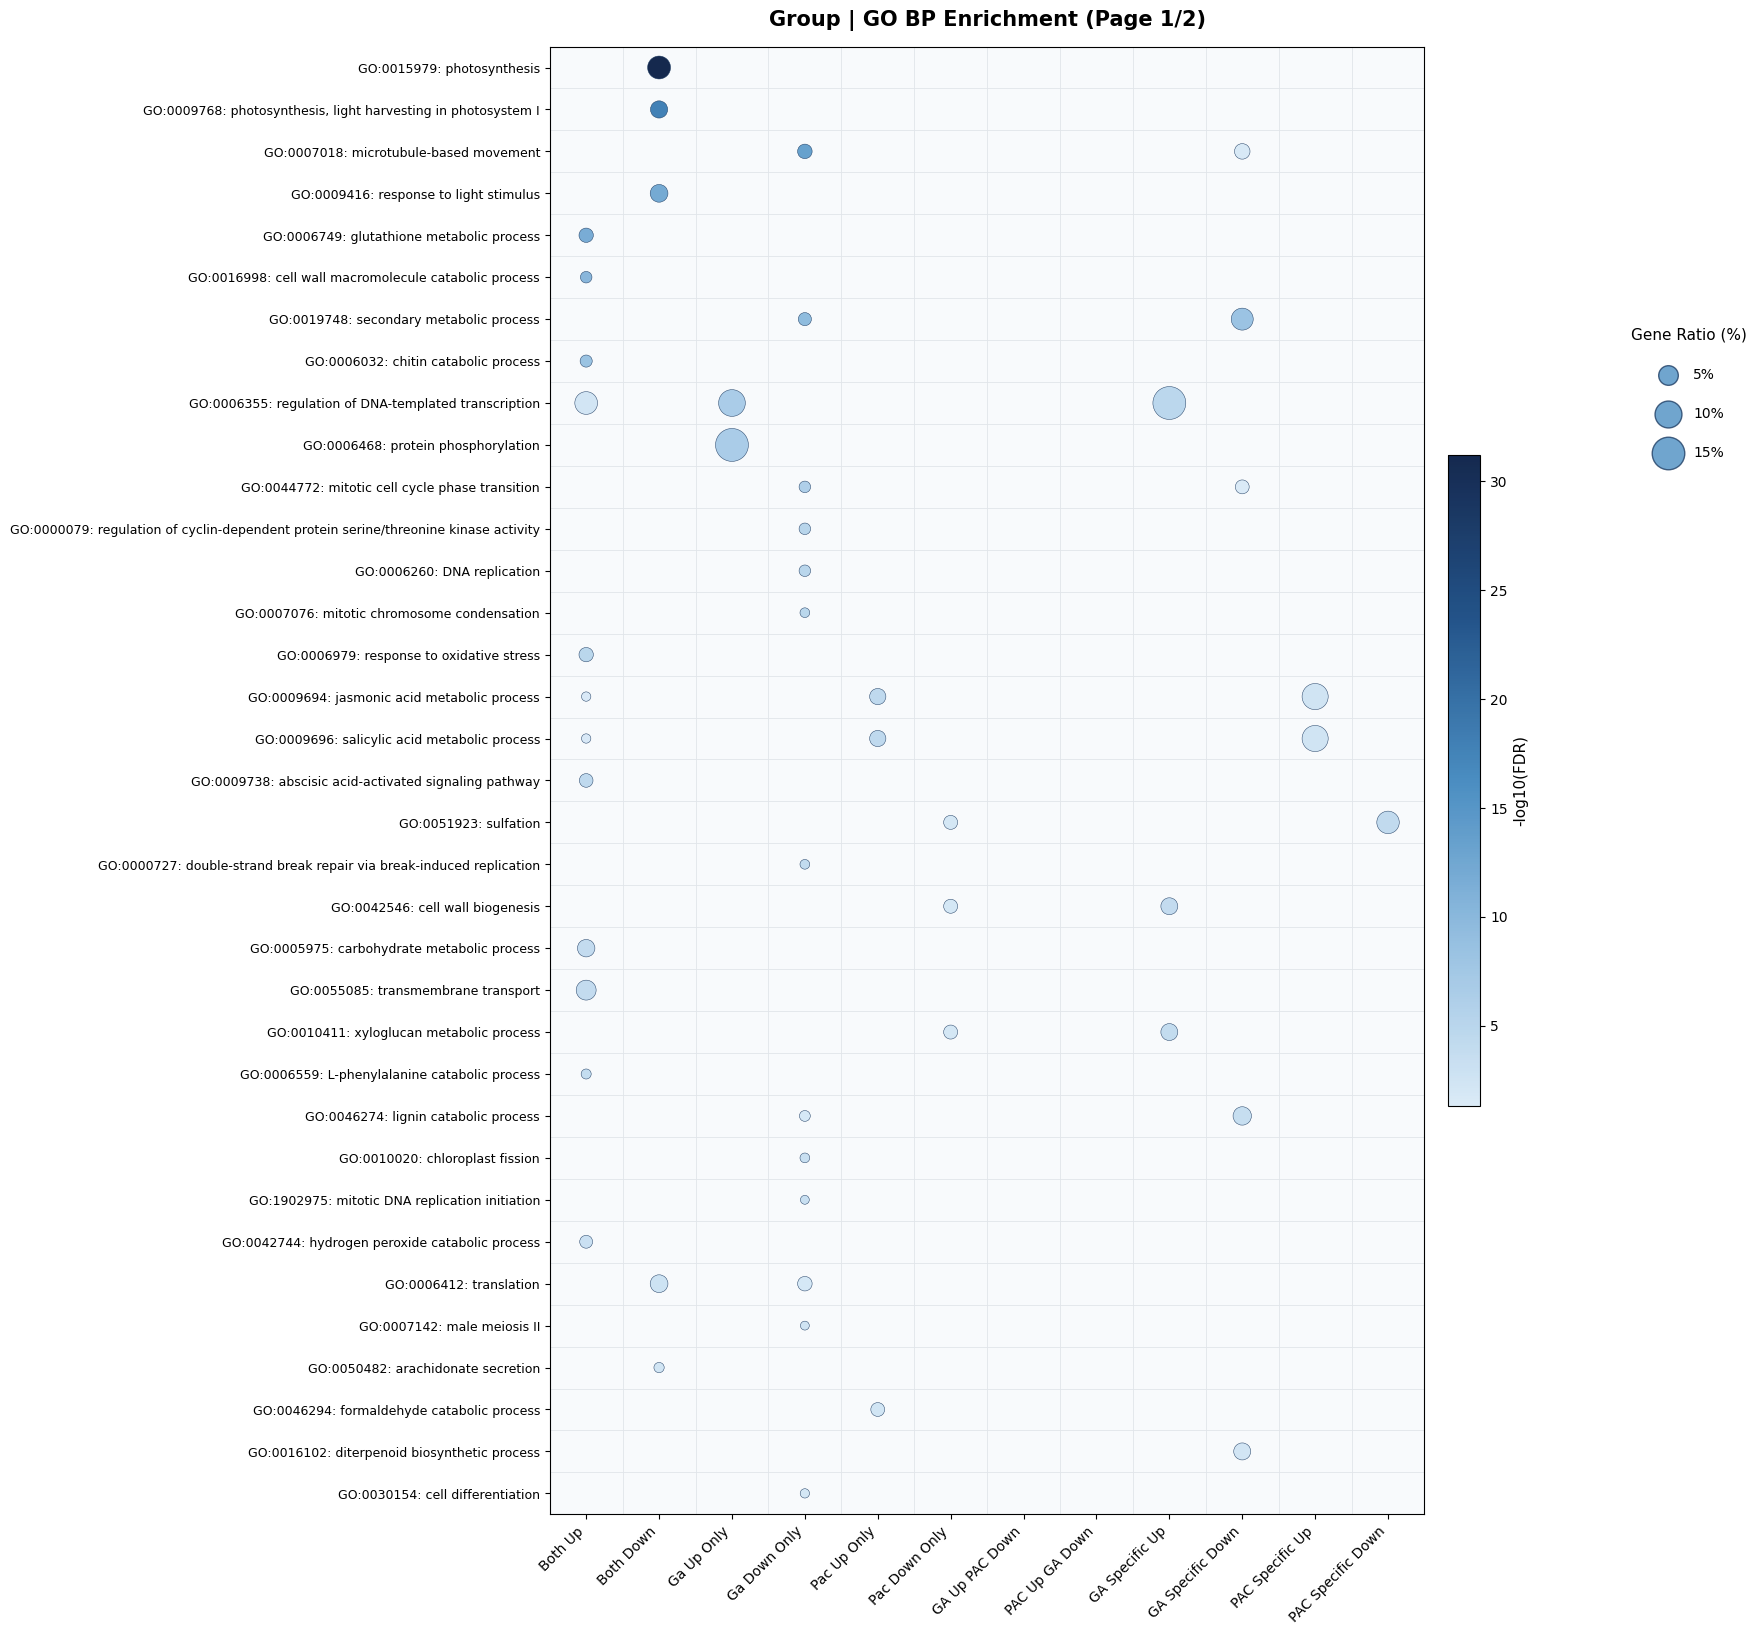

Saved: GO_Bubble_Heatmaps\Group\GO_BP_Bubble_02.png


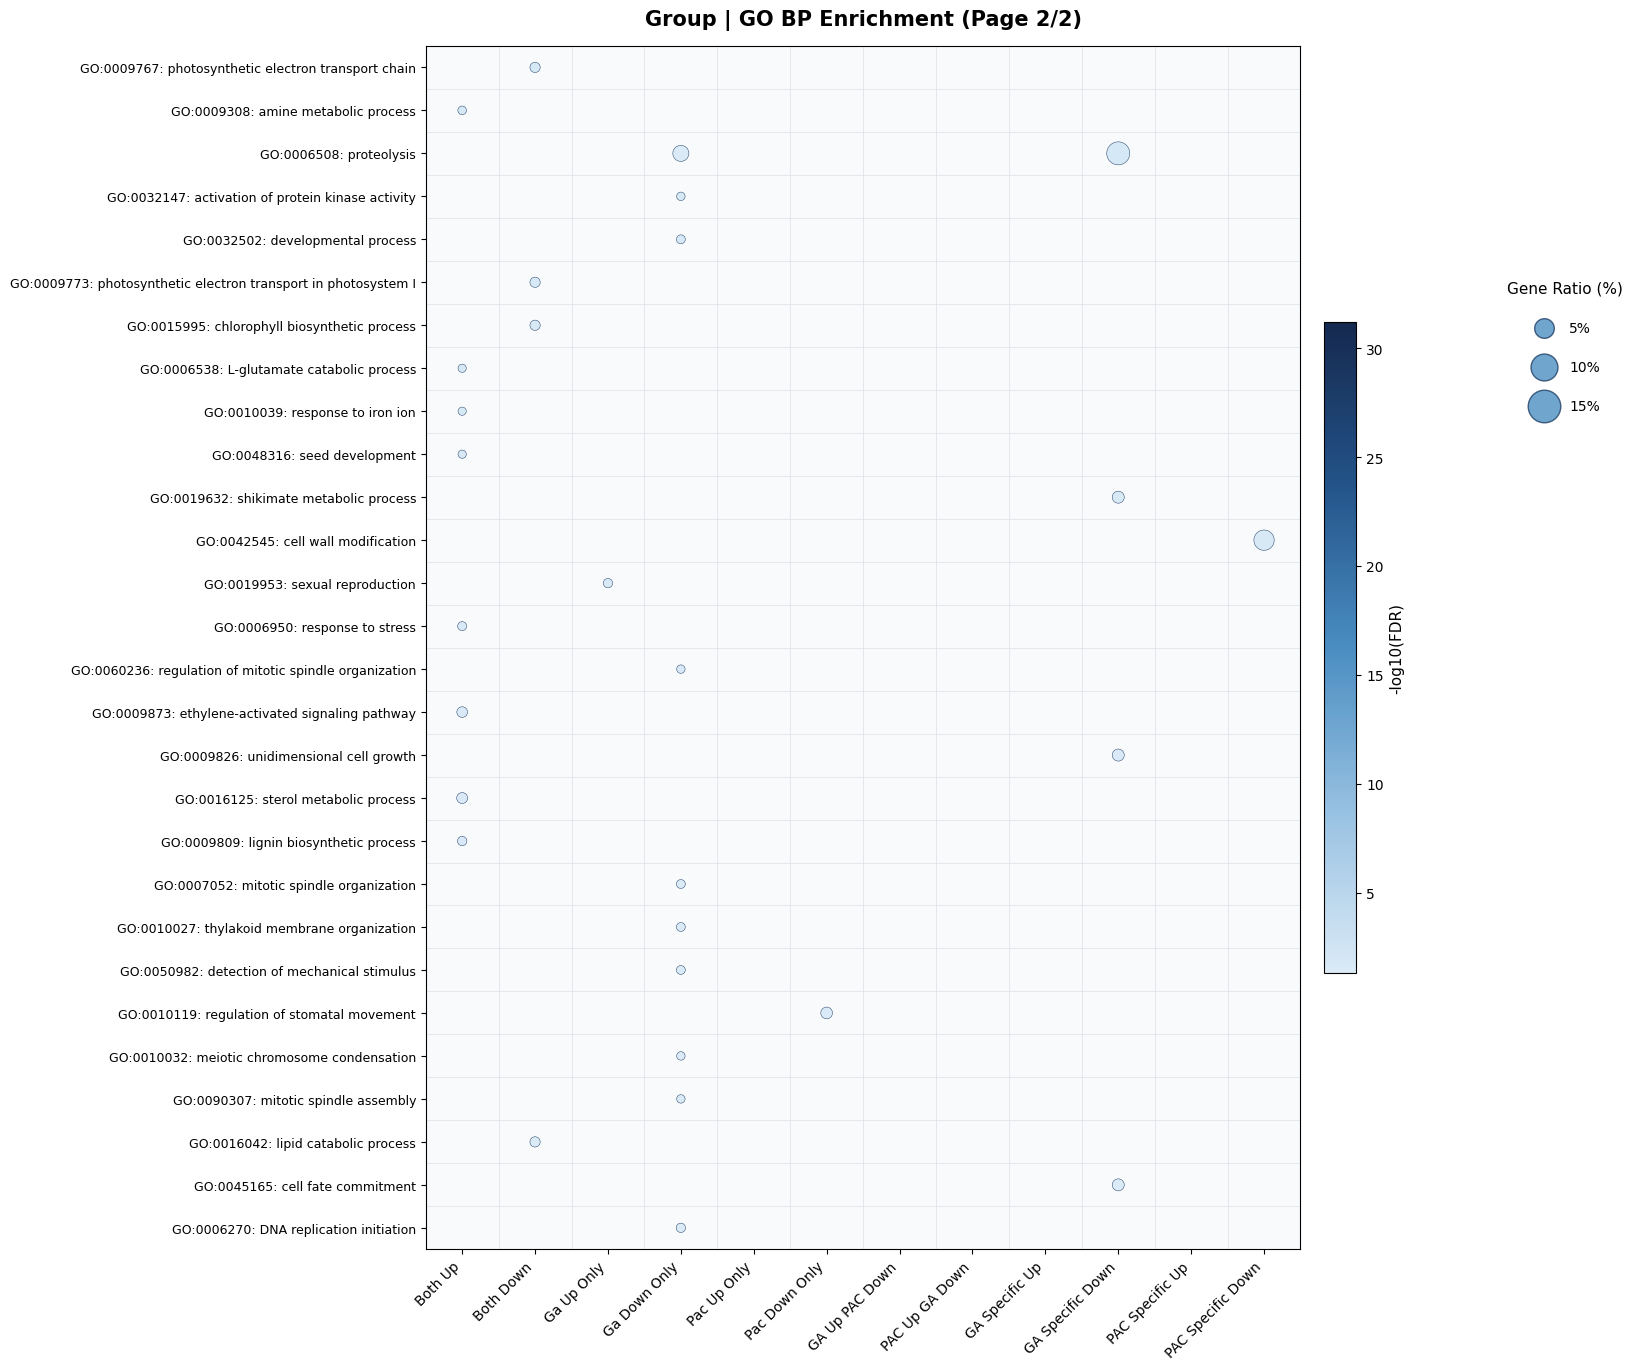

CC: 30 significant GO terms
Saved: GO_Bubble_Heatmaps\Group\GO_CC_Bubble_01.png


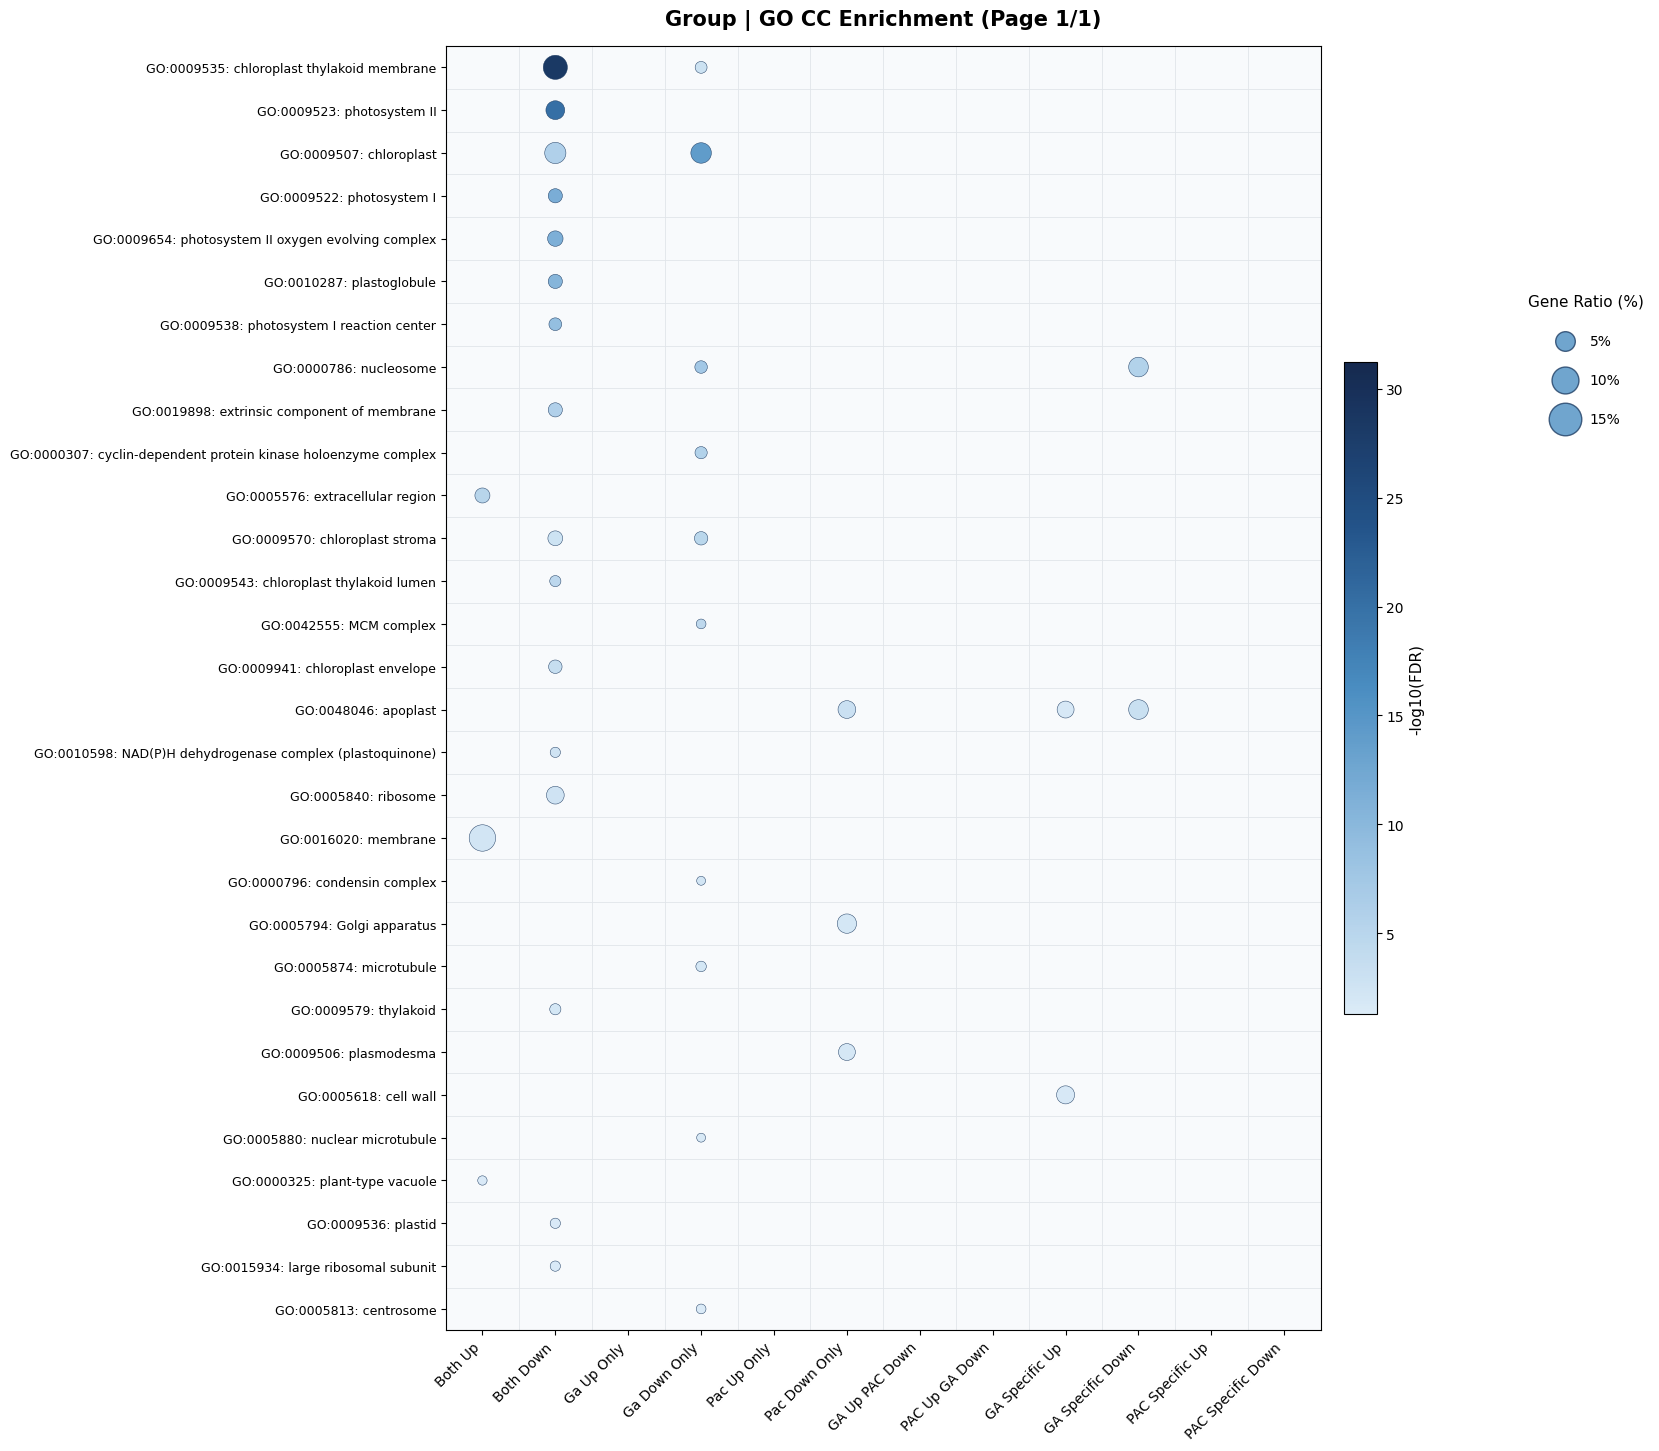

MF: 64 significant GO terms
Saved: GO_Bubble_Heatmaps\Group\GO_MF_Bubble_01.png


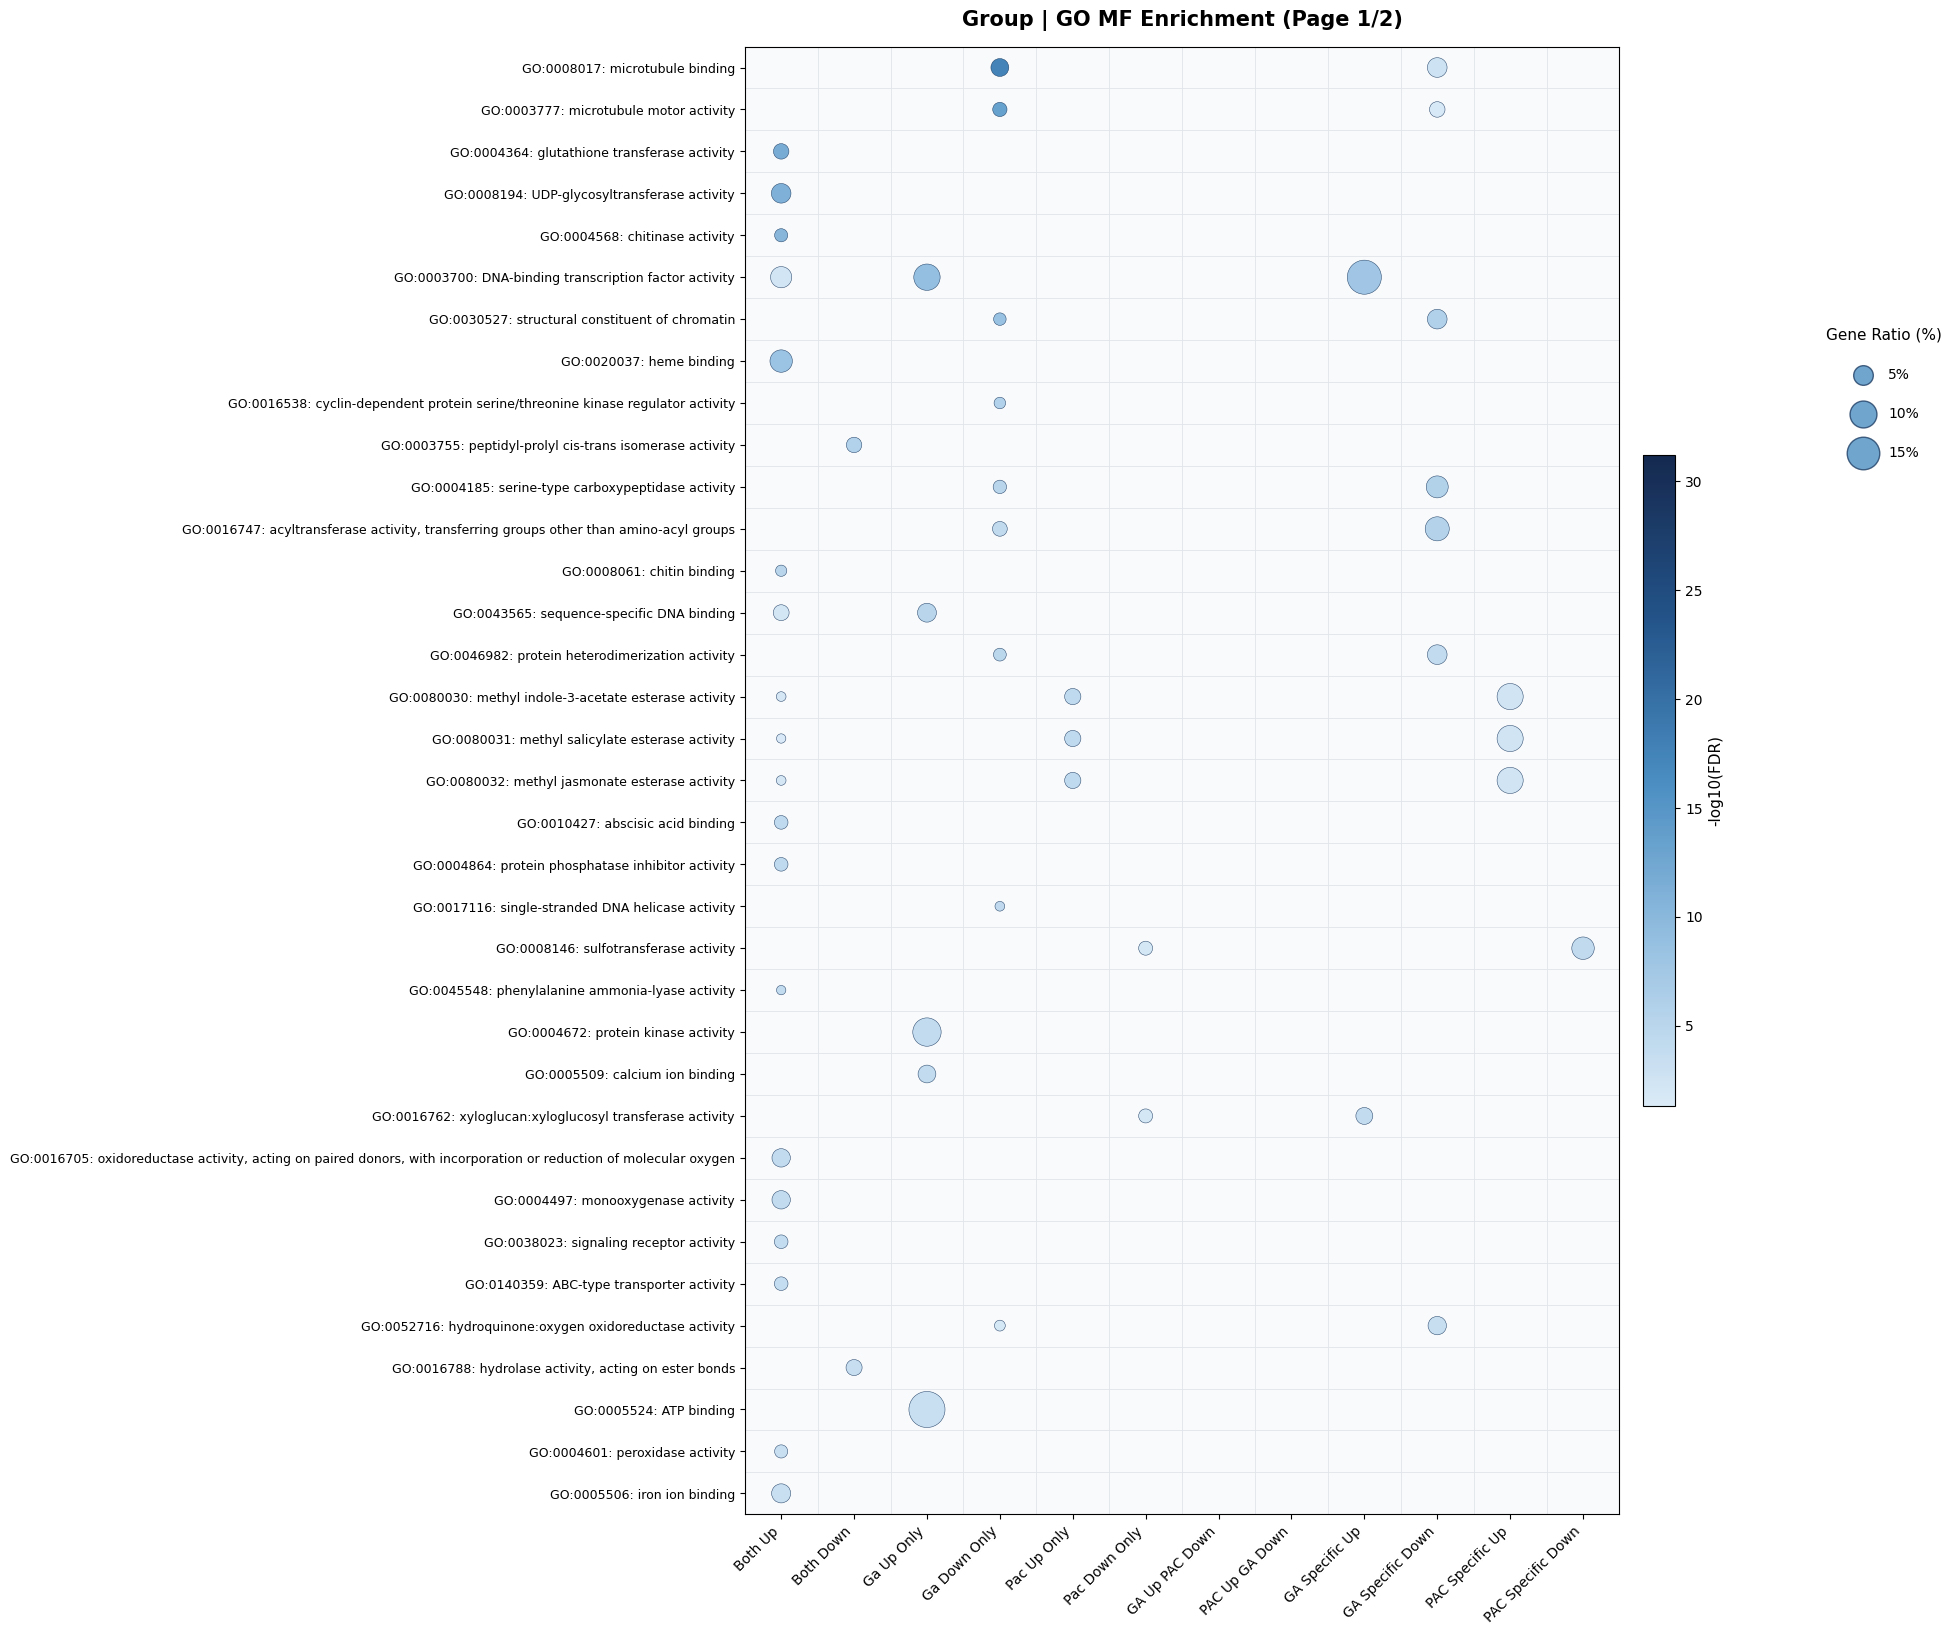

Saved: GO_Bubble_Heatmaps\Group\GO_MF_Bubble_02.png


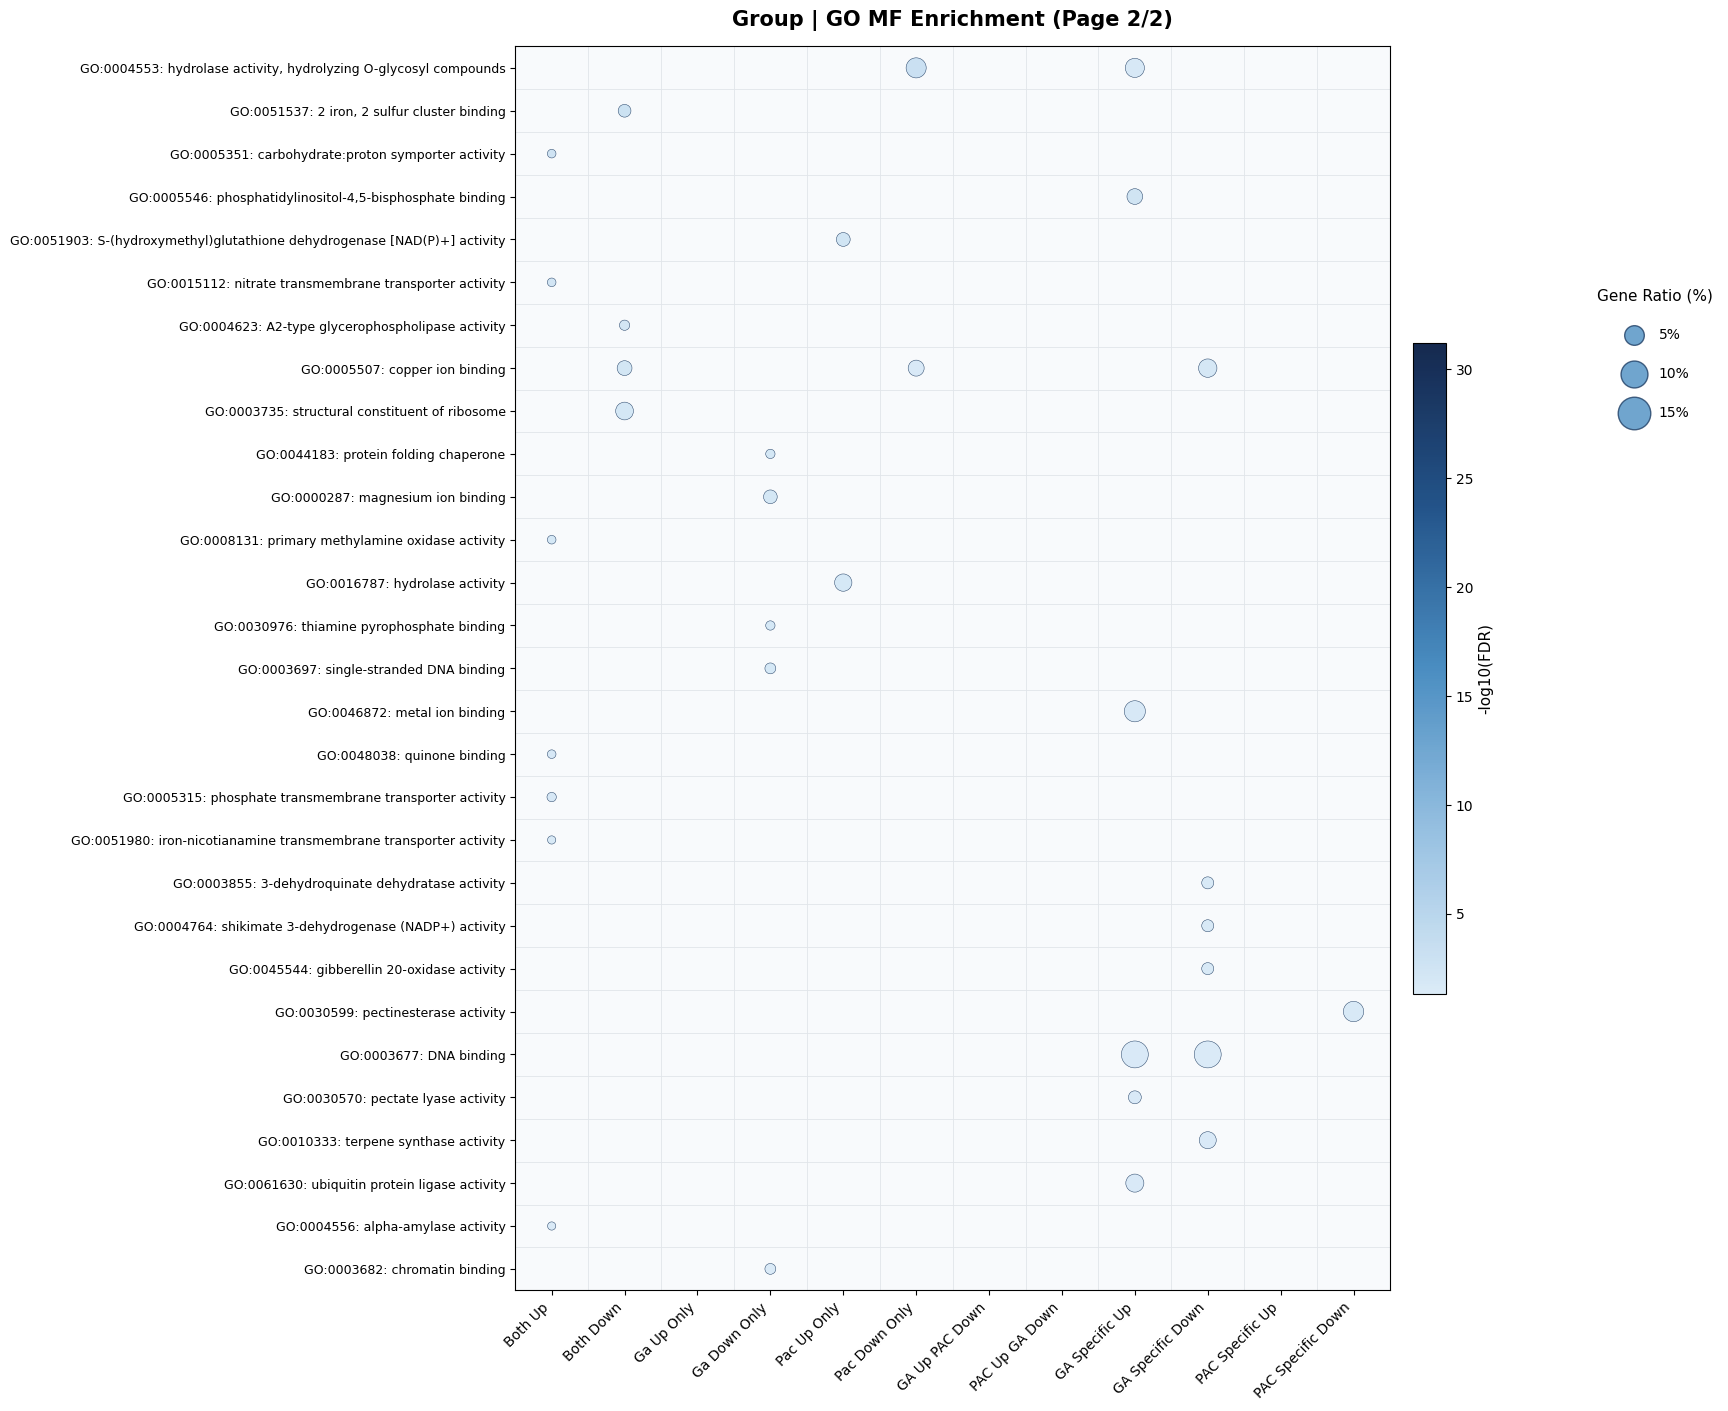


All Treatment and Group GO Bubble Heatmaps saved successfully.


In [31]:
enrichment_sets = {
    "Treatment": enrichment_dfs,
    "Group": group_enrichment
}

categories = {
    "Process": "BP",
    "Component": "CC",
    "Function": "MF"
}

FDR_CUTOFF = 0.05
ROWS_PER_IMAGE = 35
SHOW_PLOTS = True

BASE_OUTPUT_DIR = Path("GO_Bubble_Heatmaps")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_columns = {
    "Category", "GO_ID", "GO_term",
    "FDR", "Gene_Ratio"
}

# =====================================================
# 2. PREPARE BOTH DATASETS
# =====================================================

prepared_sets = {}
all_results = []

for analysis_name, enrichment_data in enrichment_sets.items():

    selected_groups = list(enrichment_data.keys())
    prepared = []

    for group_name in selected_groups:

        df = enrichment_data[group_name].copy()

        if df.empty:
            continue

        missing = required_columns - set(df.columns)

        if missing:
            raise ValueError(
                f"{analysis_name} / {group_name} "
                f"missing columns: {missing}"
            )

        df["FDR"] = pd.to_numeric(
            df["FDR"], errors="coerce"
        )

        df["Gene_Ratio"] = pd.to_numeric(
            df["Gene_Ratio"], errors="coerce"
        )

        df = df[
            (df["Category"].isin(categories)) &
            (df["FDR"] >= 0) &
            (df["FDR"] < FDR_CUTOFF) &
            (df["Gene_Ratio"].between(0, 1))
        ].copy()

        if df.empty:
            continue

        df["Group"] = group_name

        # Existing ratio, converted to percent
        df["Gene_Percent"] = df["Gene_Ratio"] * 100

        # Significance score
        df["Score"] = -np.log10(
            df["FDR"].clip(lower=1e-300)
        )

        prepared.append(df)

    if not prepared:
        print(f"No significant GO terms: {analysis_name}")
        continue

    data = pd.concat(prepared, ignore_index=True)

    data = (
        data.sort_values("FDR")
        .drop_duplicates(
            ["Category", "GO_ID", "Group"]
        )
        .reset_index(drop=True)
    )

    prepared_sets[analysis_name] = {
        "data": data,
        "groups": selected_groups
    }

    all_results.append(data)

if not all_results:
    raise ValueError("No significant GO terms found.")

combined_data = pd.concat(
    all_results,
    ignore_index=True
)

# =====================================================
# 3. GLOBAL COLOR AND SIZE SCALES
# =====================================================

# Same scales for Treatment and Group

cmap = LinearSegmentedColormap.from_list(
    "blue_significance",
    [
        "#D9EAF7",
        "#91BDE0",
        "#4087BE",
        "#174A83",
        "#081D45"
    ]
)

score_min = -np.log10(FDR_CUTOFF)
score_max = max(
    combined_data["Score"].max(),
    score_min + 0.1
)

norm = Normalize(
    vmin=score_min,
    vmax=score_max
)

max_percent = combined_data["Gene_Percent"].max()

def bubble_size(percent):
    """Consistent marker area for all plots."""
    return (
        25 +
        650 * np.asarray(percent) /
        max(max_percent, 1e-10)
    )

# =====================================================
# 4. BUBBLE SIZE LEGEND
# =====================================================

def get_legend_values(max_pct):

    if max_pct >= 15:
        values = [5, 10, 15]
    elif max_pct >= 10:
        values = [2, 5, 10]
    elif max_pct >= 5:
        values = [1, 2, 5]
    elif max_pct >= 2:
        values = [0.5, 1, 2]
    elif max_pct >= 1:
        values = [0.25, 0.5, 1]
    elif max_pct >= 0.5:
        values = [0.1, 0.25, 0.5]
    else:
        values = [
            max_pct / 3,
            max_pct * 2 / 3,
            max_pct
        ]

    return [
        v for v in values
        if v > 0 and v <= max_pct
    ]

legend_values = get_legend_values(max_percent)

# =====================================================
# 5. PLOTTING FUNCTION
# =====================================================

def plot_go_bubble_heatmaps(
    analysis_name,
    data,
    selected_groups
):

    output_dir = BASE_OUTPUT_DIR / analysis_name
    output_dir.mkdir(parents=True, exist_ok=True)

    print(f"\n{'=' * 60}")
    print(f"Analysis: {analysis_name}")
    print(f"Groups: {len(selected_groups)}")
    print(f"{'=' * 60}")

    for category, short_name in categories.items():

        sub = data[
            data["Category"] == category
        ].copy()

        if sub.empty:
            print(f"No significant terms for {short_name}")
            continue

        # ---------------------------------------------
        # Rank GO terms by minimum FDR across groups
        # ---------------------------------------------

        ranking = (
            sub.groupby("GO_ID", as_index=False)
            .agg(
                GO_term=("GO_term", "first"),
                Best_FDR=("FDR", "min")
            )
            .sort_values(
                ["Best_FDR", "GO_ID"],
                ascending=[True, True]
            )
            .reset_index(drop=True)
        )

        print(
            f"{short_name}: "
            f"{len(ranking)} significant GO terms"
        )

        # Split into pages
        pages = [
            ranking.iloc[i:i + ROWS_PER_IMAGE]
            for i in range(
                0,
                len(ranking),
                ROWS_PER_IMAGE
            )
        ]

        for page_num, current in enumerate(
            pages, start=1
        ):

            current_ids = current["GO_ID"].tolist()

            plot_df = sub[
                sub["GO_ID"].isin(current_ids)
            ].copy()

            x_map = {
                name: i
                for i, name in enumerate(selected_groups)
            }

            y_map = {
                go_id: i
                for i, go_id in enumerate(current_ids)
            }

            plot_df["x"] = plot_df["Group"].map(x_map)
            plot_df["y"] = plot_df["GO_ID"].map(y_map)

            # -----------------------------------------
            # Figure dimensions
            # -----------------------------------------

            n_terms = len(current)

            fig_height = max(
                7,
                n_terms * 0.44 + 2.5
            )

            fig_width = max(
                13,
                len(selected_groups) * 1.15 + 6
            )

            fig, ax = plt.subplots(
                figsize=(fig_width, fig_height)
            )

            fig.subplots_adjust(
                left=0.35,
                right=0.82,
                top=0.92,
                bottom=min(
                    0.24,
                    max(0.10, 1.6 / fig_height)
                )
            )

            # -----------------------------------------
            # Bubble plot
            # -----------------------------------------

            scatter = ax.scatter(
                plot_df["x"],
                plot_df["y"],
                s=bubble_size(
                    plot_df["Gene_Percent"]
                ),
                c=plot_df["Score"],
                cmap=cmap,
                norm=norm,
                edgecolors="#17365D",
                linewidths=0.35,
                alpha=0.95
            )

            # -----------------------------------------
            # Axis labels
            # -----------------------------------------

            y_labels = [
                f"{row.GO_ID}: {row.GO_term}"
                for row in current.itertuples()
            ]

            x_labels = [
                name.replace("_", " ").title()
                if "_" in name else name
                for name in selected_groups
            ]

            ax.set_xticks(
                range(len(selected_groups))
            )

            ax.set_xticklabels(
                x_labels,
                rotation=45,
                ha="right",
                fontsize=10
            )

            ax.set_yticks(range(n_terms))

            ax.set_yticklabels(
                y_labels,
                fontsize=9
            )

            # Most significant GO term at top
            ax.set_ylim(
                n_terms - 0.5,
                -0.5
            )

            ax.set_xlim(
                -0.5,
                len(selected_groups) - 0.5
            )

            # -----------------------------------------
            # Grid
            # -----------------------------------------

            ax.set_xticks(
                np.arange(
                    -0.5,
                    len(selected_groups),
                    1
                ),
                minor=True
            )

            ax.set_yticks(
                np.arange(
                    -0.5,
                    n_terms,
                    1
                ),
                minor=True
            )

            ax.grid(
                which="minor",
                color="#E1E5EA",
                linewidth=0.6
            )

            ax.tick_params(
                which="minor",
                bottom=False,
                left=False
            )

            ax.set_axisbelow(True)
            ax.set_facecolor("#F8FAFC")

            # -----------------------------------------
            # Title
            # -----------------------------------------

            ax.set_title(
                f"{analysis_name} | GO {short_name} "
                f"Enrichment (Page {page_num}/{len(pages)})",
                fontsize=15,
                fontweight="bold",
                pad=15
            )

            # -----------------------------------------
            # Colorbar
            # -----------------------------------------

            cbar = fig.colorbar(
                scatter,
                ax=ax,
                fraction=0.035,
                pad=0.025
            )

            cbar.set_label(
                "-log10(FDR)",
                fontsize=11
            )

            # -----------------------------------------
            # Gene Ratio (%) legend
            # -----------------------------------------

            handles = [
                ax.scatter(
                    [],
                    [],
                    s=bubble_size(v),
                    color="#4087BE",
                    edgecolor="#17365D",
                    alpha=0.75
                )
                for v in legend_values
            ]

            if handles:
                fig.legend(
                    handles,
                    [f"{v:g}%" for v in legend_values],
                    title="Gene Ratio (%)",
                    loc="upper left",
                    bbox_to_anchor=(0.89, 0.77),
                    frameon=False,
                    labelspacing=1.8,
                    fontsize=10,
                    title_fontsize=11
                )

            # -----------------------------------------
            # Save PNG only
            # -----------------------------------------

            filename = (
                f"GO_{short_name}_Bubble_"
                f"{page_num:02d}.png"
            )

            save_path = output_dir / filename

            fig.savefig(
                save_path,
                dpi=300,
                bbox_inches="tight",
                pad_inches=0.25,
                facecolor="white"
            )

            print("Saved:", save_path)

            if SHOW_PLOTS:
                plt.show()

            plt.close(fig)

# =====================================================
# 6. AUTOMATICALLY PLOT BOTH ANALYSES
# =====================================================

for analysis_name, content in prepared_sets.items():

    plot_go_bubble_heatmaps(
        analysis_name=analysis_name,
        data=content["data"],
        selected_groups=content["groups"]
    )

print(
    "\nAll Treatment and Group GO Bubble Heatmaps "
    "saved successfully."
)


### plot lollipop

Saved: GO_Lollipop_Plots\Treatment\GA_Up_BP_Lollipop.png


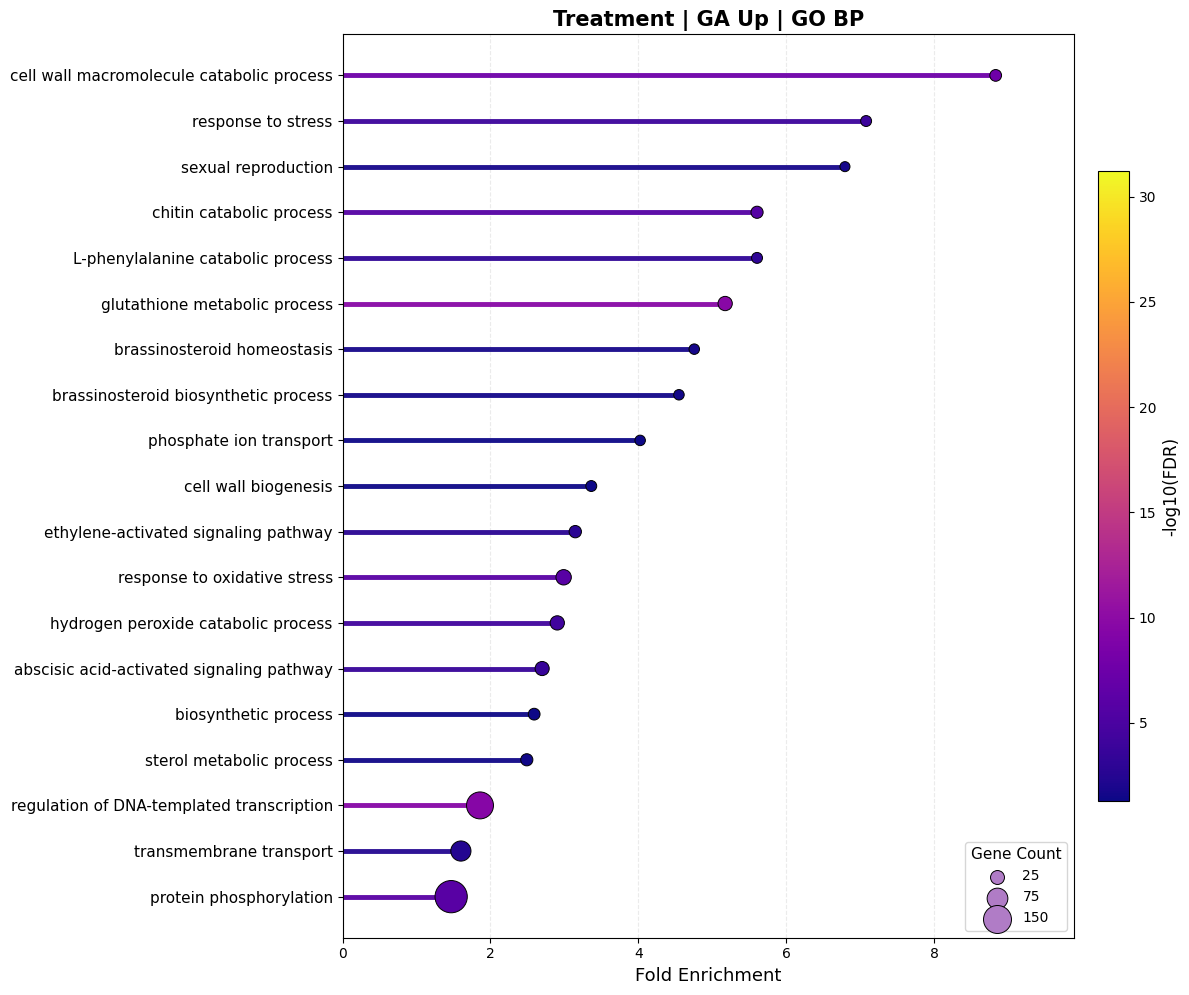

Saved: GO_Lollipop_Plots\Treatment\GA_Up_MF_Lollipop.png


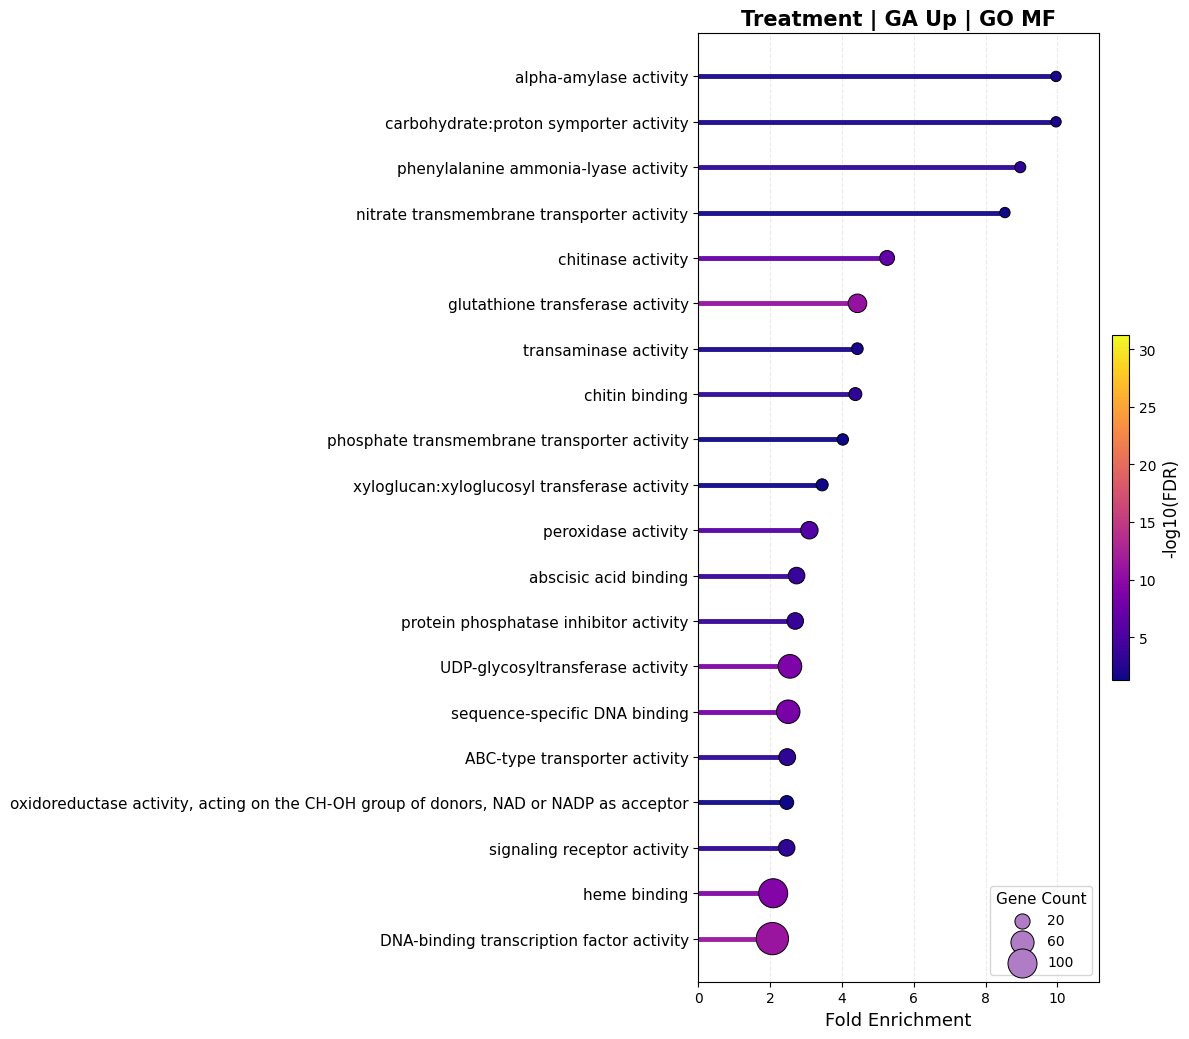

Saved: GO_Lollipop_Plots\Treatment\GA_Up_CC_Lollipop.png


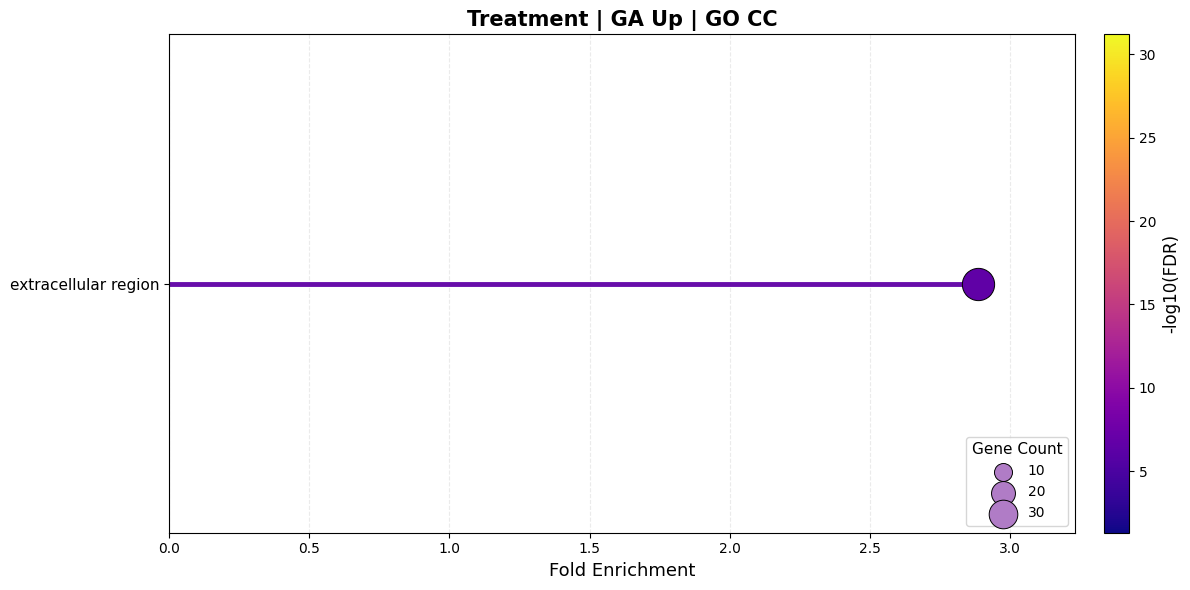

Saved: GO_Lollipop_Plots\Treatment\GA_Down_BP_Lollipop.png


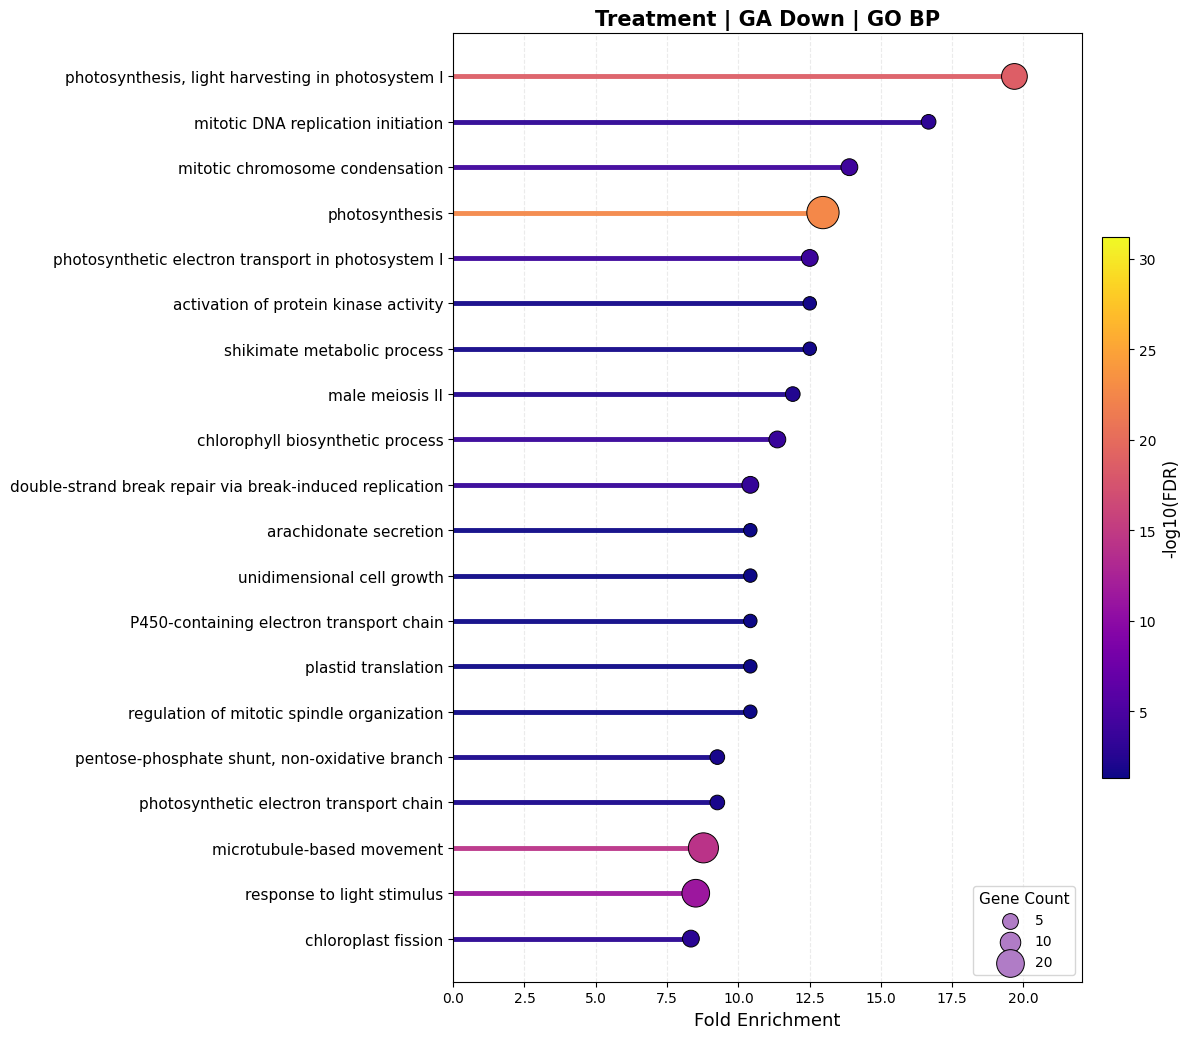

C:\Users\farsh\AppData\Local\Temp\ipykernel_21156\1271373971.py:238: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


Saved: GO_Lollipop_Plots\Treatment\GA_Down_MF_Lollipop.png


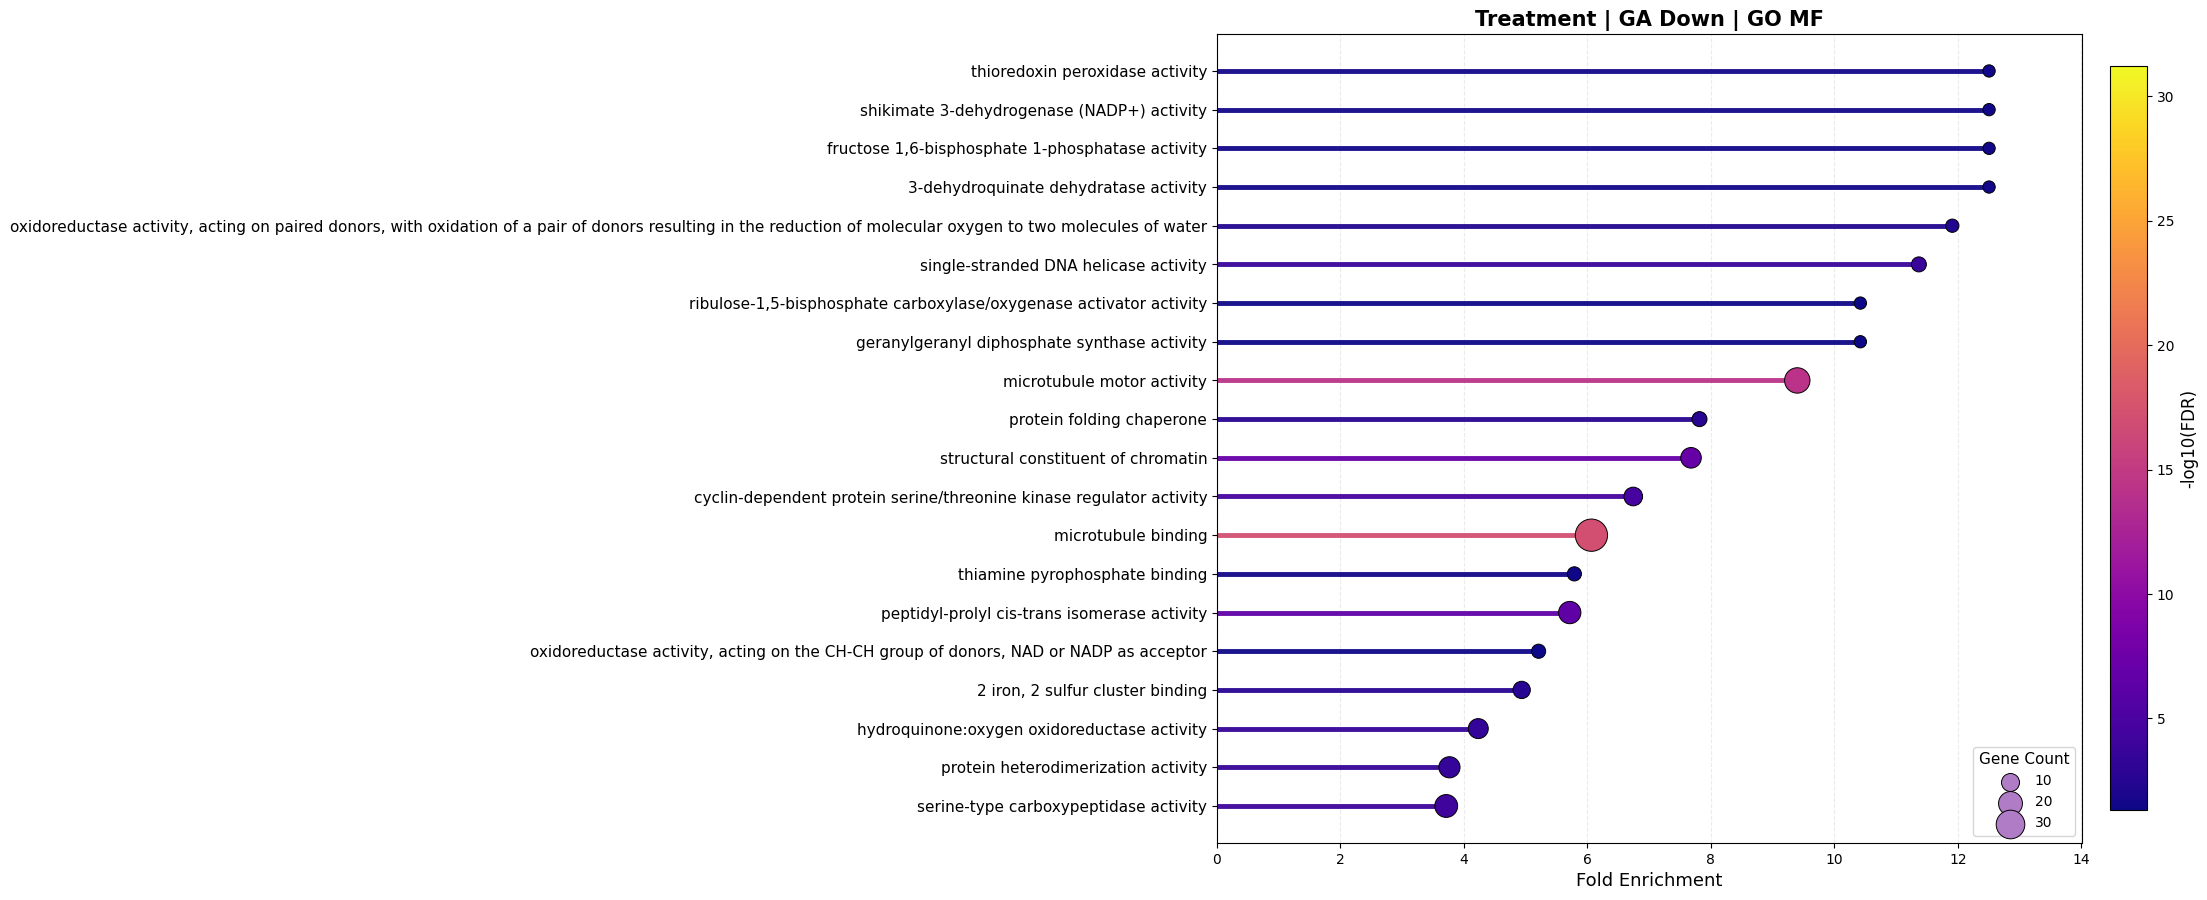

Saved: GO_Lollipop_Plots\Treatment\GA_Down_CC_Lollipop.png


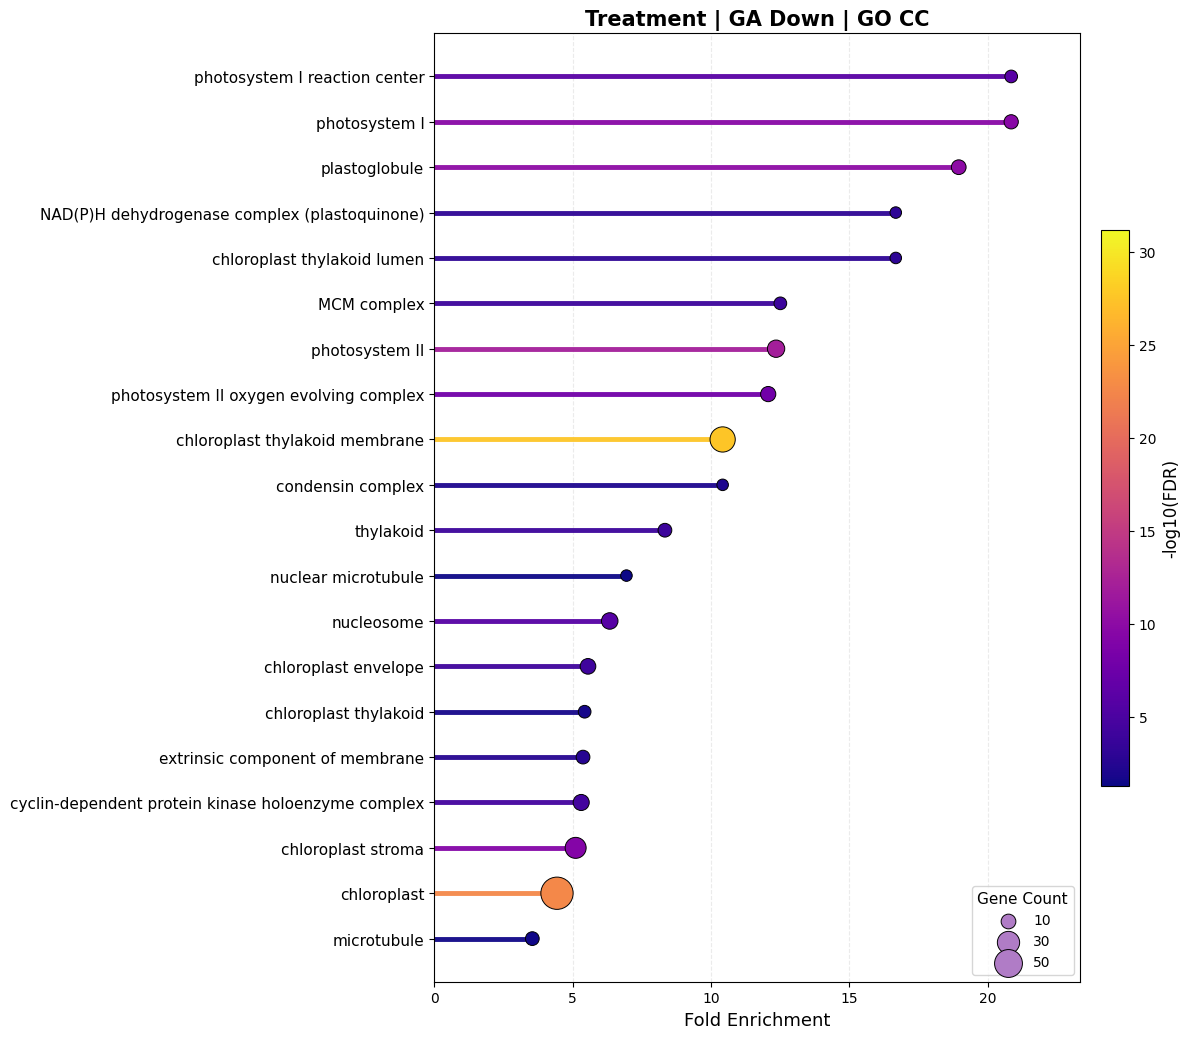

Saved: GO_Lollipop_Plots\Treatment\PAC_Up_BP_Lollipop.png


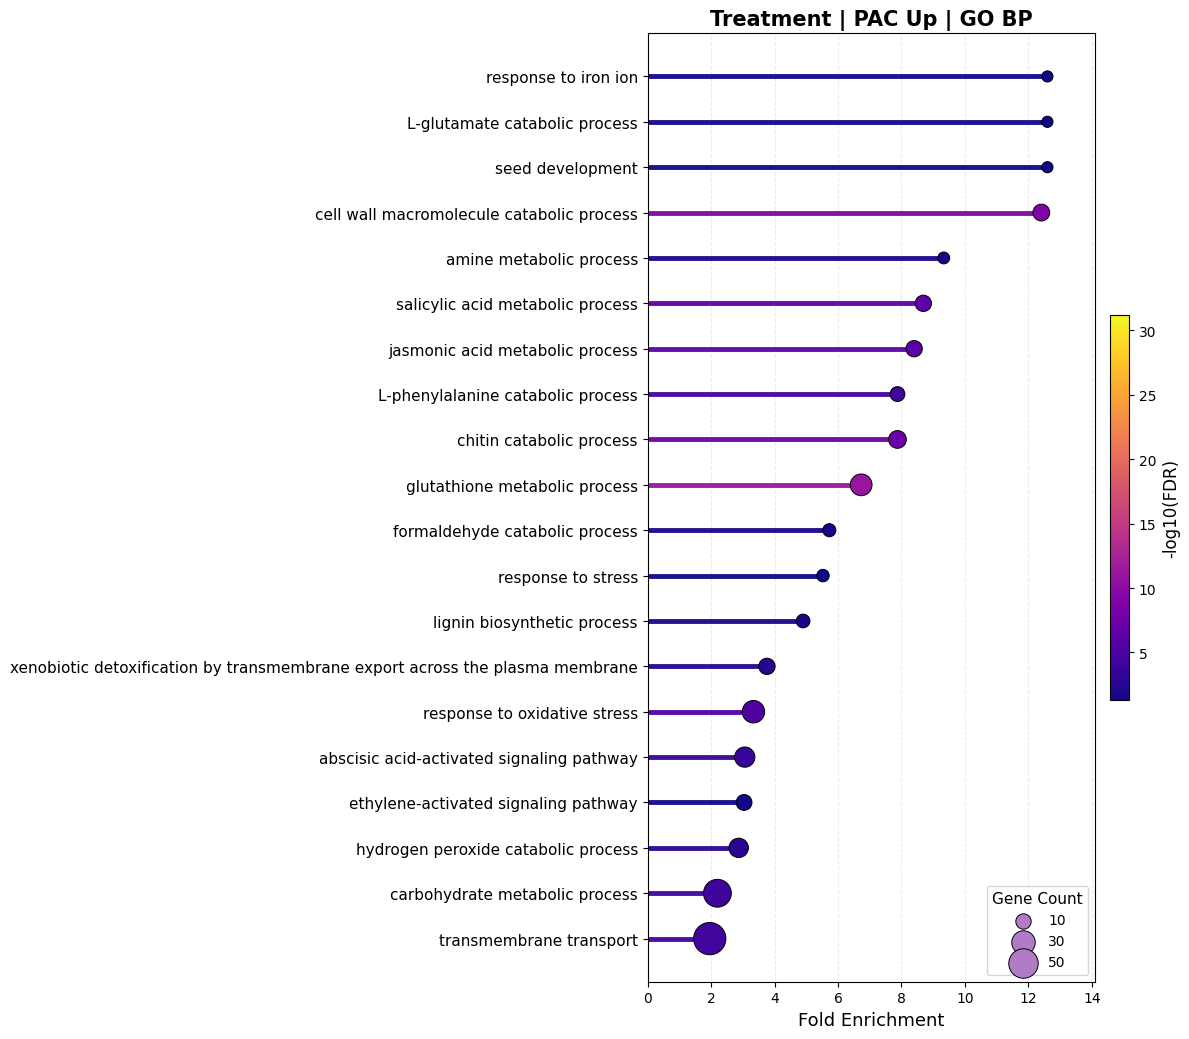

Saved: GO_Lollipop_Plots\Treatment\PAC_Up_MF_Lollipop.png


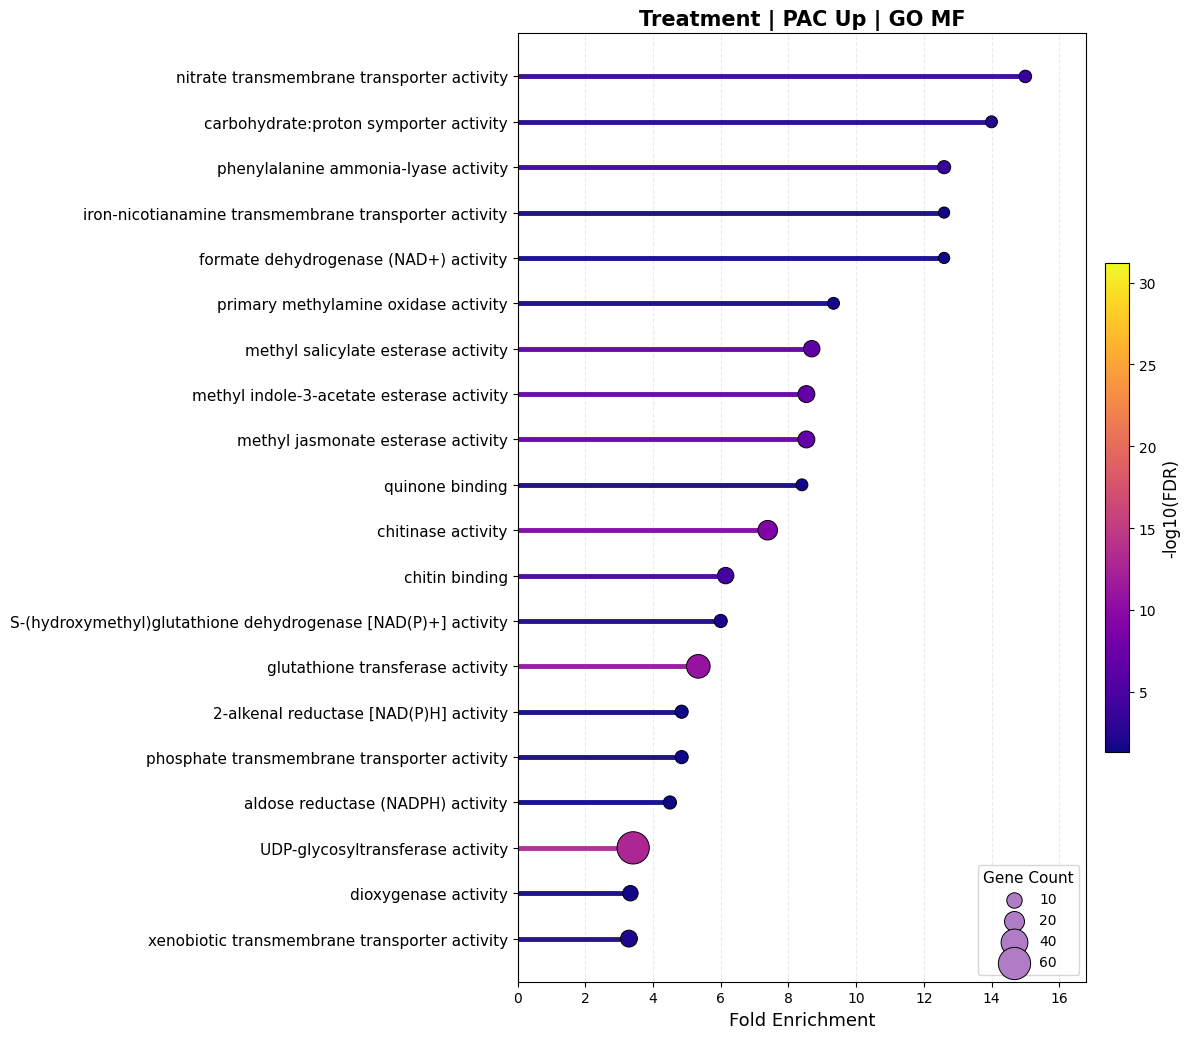

Saved: GO_Lollipop_Plots\Treatment\PAC_Up_CC_Lollipop.png


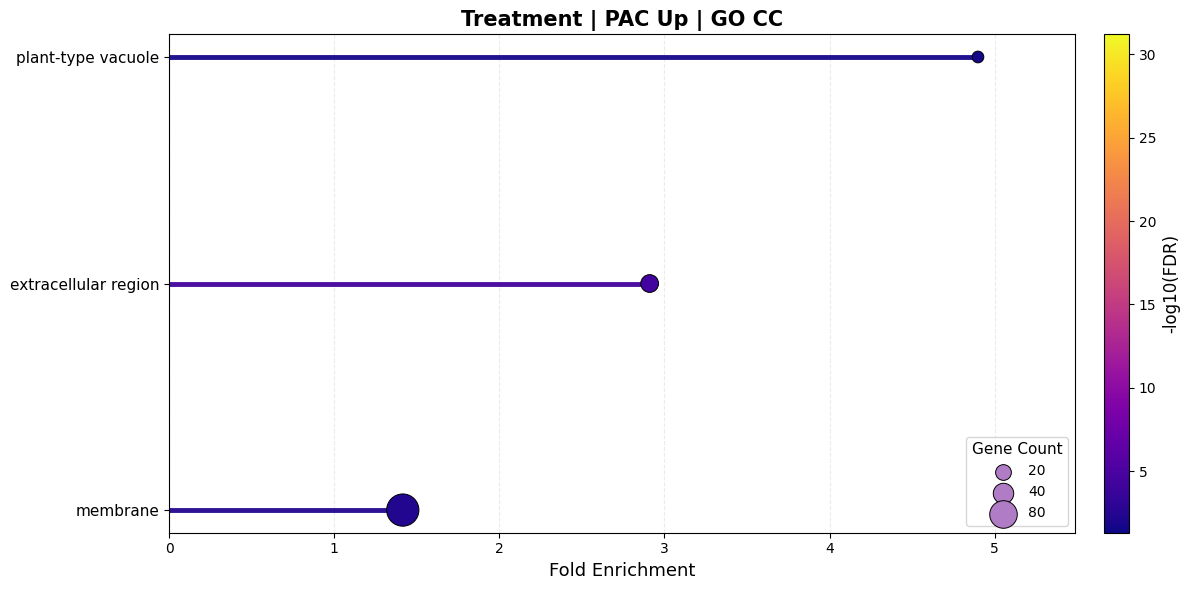

Saved: GO_Lollipop_Plots\Treatment\PAC_Down_BP_Lollipop.png


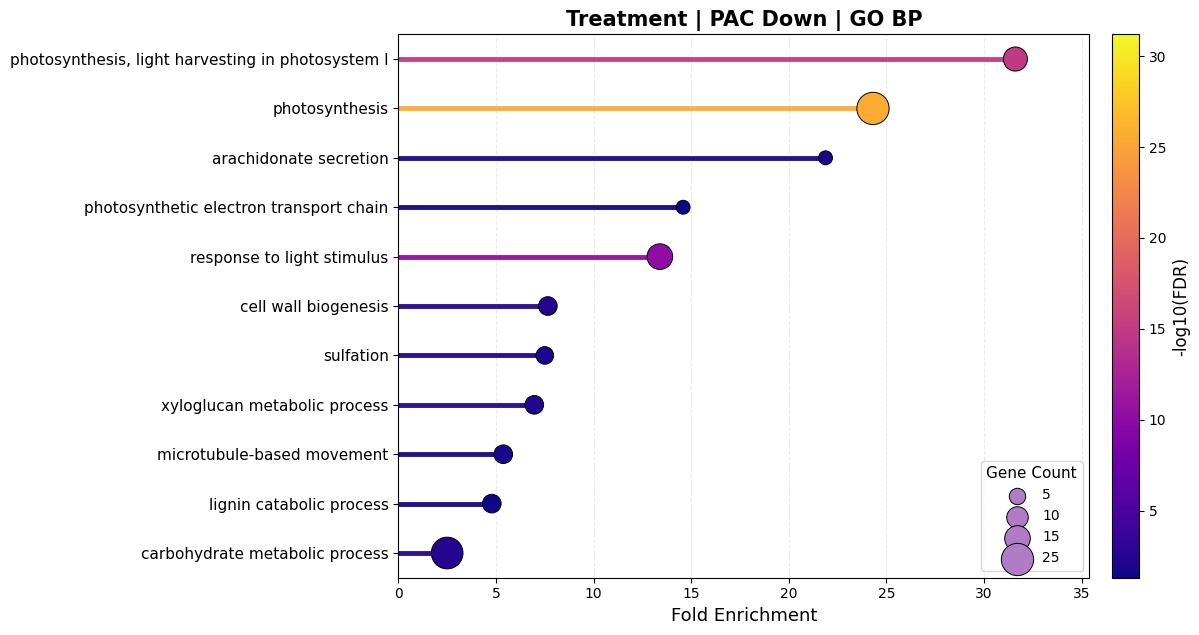

C:\Users\farsh\AppData\Local\Temp\ipykernel_21156\1271373971.py:238: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


Saved: GO_Lollipop_Plots\Treatment\PAC_Down_MF_Lollipop.png


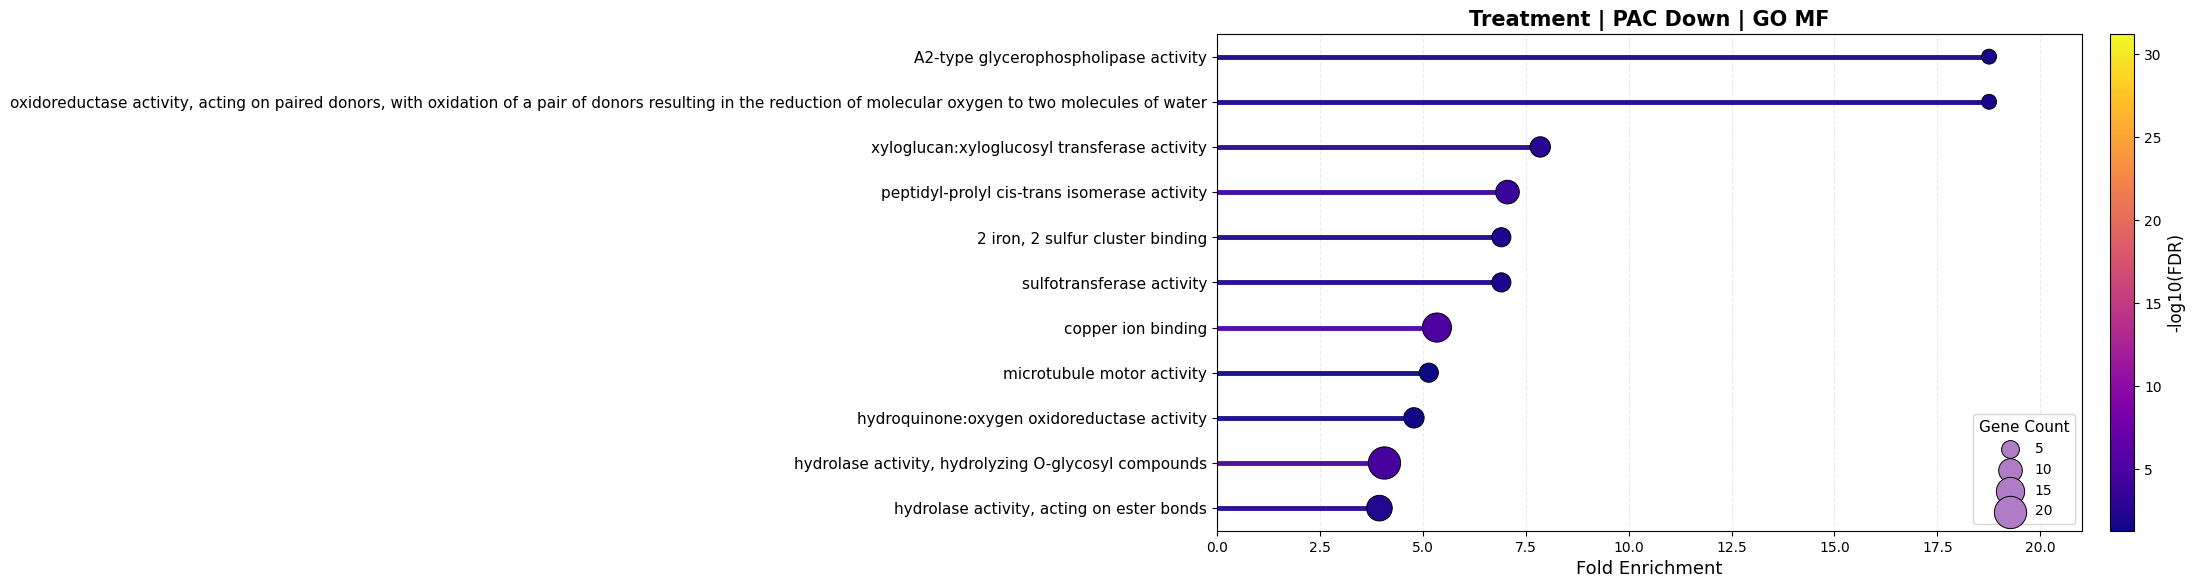

Saved: GO_Lollipop_Plots\Treatment\PAC_Down_CC_Lollipop.png


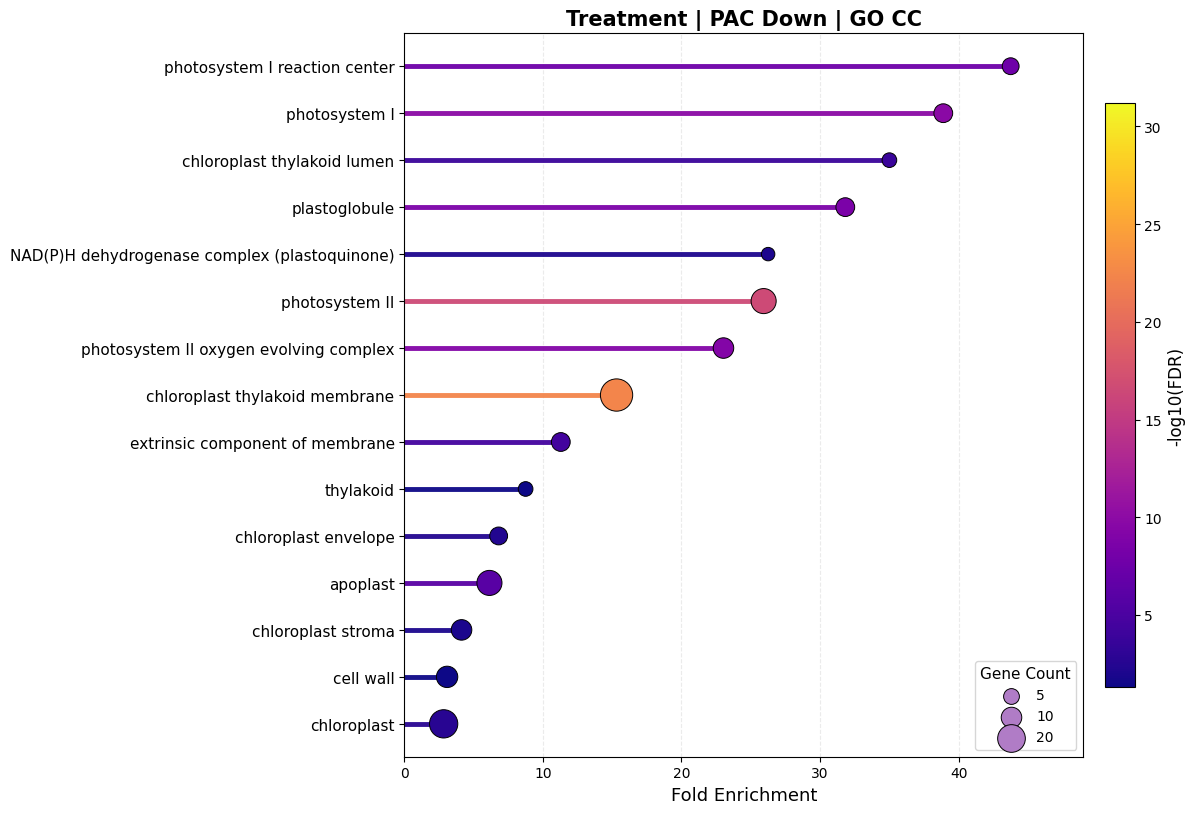

Saved: GO_Lollipop_Plots\Treatment\GA-PAC_Up_BP_Lollipop.png


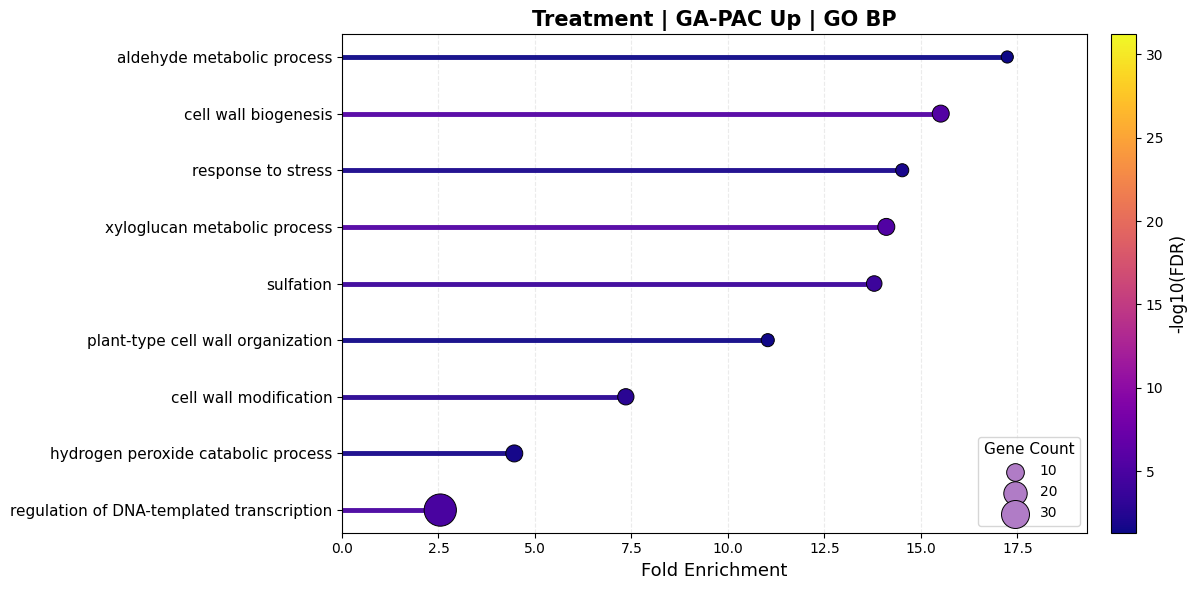

Saved: GO_Lollipop_Plots\Treatment\GA-PAC_Up_MF_Lollipop.png


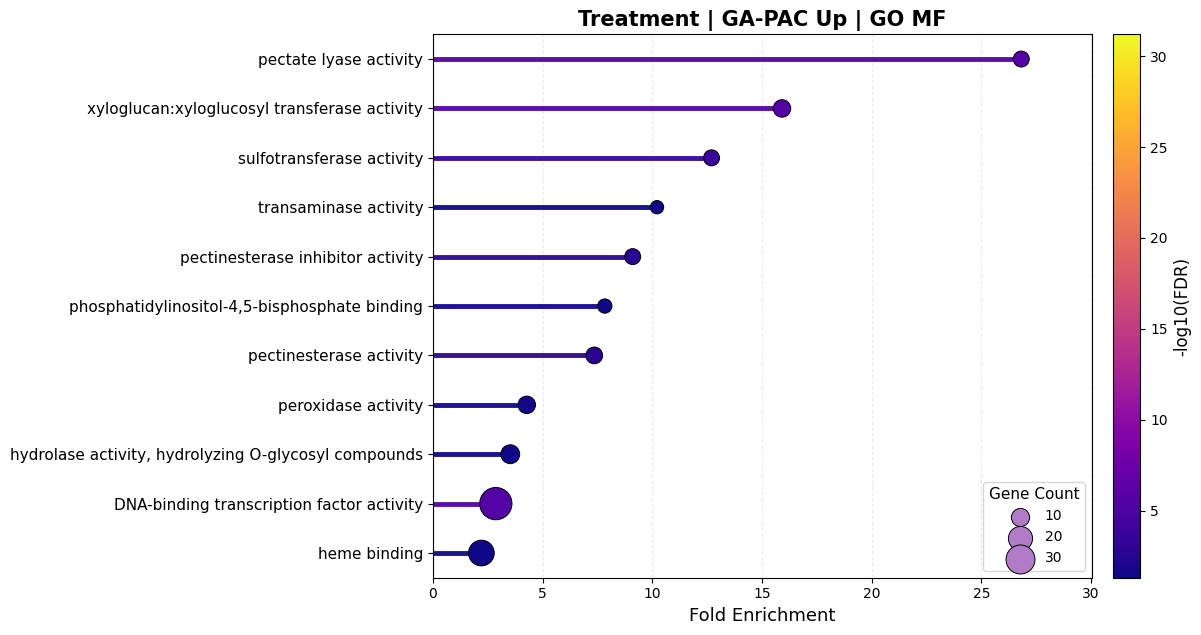

Saved: GO_Lollipop_Plots\Treatment\GA-PAC_Up_CC_Lollipop.png


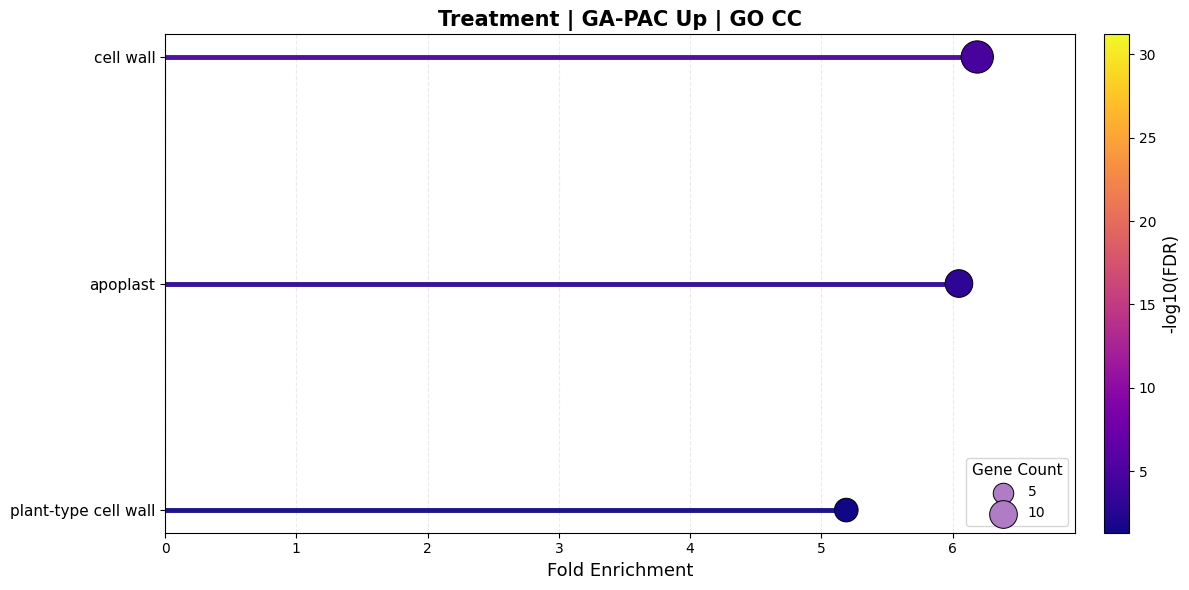

Saved: GO_Lollipop_Plots\Treatment\GA-PAC_Down_BP_Lollipop.png


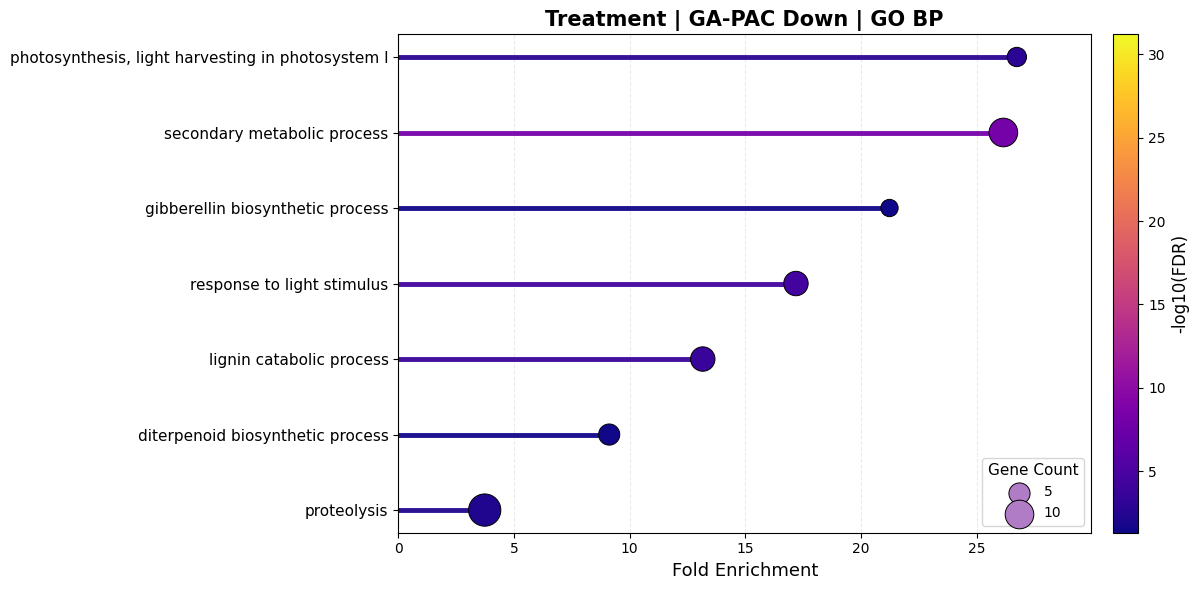

Saved: GO_Lollipop_Plots\Treatment\GA-PAC_Down_MF_Lollipop.png


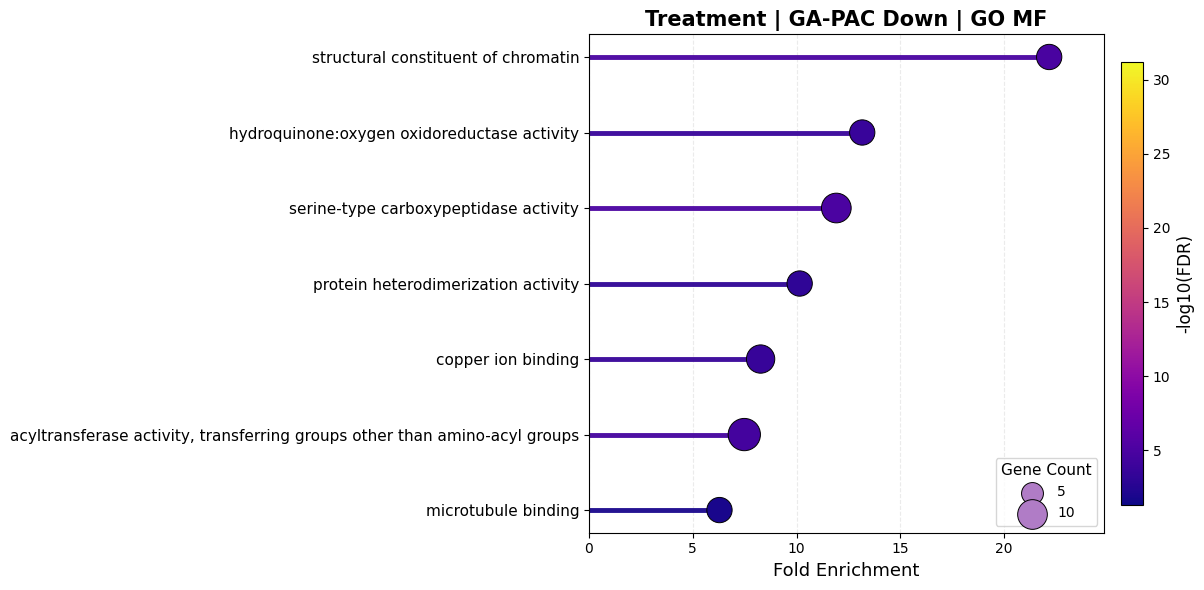

Saved: GO_Lollipop_Plots\Treatment\GA-PAC_Down_CC_Lollipop.png


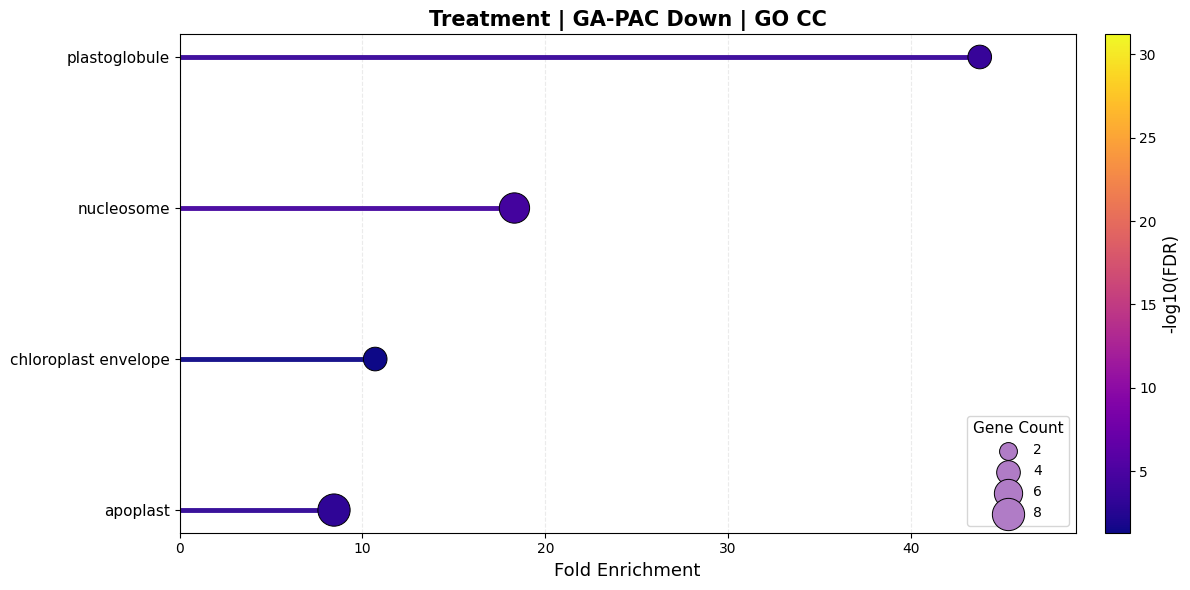

Saved: GO_Lollipop_Plots\Group\Both_Up_BP_Lollipop.png


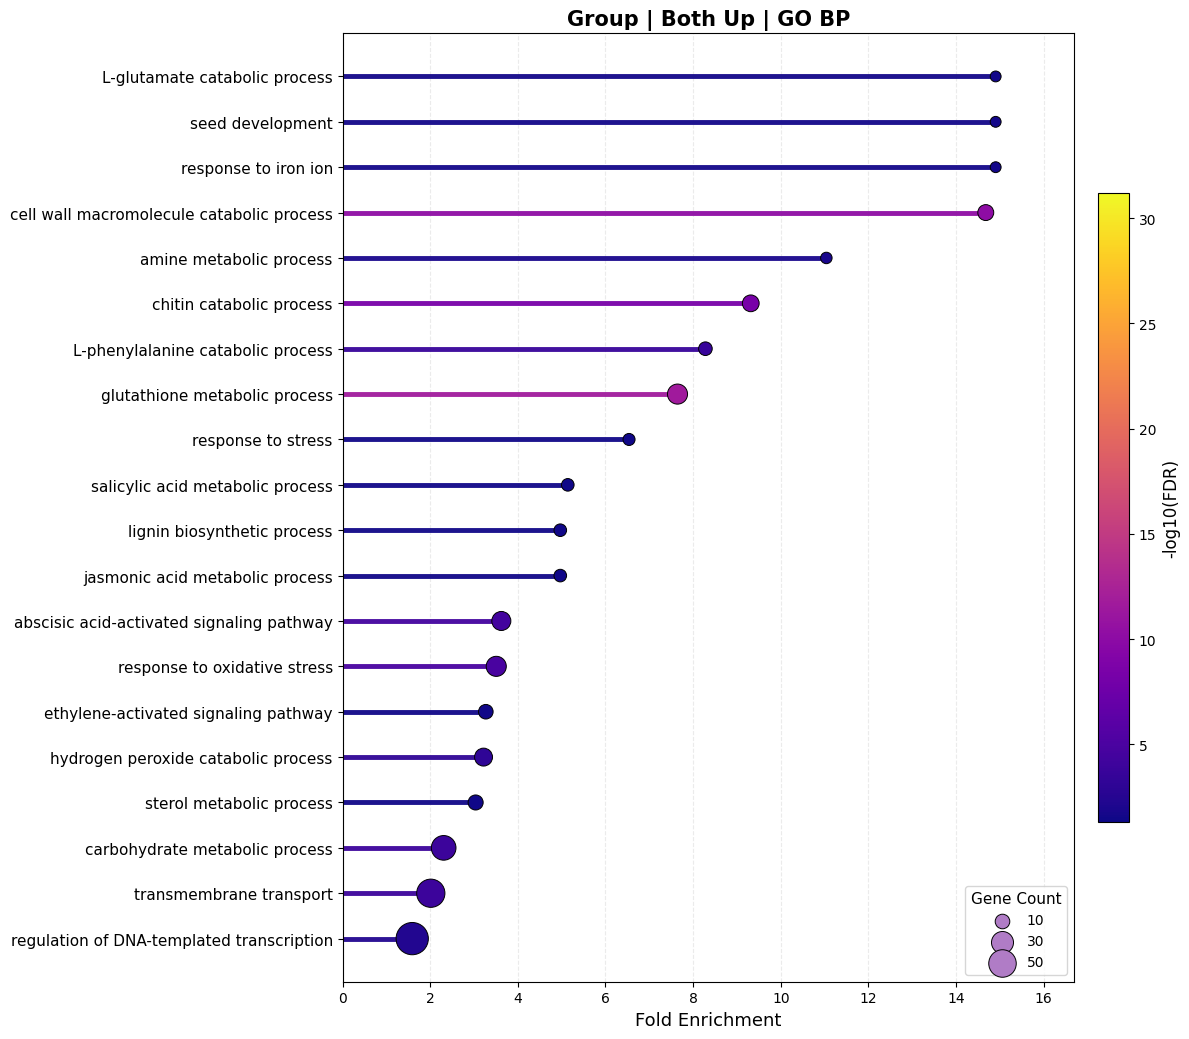

Saved: GO_Lollipop_Plots\Group\Both_Up_MF_Lollipop.png


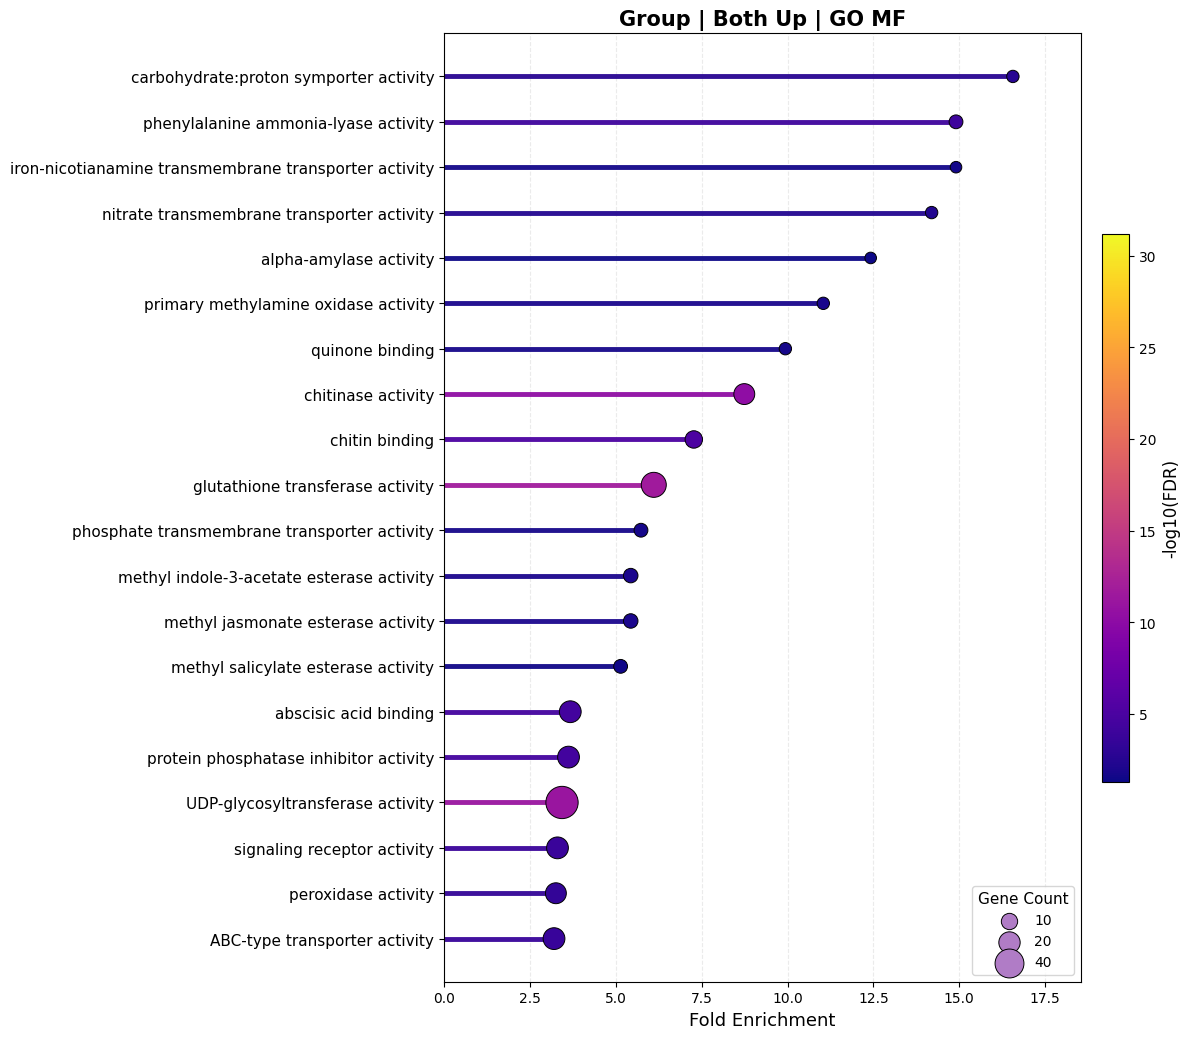

Saved: GO_Lollipop_Plots\Group\Both_Up_CC_Lollipop.png


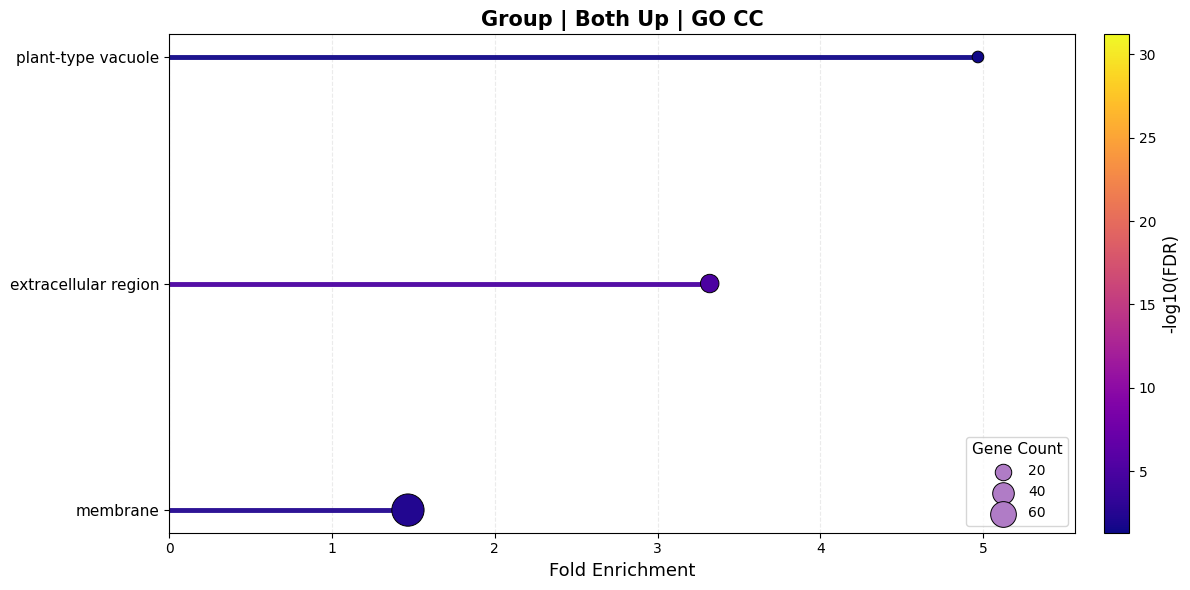

Saved: GO_Lollipop_Plots\Group\Both_Down_BP_Lollipop.png


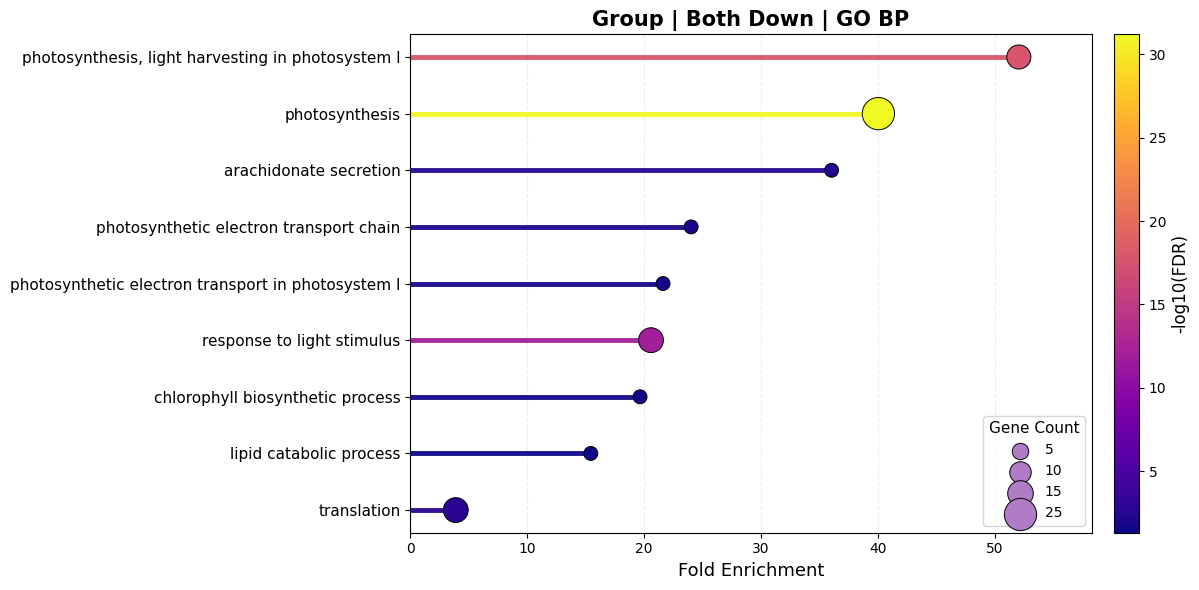

Saved: GO_Lollipop_Plots\Group\Both_Down_MF_Lollipop.png


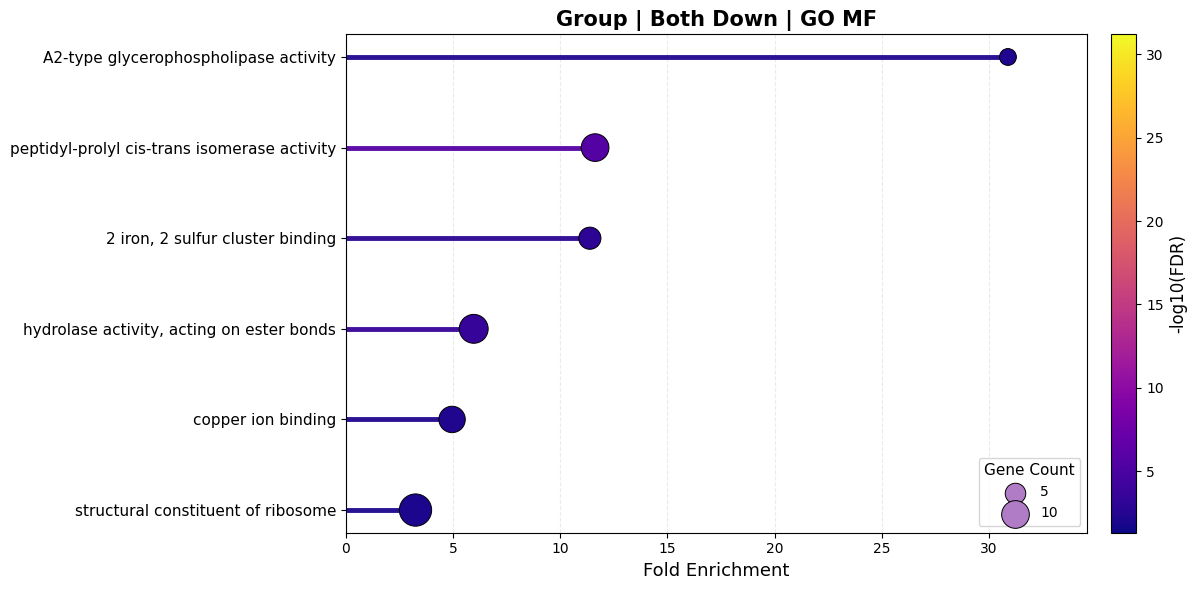

Saved: GO_Lollipop_Plots\Group\Both_Down_CC_Lollipop.png


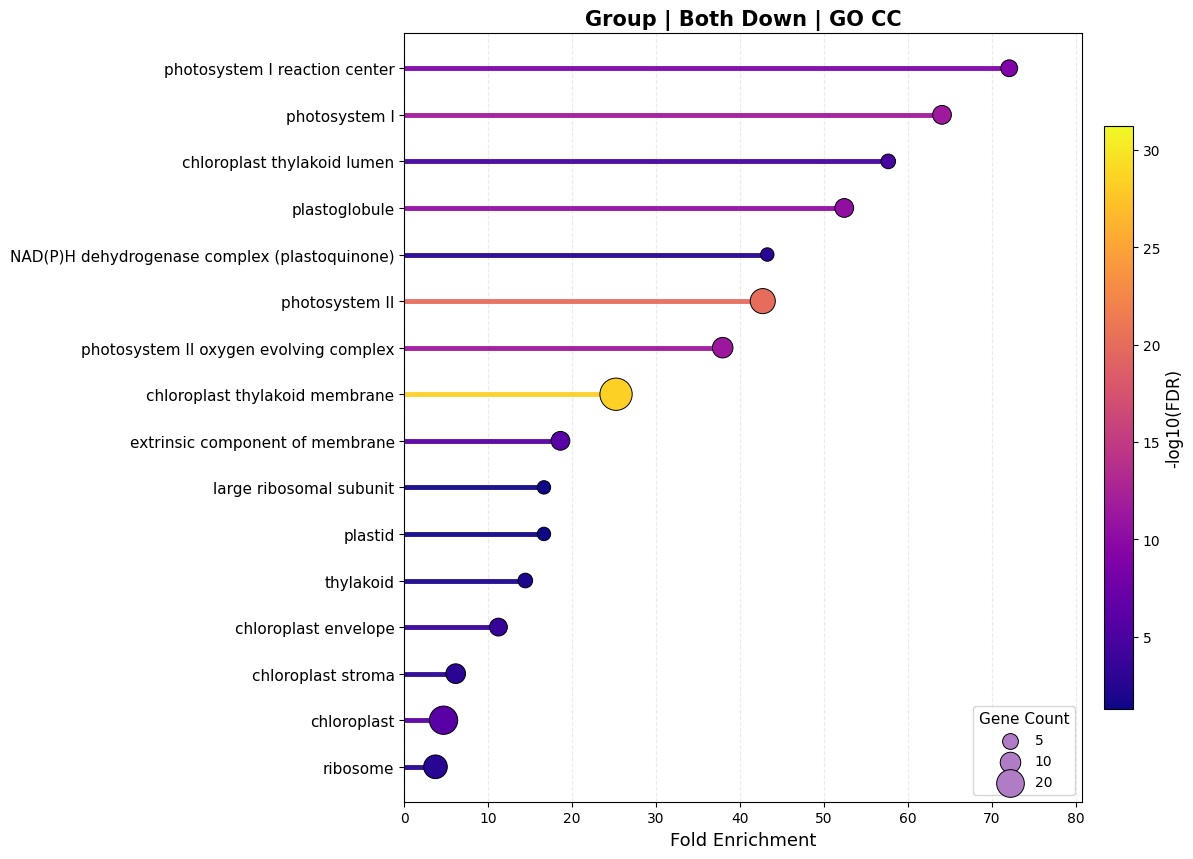

Saved: GO_Lollipop_Plots\Group\ga_up_only_BP_Lollipop.png


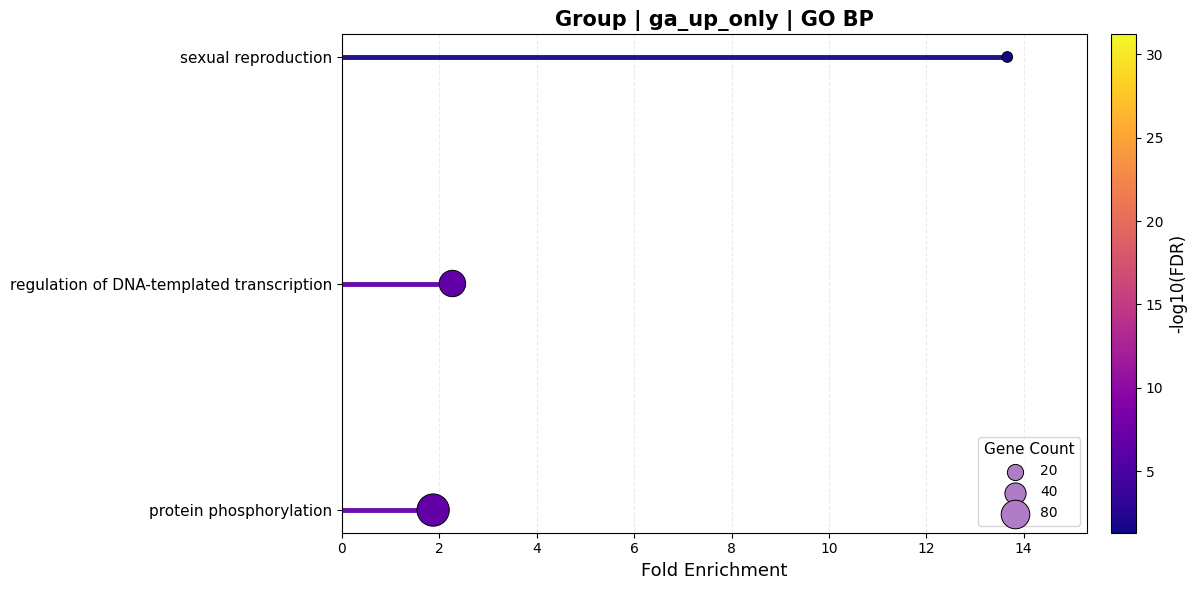

Saved: GO_Lollipop_Plots\Group\ga_up_only_MF_Lollipop.png


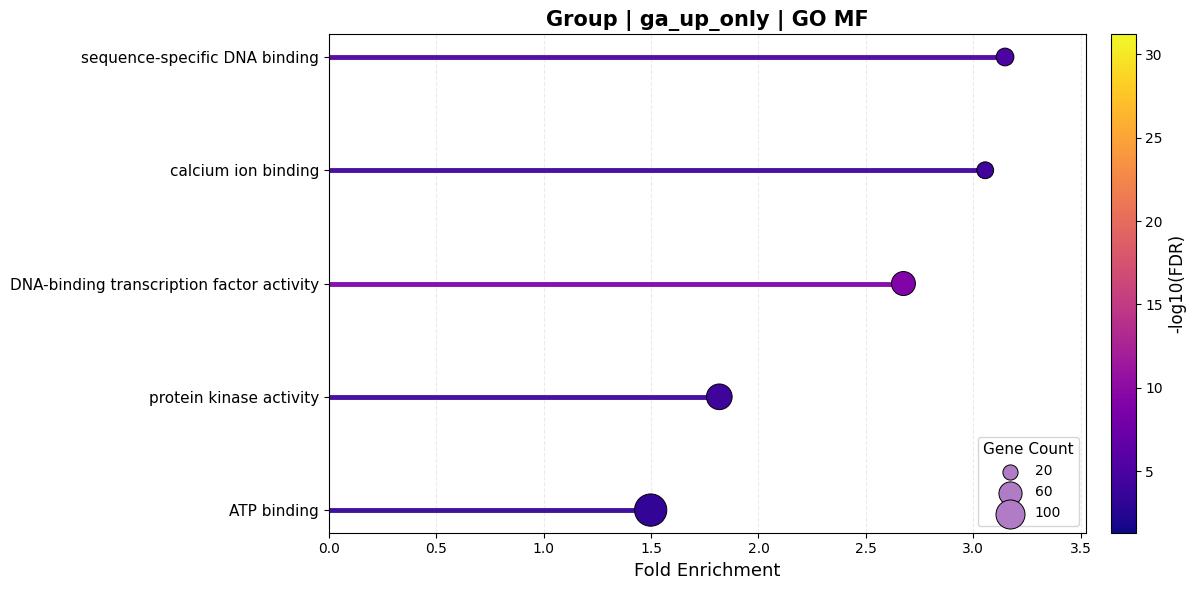

Saved: GO_Lollipop_Plots\Group\ga_down_only_BP_Lollipop.png


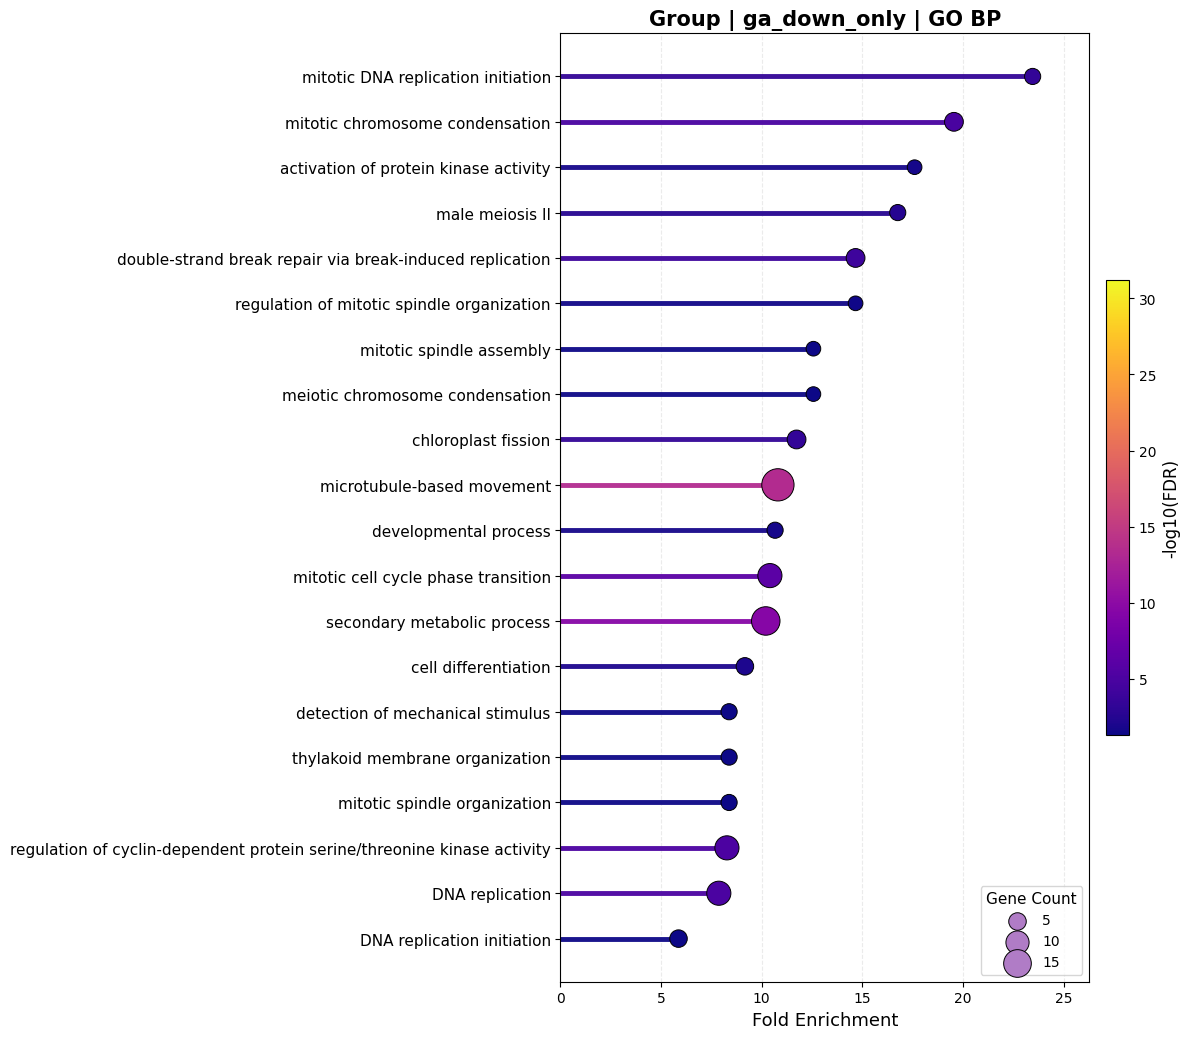

Saved: GO_Lollipop_Plots\Group\ga_down_only_MF_Lollipop.png


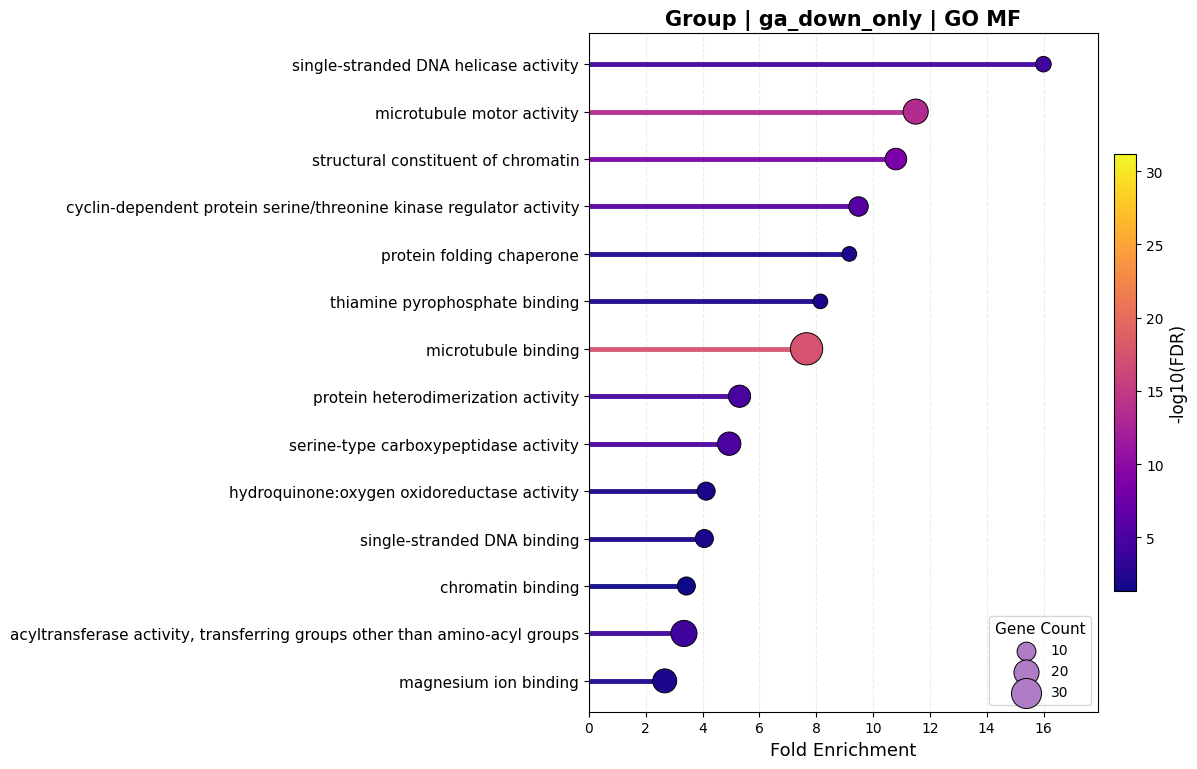

Saved: GO_Lollipop_Plots\Group\ga_down_only_CC_Lollipop.png


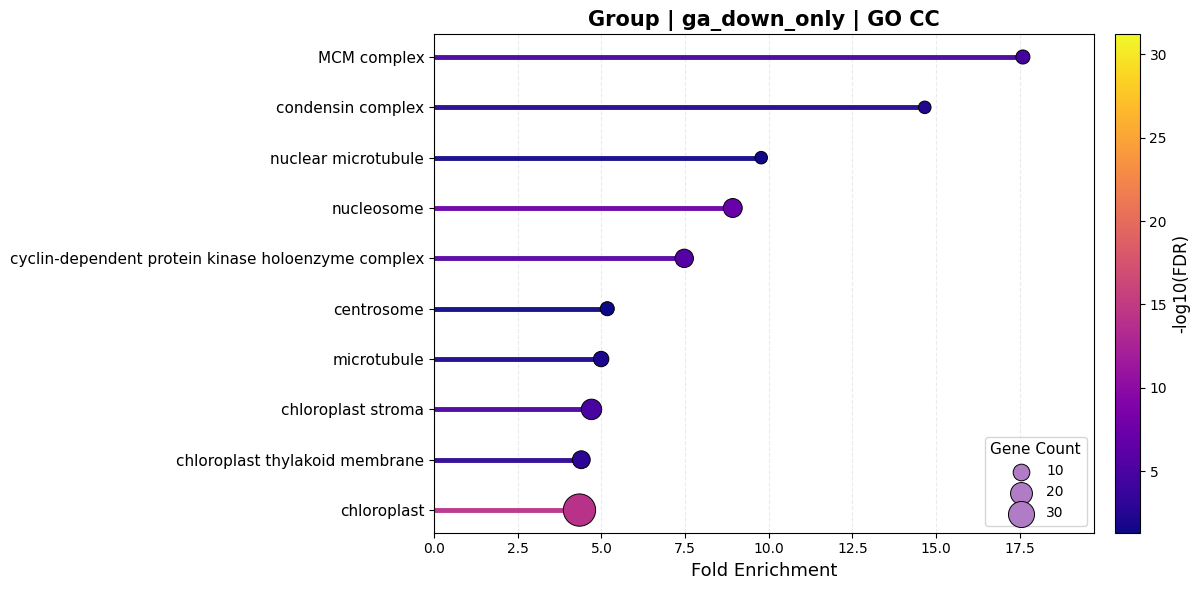

Saved: GO_Lollipop_Plots\Group\pac_up_only_BP_Lollipop.png


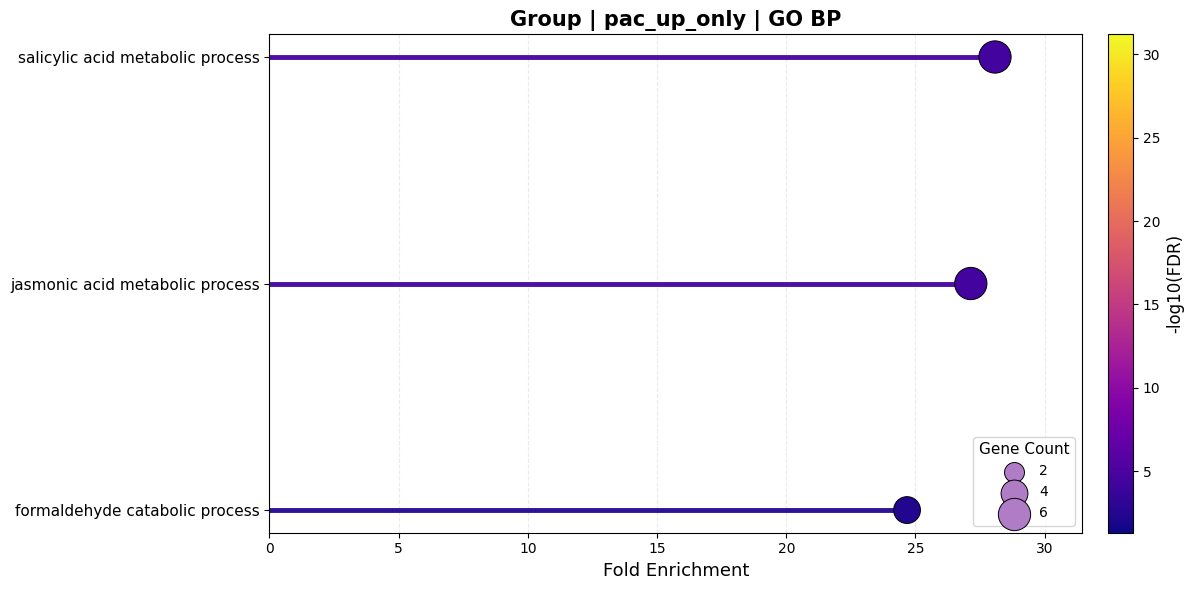

Saved: GO_Lollipop_Plots\Group\pac_up_only_MF_Lollipop.png


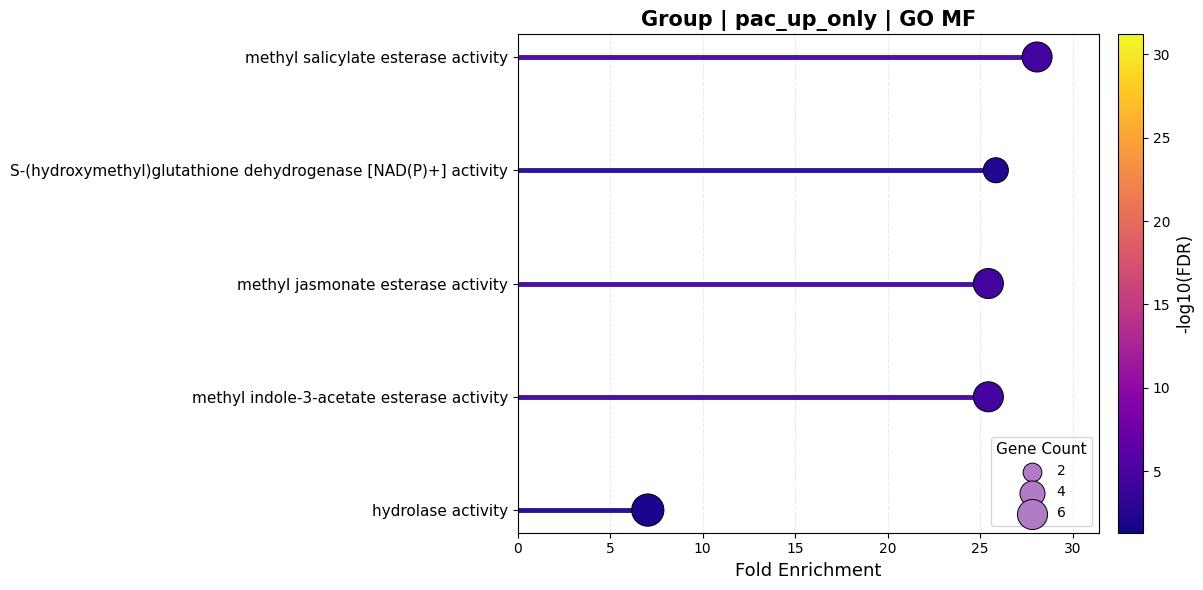

Saved: GO_Lollipop_Plots\Group\pac_down_only_BP_Lollipop.png


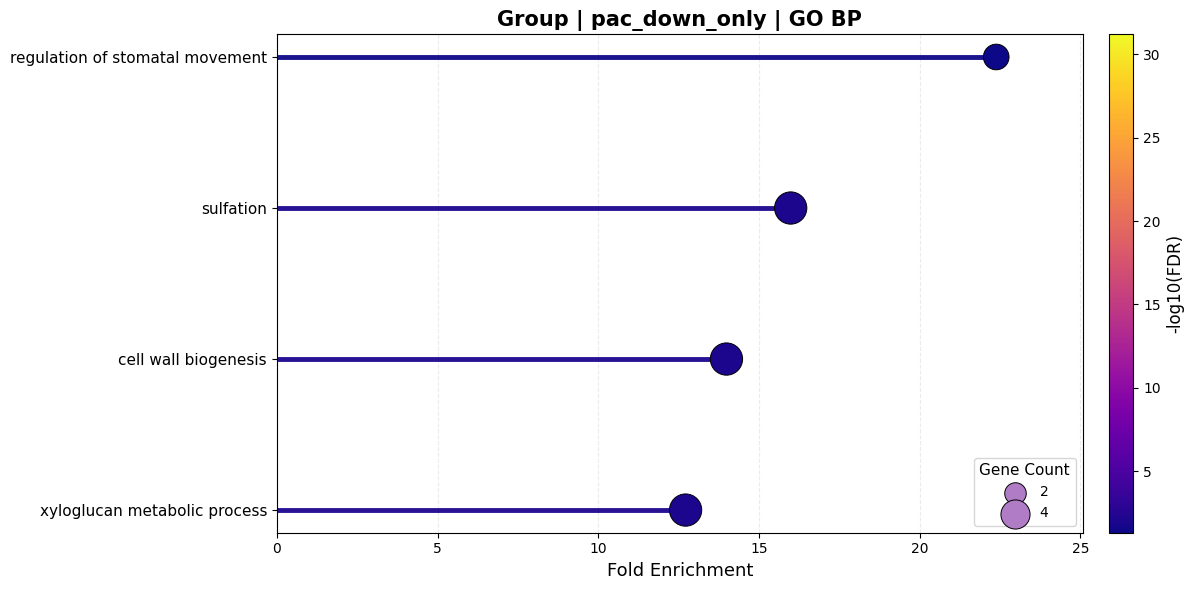

Saved: GO_Lollipop_Plots\Group\pac_down_only_MF_Lollipop.png


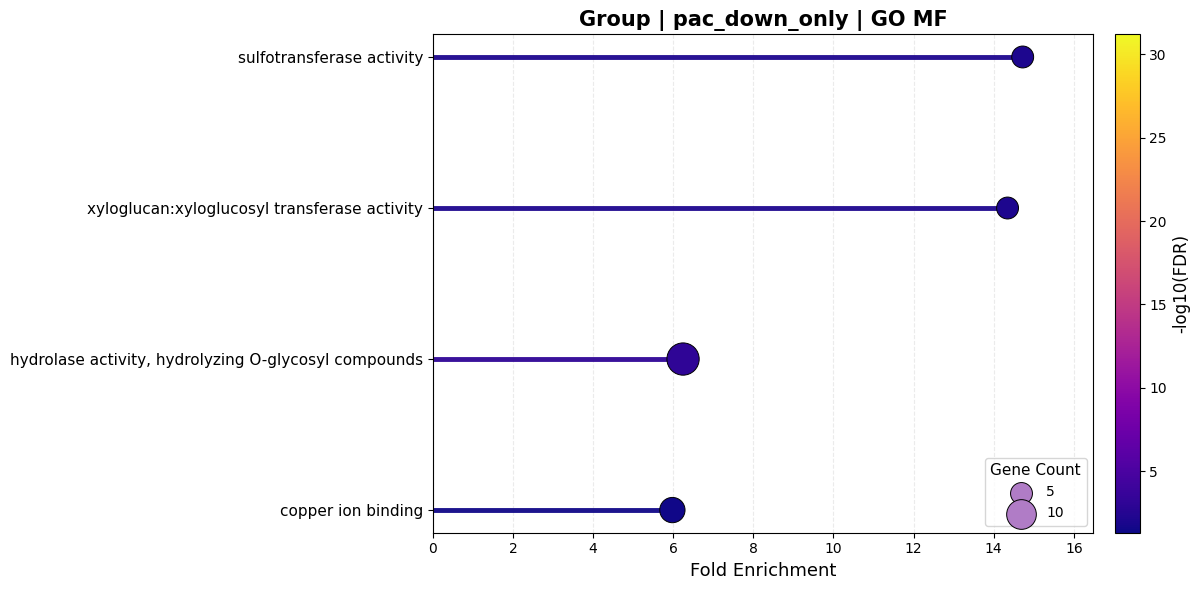

Saved: GO_Lollipop_Plots\Group\pac_down_only_CC_Lollipop.png


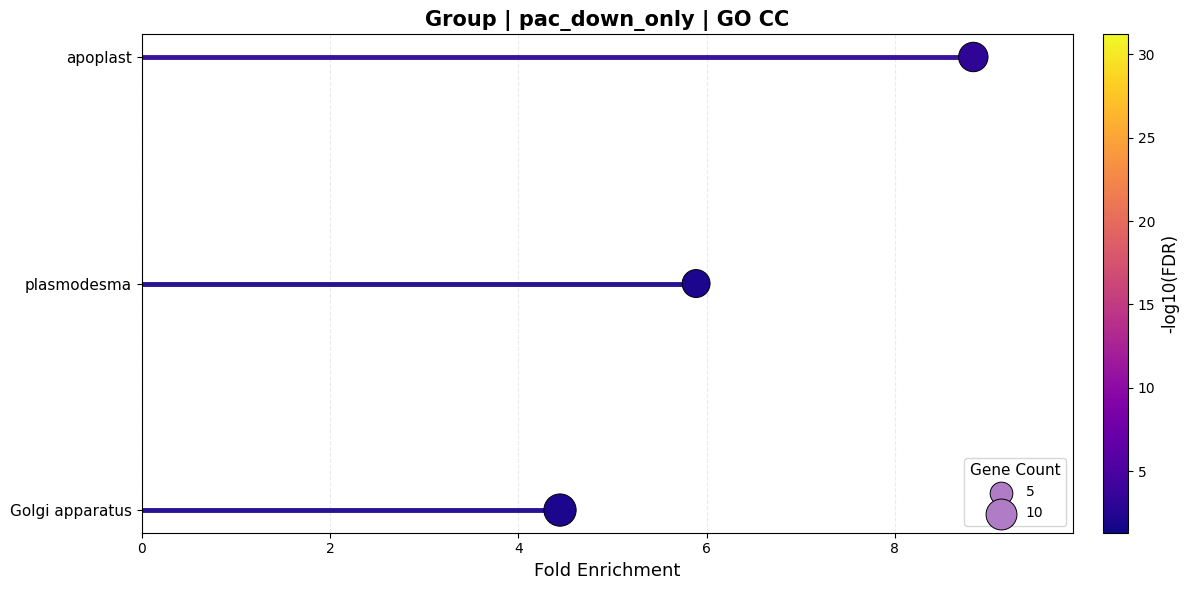

Saved: GO_Lollipop_Plots\Group\GA_Specific_Up_BP_Lollipop.png


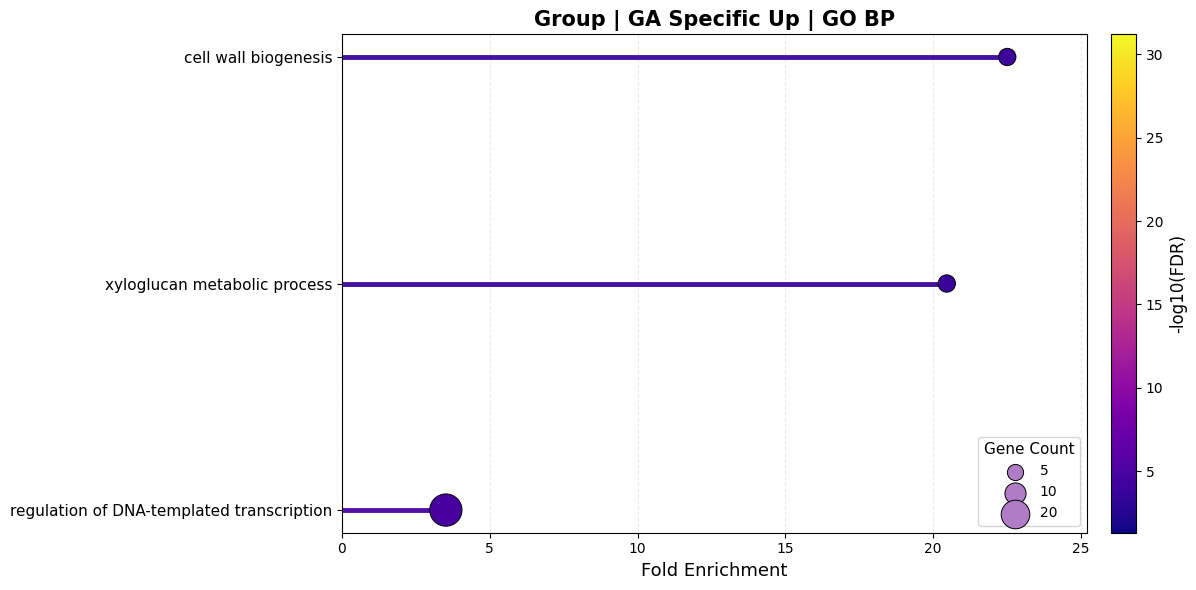

Saved: GO_Lollipop_Plots\Group\GA_Specific_Up_MF_Lollipop.png


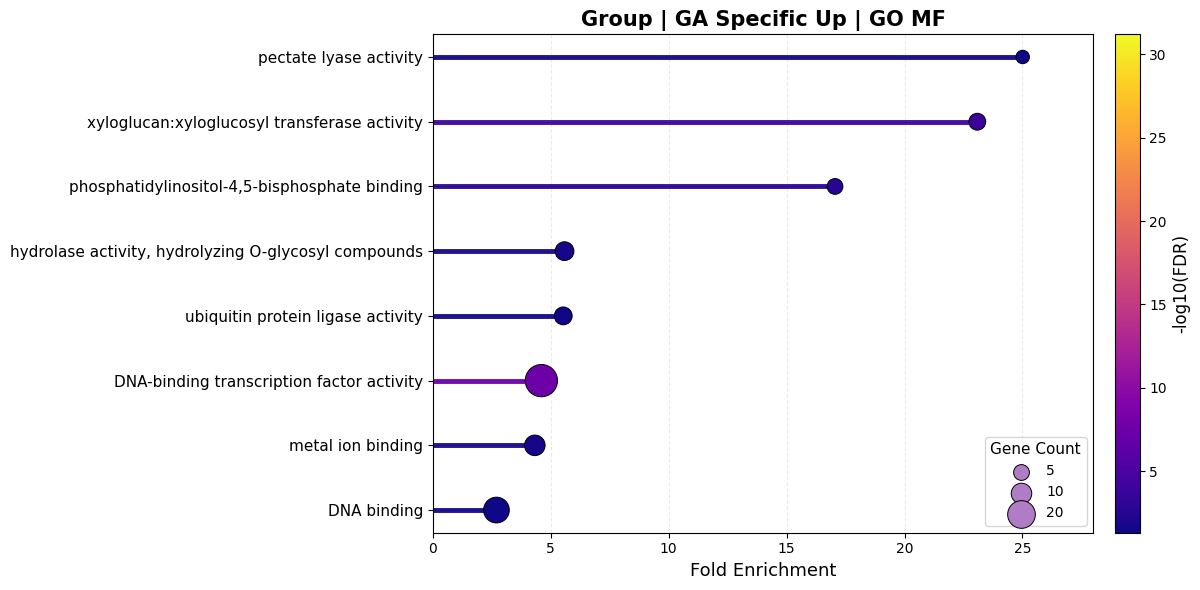

Saved: GO_Lollipop_Plots\Group\GA_Specific_Up_CC_Lollipop.png


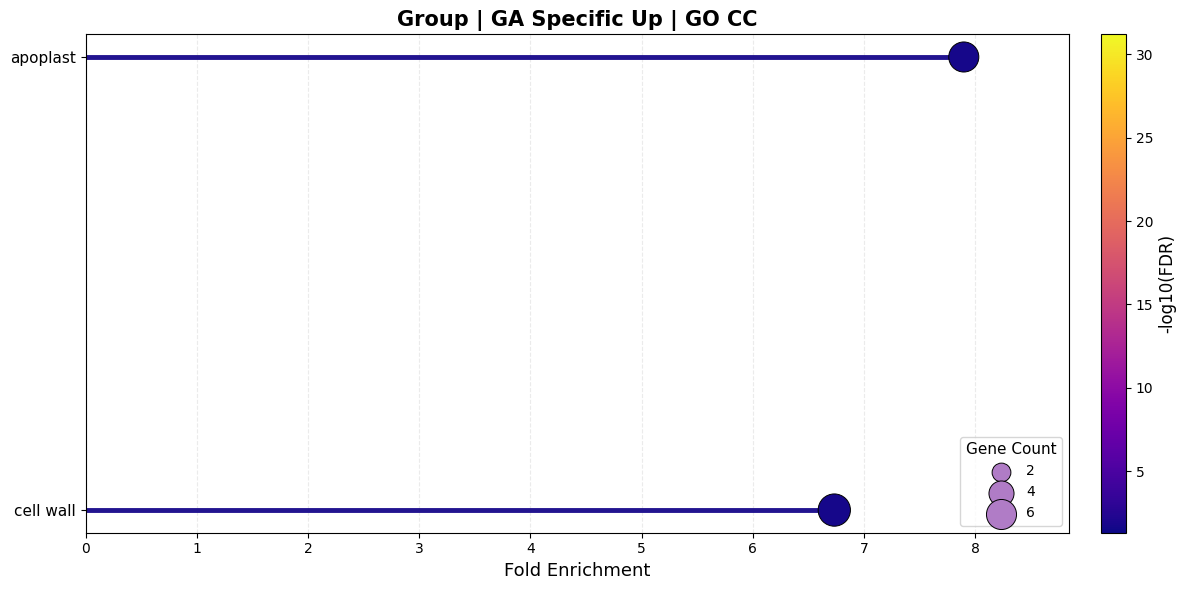

Saved: GO_Lollipop_Plots\Group\GA_Specific_Down_BP_Lollipop.png


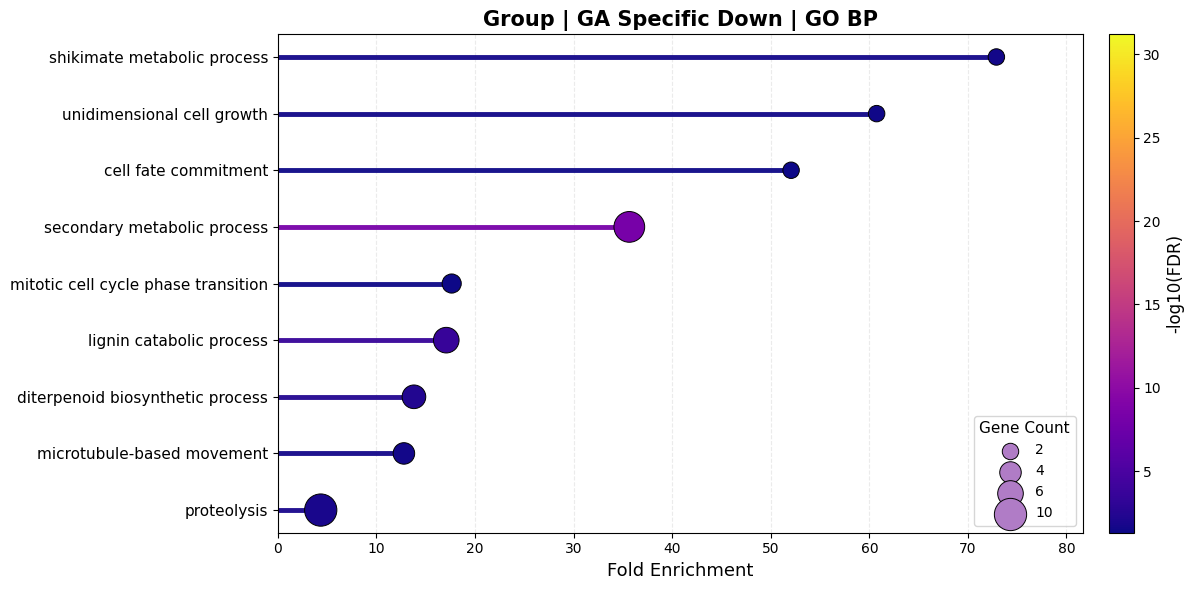

Saved: GO_Lollipop_Plots\Group\GA_Specific_Down_MF_Lollipop.png


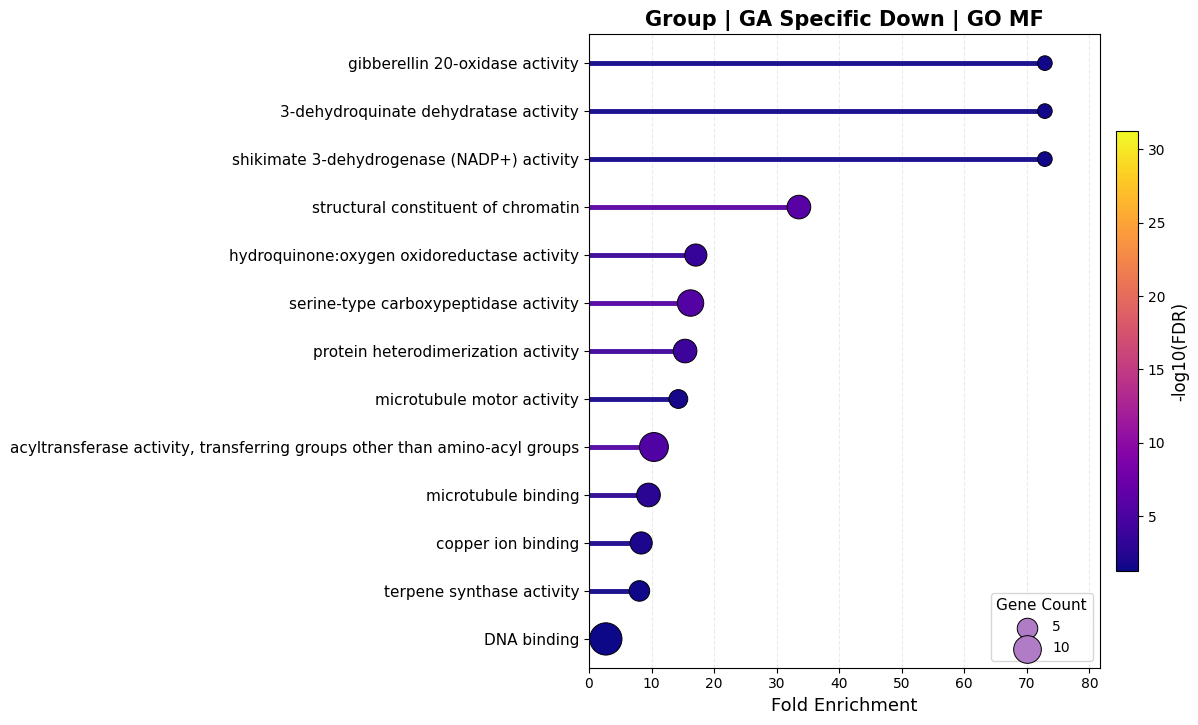

Saved: GO_Lollipop_Plots\Group\GA_Specific_Down_CC_Lollipop.png


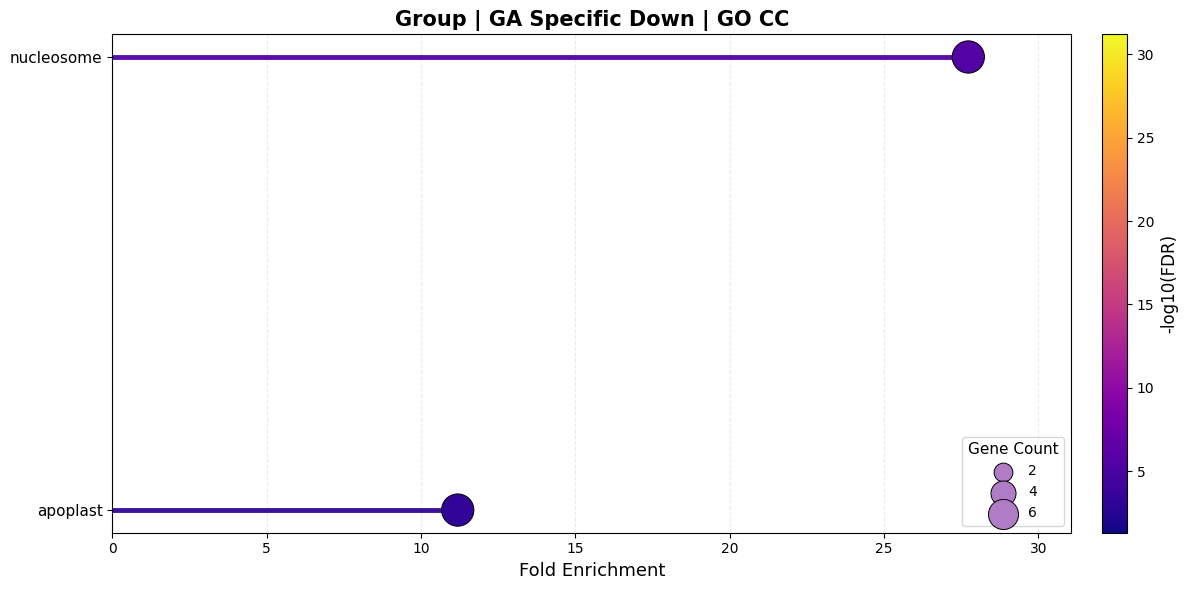

Saved: GO_Lollipop_Plots\Group\PAC_Specific_Up_BP_Lollipop.png


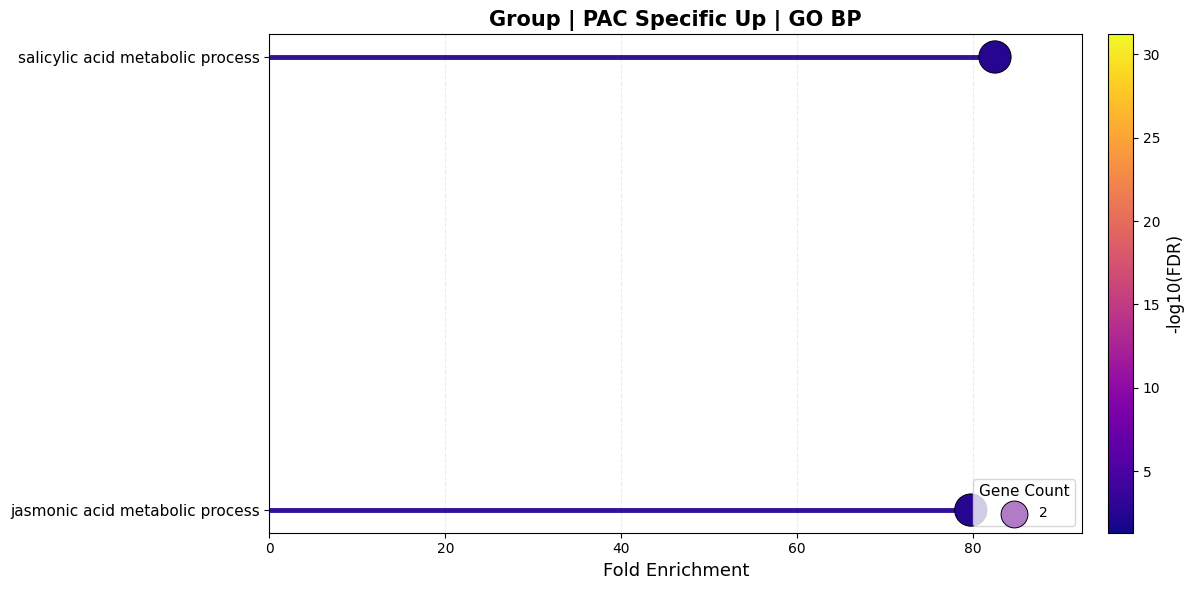

Saved: GO_Lollipop_Plots\Group\PAC_Specific_Up_MF_Lollipop.png


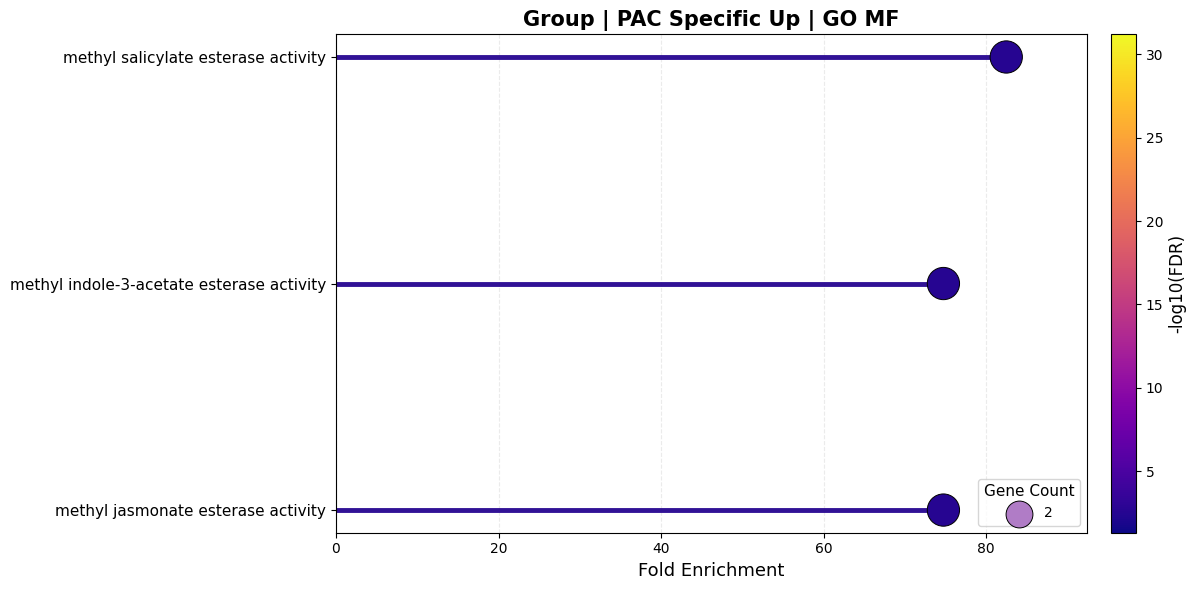

Saved: GO_Lollipop_Plots\Group\PAC_Specific_Down_BP_Lollipop.png


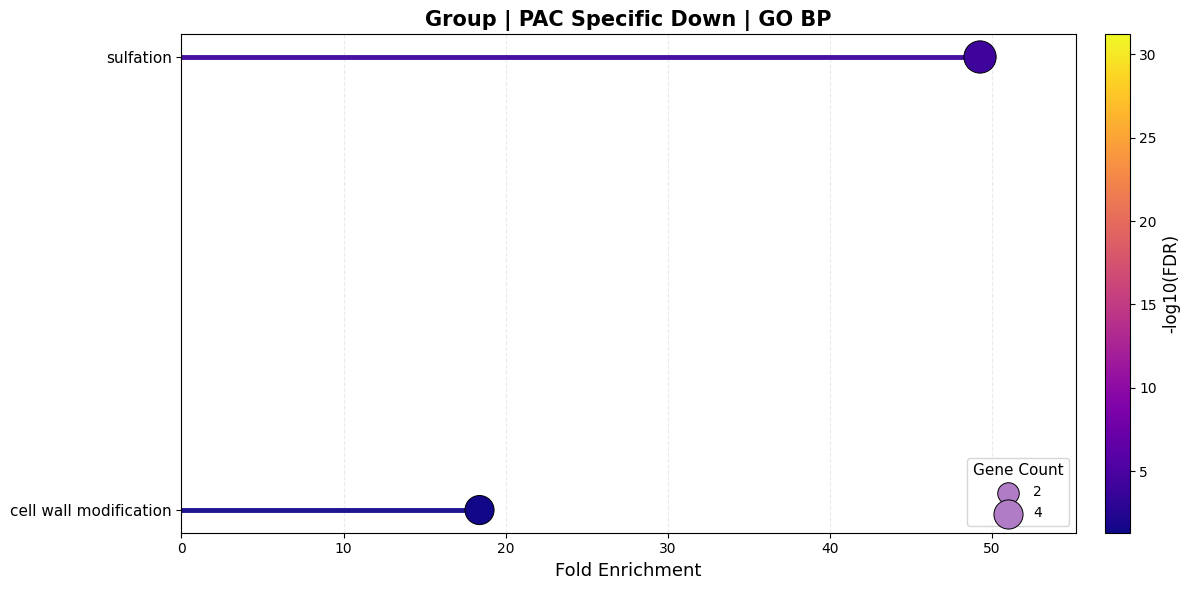

Saved: GO_Lollipop_Plots\Group\PAC_Specific_Down_MF_Lollipop.png


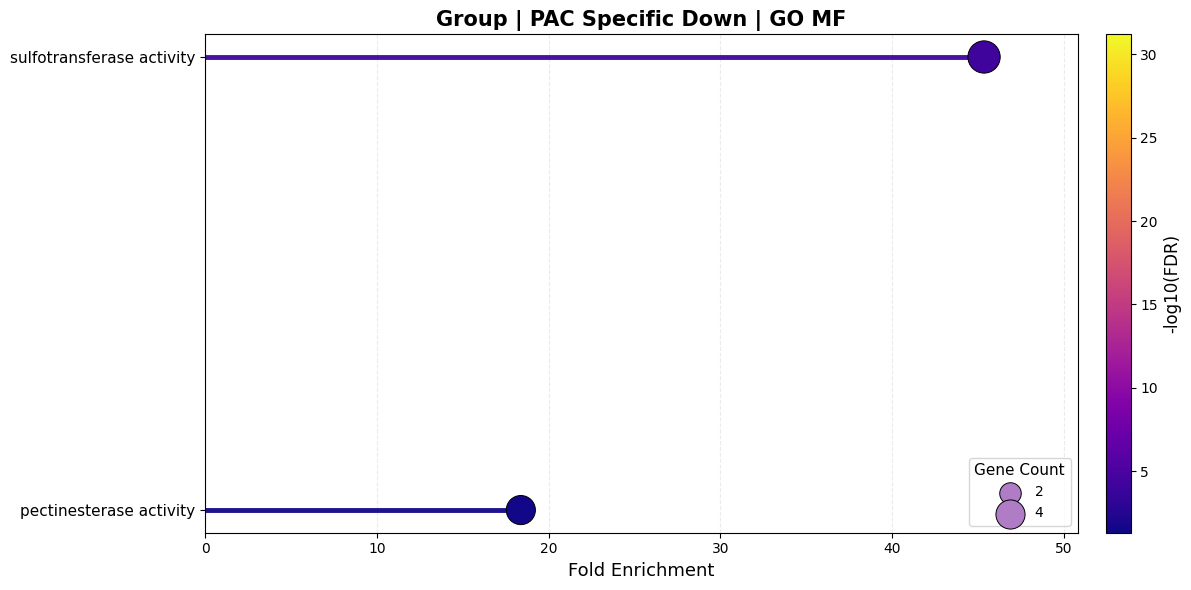


All lollipop plots saved successfully.


In [56]:
# ==========================================
# SETTINGS
# ==========================================

TOP_N = 20
FDR_CUTOFF = 0.05
SHOW_PLOTS = True

# Sort options: "FDR" or "Fold_Enrichment"
SORT_BY = "Fold_Enrichment"

output_dir = Path("GO_Lollipop_Plots")
output_dir.mkdir(parents=True, exist_ok=True)

categories = {
    "Process": "BP",
    "Function": "MF",
    "Component": "CC"
}

# Example input dictionaries
enrichment_sets = {
    "Treatment": enrichment_dfs,
    "Group": group_enrichment
}

# ==========================================
# PREPARE DATA
# ==========================================

required = {
    "Category", "GO_term", "GO_ID",
    "Gene_Count", "FDR", "Fold_Enrichment"
}

prepared = {}

for analysis_name, groups in enrichment_sets.items():
    prepared[analysis_name] = {}

    for group_name, df0 in groups.items():
        df = df0.copy()

        if df.empty:
            continue

        missing = required - set(df.columns)
        if missing:
            print(f"Skipping {group_name}, missing columns: {missing}")
            continue

        for col in ["Gene_Count", "FDR", "Fold_Enrichment"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        df = df[
            (df["FDR"] < FDR_CUTOFF) &
            (df["FDR"] > 0) &
            (df["Gene_Count"] > 0) &
            (df["Fold_Enrichment"] > 0)
        ].copy()

        if df.empty:
            continue

        df["Score"] = -np.log10(df["FDR"].clip(lower=1e-300))
        prepared[analysis_name][group_name] = df

# global color scale
all_scores = [
    df["Score"]
    for groups in prepared.values()
    for df in groups.values()
]

if not all_scores:
    raise ValueError("No valid enrichment results found.")

all_scores = pd.concat(all_scores)
norm = Normalize(vmin=all_scores.min(), vmax=all_scores.max())
cmap = cm.plasma


# ==========================================
# HELPER FUNCTIONS
# ==========================================

def bubble_size(count, max_count):
    """
    Convert Gene_Count to marker size.
    """
    return 40 + 500 * np.asarray(count) / max(max_count, 1)


def nice_legend_counts(max_count, n=4):
    """
    Create clean rounded legend values for Gene Count.
    """
    if max_count <= 10:
        step = 2
    elif max_count <= 30:
        step = 5
    elif max_count <= 80:
        step = 10
    elif max_count <= 150:
        step = 20
    else:
        step = 25

    vals = list(range(step, int(np.ceil(max_count / step)) * step + 1, step))

    if len(vals) > n:
        idx = np.linspace(0, len(vals) - 1, n).astype(int)
        vals = [vals[i] for i in idx]

    vals = sorted(set([v for v in vals if v <= max_count]))
    if len(vals) == 0:
        vals = [max_count]

    return vals


# ==========================================
# MAIN LOLLIPOP FUNCTION
# ==========================================

def plot_lollipop(df, group_name, category, short_name, analysis_name):
    sub = df[df["Category"] == category].copy()

    if sub.empty:
        return

    # remove duplicated GO_ID if any
    sub = sub.sort_values("FDR").drop_duplicates("GO_ID")

    # sort
    if SORT_BY == "Fold_Enrichment":
        sub = sub.sort_values(
            ["Fold_Enrichment", "FDR"],
            ascending=[False, True]
        )
    else:
        sub = sub.sort_values(
            ["FDR", "Fold_Enrichment"],
            ascending=[True, False]
        )

    # top N
    sub = sub.head(TOP_N).copy()

    # reverse so top item appears at top of figure
    sub = sub.iloc[::-1].reset_index(drop=True)

    y = np.arange(len(sub))
    max_count = sub["Gene_Count"].max()

    fig_height = max(6, len(sub) * 0.45 + 1.5)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    # color values
    colors = cmap(norm(sub["Score"].values))

    # thicker lollipop lines
    for yi, xval, col in zip(y, sub["Fold_Enrichment"], colors):
        ax.hlines(
            y=yi,
            xmin=0,
            xmax=xval,
            color=col,
            linewidth=3.5,
            alpha=0.95,
            zorder=1
        )

    # points
    scatter = ax.scatter(
        sub["Fold_Enrichment"],
        y,
        s=bubble_size(sub["Gene_Count"], max_count),
        c=sub["Score"],
        cmap=cmap,
        norm=norm,
        edgecolors="black",
        linewidths=0.7,
        zorder=3
    )

    ax.set_yticks(y)
    ax.set_yticklabels(sub["GO_term"], fontsize=11)
    ax.set_xlabel("Fold Enrichment", fontsize=13)
    ax.set_title(
        f"{analysis_name} | {group_name} | GO {short_name}",
        fontsize=15,
        fontweight="bold"
    )

    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    # better x limit
    xmax = sub["Fold_Enrichment"].max()
    ax.set_xlim(0, xmax * 1.12)

    # colorbar
    cbar = fig.colorbar(scatter, ax=ax, fraction=0.04, pad=0.03)
    cbar.set_label("-log10(FDR)", fontsize=12)

    # clean gene count legend
    legend_counts = nice_legend_counts(max_count, n=4)

    handles = [
        ax.scatter(
            [], [],
            s=bubble_size(n, max_count),
            color="#B07CC6",
            edgecolors="black",
            linewidths=0.7
        )
        for n in legend_counts
    ]

    ax.legend(
        handles,
        [str(n) for n in legend_counts],
        title="Gene Count",
        loc="lower right",
        frameon=True,
        fontsize=10,
        title_fontsize=11
    )

    plt.tight_layout()

    # save
    save_folder = output_dir / analysis_name
    save_folder.mkdir(parents=True, exist_ok=True)

    group_safe = group_name.replace(" ", "_").replace("/", "_")
    filename = f"{group_safe}_{short_name}_Lollipop.png"

    fig.savefig(
        save_folder / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", save_folder / filename)

    if SHOW_PLOTS:
        plt.show()

    plt.close(fig)


# ==========================================
# RUN FOR ALL GROUPS
# ==========================================

for analysis_name, groups in prepared.items():
    for group_name, df in groups.items():
        for category, short_name in categories.items():
            plot_lollipop(
                df=df,
                group_name=group_name,
                category=category,
                short_name=short_name,
                analysis_name=analysis_name
            )

print("\nAll lollipop plots saved successfully.")

# KEGG analysis

In [61]:
# =====================================================
# 1. DOWNLOAD KEGG ANNOTATION
# =====================================================

BASE_URL = "https://rest.kegg.jp"

def kegg_download(endpoint):
    response = requests.get(
        f"{BASE_URL}/{endpoint}",
        timeout=90
    )
    response.raise_for_status()
    return response.text


# Gene-to-pathway mapping
gene_pathway = pd.read_csv(
    StringIO(kegg_download("link/pathway/egr")),
    sep="\t",
    header=None,
    names=["KEGG_Gene", "Pathway"]
)

# Pathway names
pathway_names = pd.read_csv(
    StringIO(kegg_download("list/pathway/egr")),
    sep="\t",
    header=None,
    names=["Pathway", "Pathway_Name"]
)

# KEGG-to-NCBI mapping
gene_mapping = pd.read_csv(
    StringIO(kegg_download("conv/ncbi-geneid/egr")),
    sep="\t",
    header=None,
    names=["KEGG_Gene", "NCBI_Gene"]
)

print("Gene-pathway:", gene_pathway.shape)
print("Pathway names:", pathway_names.shape)
print("Gene mapping:", gene_mapping.shape)


# =====================================================
# 2. STANDARDIZE IDENTIFIERS
# =====================================================

# Remove path: prefix
gene_pathway["Pathway"] = (
    gene_pathway["Pathway"]
    .str.replace("path:", "", regex=False)
)

pathway_names["Pathway"] = (
    pathway_names["Pathway"]
    .str.replace("path:", "", regex=False)
)

# Remove NCBI prefix
gene_mapping["NCBI_Gene"] = (
    gene_mapping["NCBI_Gene"]
    .str.replace("ncbi-geneid:", "", regex=False)
    .str.strip()
)

# Standardize KEGG gene IDs
gene_pathway["KEGG_Gene"] = (
    gene_pathway["KEGG_Gene"].astype(str).str.strip()
)

gene_mapping["KEGG_Gene"] = (
    gene_mapping["KEGG_Gene"].astype(str).str.strip()
)


# =====================================================
# 3. MERGE ALL TABLES
# =====================================================

kegg_eucalyptus = (
    gene_pathway
    .merge(
        pathway_names,
        on="Pathway",
        how="left"
    )
    .merge(
        gene_mapping,
        on="KEGG_Gene",
        how="left"
    )
    .drop_duplicates()
    .reset_index(drop=True)
)

print("\n========== KEGG ANNOTATION ==========")

print(
    "Gene-pathway associations:",
    len(kegg_eucalyptus)
)

print(
    "Unique KEGG genes:",
    kegg_eucalyptus["KEGG_Gene"].nunique()
)

print(
    "Mapped NCBI genes:",
    kegg_eucalyptus["NCBI_Gene"].nunique()
)

print(
    "Unique pathways:",
    kegg_eucalyptus["Pathway"].nunique()
)

print(
    "Missing pathway names:",
    kegg_eucalyptus["Pathway_Name"].isna().sum()
)

display(kegg_eucalyptus.head(10))


# =====================================================
# 4. COMPARE WITH GO ANNOTATION
# =====================================================

# GO GeneIDs
go_genes = set(
    go_eucalyptus["GeneID"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.replace(r"^LOC", "", regex=True)
)

# KEGG NCBI GeneIDs
kegg_genes = set(
    kegg_eucalyptus["NCBI_Gene"]
    .dropna()
    .astype(str)
    .str.strip()
)

matched_genes = go_genes & kegg_genes

coverage = (
    100 * len(matched_genes) / len(go_genes)
    if go_genes else 0
)

print("\n========== GO vs KEGG ==========")

print("GO annotated genes:", len(go_genes))
print("KEGG annotated genes:", len(kegg_genes))
print("Matched genes:", len(matched_genes))
print(f"Coverage: {coverage:.2f}%")


# =====================================================
# 5. PREPARE COVERAGE SUMMARY
# =====================================================

summary = pd.DataFrame([
    {
        "Metric": "GO annotated genes",
        "Value": len(go_genes)
    },
    {
        "Metric": "KEGG annotated genes",
        "Value": len(kegg_genes)
    },
    {
        "Metric": "Matched genes",
        "Value": len(matched_genes)
    },
    {
        "Metric": "KEGG coverage of GO genes (%)",
        "Value": round(coverage, 2)
    },
    {
        "Metric": "KEGG pathways",
        "Value": kegg_eucalyptus["Pathway"].nunique()
    }
])

display(summary)


# =====================================================
# 6. SAVE EXCEL
# =====================================================

with pd.ExcelWriter(
    "KEGG_Eucalyptus_Annotation.xlsx"
) as writer:

    kegg_eucalyptus.to_excel(
        writer,
        sheet_name="KEGG_Annotation",
        index=False
    )

    summary.to_excel(
        writer,
        sheet_name="Coverage_Summary",
        index=False
    )

    pd.DataFrame({
        "Matched_GeneID": sorted(matched_genes)
    }).to_excel(
        writer,
        sheet_name="Matched_Genes",
        index=False
    )

print("\nSaved: KEGG_Eucalyptus_Annotation.xlsx")


Gene-pathway: (17201, 2)
Pathway names: (162, 2)
Gene mapping: (34419, 2)

========== KEGG ANNOTATION ==========
Gene-pathway associations: 17201
Unique KEGG genes: 7072
Mapped NCBI genes: 7072
Unique pathways: 162
Missing pathway names: 0


,KEGG_Gene,Pathway,Pathway_Name,NCBI_Gene
0,egr:104414694,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104414694
1,egr:104414937,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104414937
2,egr:104415232,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104415232
3,egr:104415266,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104415266
4,egr:104415712,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104415712
5,egr:104415880,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104415880
6,egr:104415881,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104415881
7,egr:104415882,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104415882
8,egr:104415976,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104415976
9,egr:104416169,egr00010,Glycolysis / Gluconeogenesis - Eucalyptus gran...,104416169



========== GO vs KEGG ==========
GO annotated genes: 25512
KEGG annotated genes: 7072
Matched genes: 6060
Coverage: 23.75%


,Metric,Value
0,GO annotated genes,25512.00
1,KEGG annotated genes,7072.00
2,Matched genes,6060.00
3,KEGG coverage of GO genes (%),23.75
4,KEGG pathways,162.00



Saved: KEGG_Eucalyptus_Annotation.xlsx


In [64]:
# =====================================================
# 1. KEGG ANNOTATED GENES
# =====================================================

kegg_genes = set(
    kegg_eucalyptus["NCBI_Gene"]
    .dropna()
    .astype(str)
    .str.strip()
)

# =====================================================
# 2. DEFINE TREATMENT GROUPS
# =====================================================

treatment_genes = {
    "GA Up": ga_up,
    "GA Down": ga_down,
    "PAC Up": pac_up,
    "PAC Down": pac_down,
    "GA-PAC Up": ga_pac_up,
    "GA-PAC Down": ga_pac_down
}

# Group genes already defined in your notebook
# gene_groups = {...}

# =====================================================
# 3. COMBINE BOTH ANALYSES
# =====================================================

analysis_sets = {
    "Treatment": treatment_genes,
    "Group": gene_groups
}

# =====================================================
# 4. CALCULATE KEGG COVERAGE
# =====================================================

coverage_results = {}

for analysis_name, groups in analysis_sets.items():

    summary = []

    for name, genes in groups.items():

        # Standardize NCBI Gene IDs
        gene_set = {
            str(g).strip().removeprefix("LOC")
            for g in genes
            if pd.notna(g)
        }

        # Find genes annotated in KEGG
        matched = gene_set & kegg_genes

        total = len(gene_set)
        matched_count = len(matched)

        coverage = (
            100 * matched_count / total
            if total > 0 else 0
        )

        summary.append({
            "Group": name,
            "Total_Genes": total,
            "KEGG_Matched": matched_count,
            "Unmapped_Genes": total - matched_count,
            "Coverage_Percent": round(coverage, 2)
        })

    coverage_df = pd.DataFrame(summary)

    coverage_results[analysis_name] = coverage_df

    print(f"\n{'=' * 55}")
    print(f"{analysis_name} KEGG Coverage")
    print(f"{'=' * 55}")

    display(coverage_df)

# =====================================================
# 5. COMBINE RESULTS
# =====================================================

combined_coverage = pd.concat(
    [
        df.assign(Analysis=analysis_name)
        for analysis_name, df in coverage_results.items()
    ],
    ignore_index=True
)

combined_coverage = combined_coverage[
    [
        "Analysis",
        "Group",
        "Total_Genes",
        "KEGG_Matched",
        "Unmapped_Genes",
        "Coverage_Percent"
    ]
]

# =====================================================
# 6. SAVE EXCEL
# =====================================================

with pd.ExcelWriter("KEGG_Coverage_All.xlsx") as writer:

    coverage_results["Treatment"].to_excel(
        writer,
        sheet_name="Treatment_Coverage",
        index=False
    )

    coverage_results["Group"].to_excel(
        writer,
        sheet_name="Group_Coverage",
        index=False
    )

    combined_coverage.to_excel(
        writer,
        sheet_name="All_Coverage",
        index=False
    )

print("\nSaved: KEGG_Coverage_All.xlsx")



Treatment KEGG Coverage


,Group,Total_Genes,KEGG_Matched,Unmapped_Genes,Coverage_Percent
0,GA Up,2547,516,2031,20.26
1,GA Down,1676,412,1264,24.58
2,PAC Up,1692,400,1292,23.64
3,PAC Down,856,204,652,23.83
4,GA-PAC Up,562,103,459,18.33
5,GA-PAC Down,284,66,218,23.24



Group KEGG Coverage


,Group,Total_Genes,KEGG_Matched,Unmapped_Genes,Coverage_Percent
0,Both Up,1443,327,1116,22.66
1,Both Down,519,147,372,28.32
2,ga_up_only,1103,189,914,17.14
3,ga_down_only,1157,265,892,22.90
4,pac_up_only,249,73,176,29.32
5,pac_down_only,336,57,279,16.96
6,GA Up PAC Down,1,0,1,0.00
7,PAC Up GA Down,0,0,0,0.00
8,GA Specific Up,283,49,234,17.31
9,GA Specific Down,184,36,148,19.57



Saved: KEGG_Coverage_All.xlsx


In [70]:
def kegg_Enrichment(
    gene_list,
    kegg_annotation,
    background_genes,
    min_genes=5
):

    kegg = kegg_annotation[
        ["NCBI_Gene", "Pathway", "Pathway_Name"]
    ].dropna(subset=["NCBI_Gene", "Pathway"]).copy()

    kegg["NCBI_Gene"] = (
        kegg["NCBI_Gene"].astype(str).str.strip()
    )

    kegg = kegg.drop_duplicates(
        ["NCBI_Gene", "Pathway"]
    )

    def normalize_genes(genes):
        return {
            str(g).strip().removeprefix("LOC")
            for g in genes
            if pd.notna(g)
        }

    # Tested genes with KEGG annotation
    annotated_genes = set(kegg["NCBI_Gene"])

    background = (
        normalize_genes(background_genes)
        & annotated_genes
    )

    N = len(background)

    if N == 0:
        raise ValueError("No KEGG genes in background.")

    # DEG genes included in background
    targets = normalize_genes(gene_list) & background
    n = len(targets)

    columns = [
        "Pathway", "Pathway_Name",
        "Gene_Count", "Background_Count",
        "Target_Total", "Background_Total",
        "Gene_Ratio", "Background_Ratio",
        "Fold_Enrichment", "Odds_Ratio",
        "P_value", "FDR", "minus_log10_FDR",
        "target_Gene_ids"
    ]

    if n == 0:
        return pd.DataFrame(columns=columns)

    results = []

    for pathway, group in kegg.groupby("Pathway"):

        term_genes = (
            set(group["NCBI_Gene"]) & background
        )

        K = len(term_genes)

        if K < min_genes:
            continue

        target_term_genes = targets & term_genes

        a = len(target_term_genes)
        b = n - a
        c = K - a
        d = N - a - b - c

        odds_ratio, p_value = fisher_exact(
            [[a, b], [c, d]],
            alternative="greater"
        )

        gene_ratio = a / n
        background_ratio = K / N

        results.append({
            "Pathway": pathway,
            "Pathway_Name": group["Pathway_Name"].iloc[0],
            "Gene_Count": a,
            "Background_Count": K,
            "Target_Total": n,
            "Background_Total": N,
            "Gene_Ratio": gene_ratio,
            "Background_Ratio": background_ratio,
            "Fold_Enrichment": gene_ratio / background_ratio,
            "Odds_Ratio": odds_ratio,
            "P_value": p_value,
            "target_Gene_ids": ", ".join(
                sorted(target_term_genes)
            )
        })

    df = pd.DataFrame(results)

    if df.empty:
        return pd.DataFrame(columns=columns)

    df["FDR"] = multipletests(
        df["P_value"],
        method="fdr_bh"
    )[1]

    df["minus_log10_FDR"] = -np.log10(
        df["FDR"].clip(lower=1e-300)
    )

    return (
        df[columns]
        .sort_values("FDR")
        .reset_index(drop=True)
    )


In [76]:
analysis_sets = {
    "Treatment": treatment_genes,
    "Group": gene_groups
}

background_genes = go_eucalyptus["GeneID"]

kegg_enrichment_results = {}
summary = []

for analysis_name, groups in analysis_sets.items():

    print(f"\n{'=' * 60}")
    print(f"KEGG Enrichment: {analysis_name}")
    print(f"{'=' * 60}")

    kegg_enrichment_results[analysis_name] = {}

    output_file = f"{analysis_name}_KEGG_Enrichment.xlsx"

    with pd.ExcelWriter(output_file) as writer:

        for group_name, genes in groups.items():

            # Run KEGG enrichment
            result = kegg_Enrichment(
                gene_list=genes,
                kegg_annotation=kegg_eucalyptus,
                background_genes=background_genes,
                min_genes=5
            )

            # Store results
            kegg_enrichment_results[analysis_name][group_name] = result

            # Select significant pathways
            significant = result[
                result["FDR"] < 0.05
            ]

            # Summary
            summary.append({
                "Analysis": analysis_name,
                "Group": group_name,
                "Total_Genes": len(set(genes)),
                "Tested_Pathways": len(result),
                "Significant_Pathways": len(significant)
            })

            # Excel sheet name (max 31 characters)
            sheet_name = group_name[:31]

            # Save ALL tested pathways
            result.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False
            )

            print(
                f"{group_name:24} | "
                f"Genes: {len(set(genes)):5} | "
                f"Tested pathways: {len(result):4} | "
                f"Significant: {len(significant):3}"
            )

    print(f"\nSaved: {output_file}")

kegg_summary_df = pd.DataFrame(summary)

display(kegg_summary_df)

# Save separate summary
kegg_summary_df.to_excel(
    "KEGG_Enrichment_Summary.xlsx",
    index=False
)

print("\nAll KEGG enrichment analyses completed.")



KEGG Enrichment: Treatment
GA Up                    | Genes:  2547 | Tested pathways:  158 | Significant:  14
GA Down                  | Genes:  1676 | Tested pathways:  158 | Significant:  12
PAC Up                   | Genes:  1692 | Tested pathways:  158 | Significant:  16
PAC Down                 | Genes:   856 | Tested pathways:  158 | Significant:   4
GA-PAC Up                | Genes:   562 | Tested pathways:  158 | Significant:   3
GA-PAC Down              | Genes:   284 | Tested pathways:  158 | Significant:   3

Saved: Treatment_KEGG_Enrichment.xlsx

KEGG Enrichment: Group
Both Up                  | Genes:  1443 | Tested pathways:  158 | Significant:  15
Both Down                | Genes:   519 | Tested pathways:  158 | Significant:   5
ga_up_only               | Genes:  1103 | Tested pathways:  158 | Significant:   3
ga_down_only             | Genes:  1157 | Tested pathways:  158 | Significant:   6
pac_up_only              | Genes:   249 | Tested pathways:  158 | Significant: 

,Analysis,Group,Total_Genes,Tested_Pathways,Significant_Pathways
0,Treatment,GA Up,2547,158,14
1,Treatment,GA Down,1676,158,12
2,Treatment,PAC Up,1692,158,16
3,Treatment,PAC Down,856,158,4
4,Treatment,GA-PAC Up,562,158,3
5,Treatment,GA-PAC Down,284,158,3
6,Group,Both Up,1443,158,15
7,Group,Both Down,519,158,5
8,Group,ga_up_only,1103,158,3
9,Group,ga_down_only,1157,158,6



All KEGG enrichment analyses completed.


## Plot

No KEGG results: GA Up PAC Down
No KEGG results: PAC Up GA Down
No significant KEGG pathways: PAC Specific Up

Generating Treatment plots...
Saved: KEGG_Lollipop_Plots\Treatment\GA_Up_KEGG_Lollipop.png


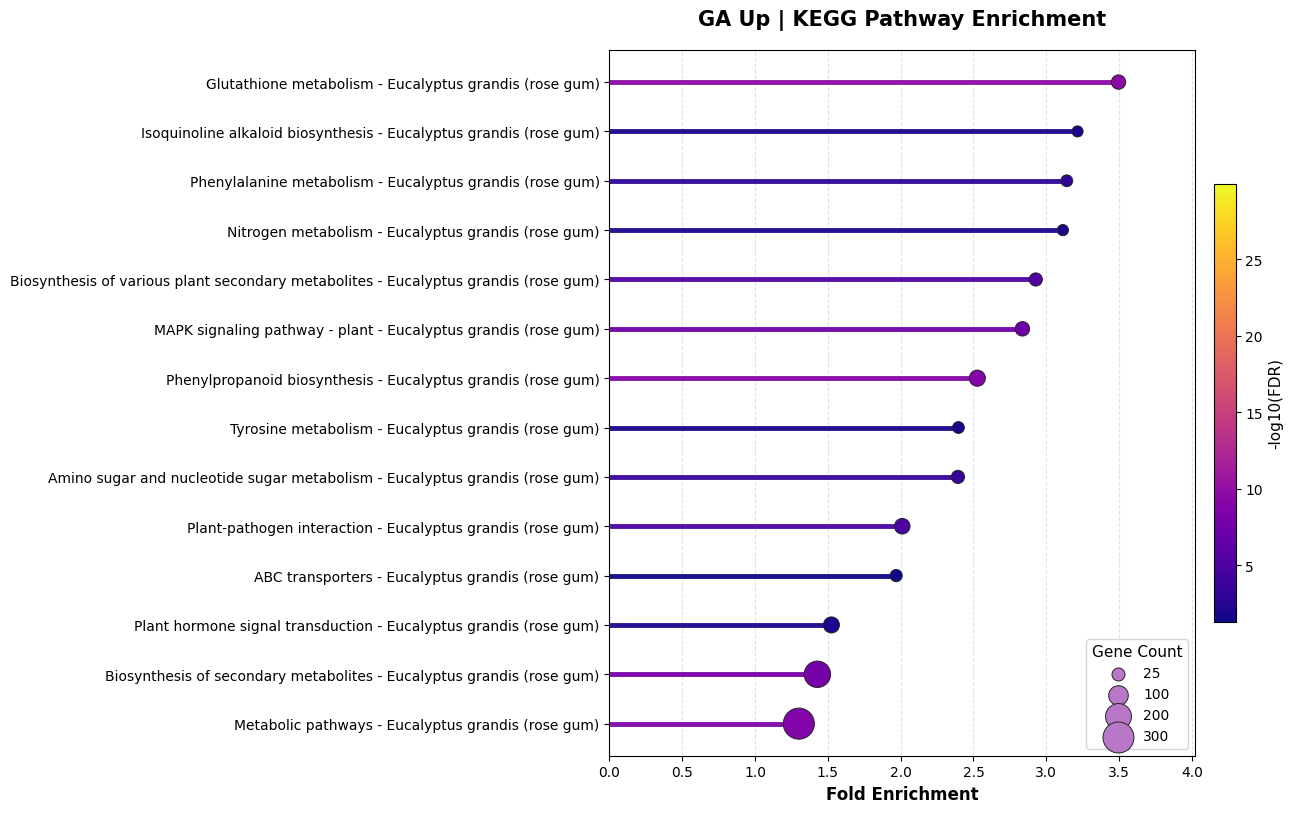

Saved: KEGG_Lollipop_Plots\Treatment\GA_Down_KEGG_Lollipop.png


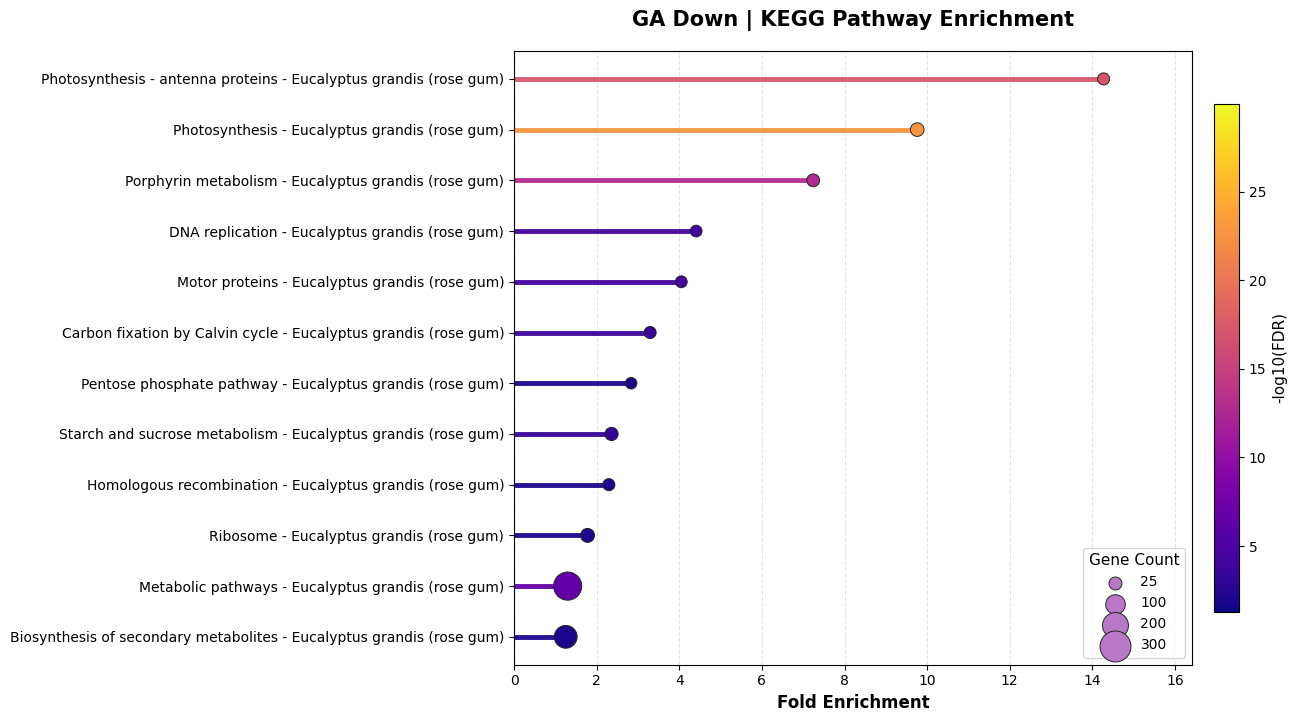

Saved: KEGG_Lollipop_Plots\Treatment\PAC_Up_KEGG_Lollipop.png


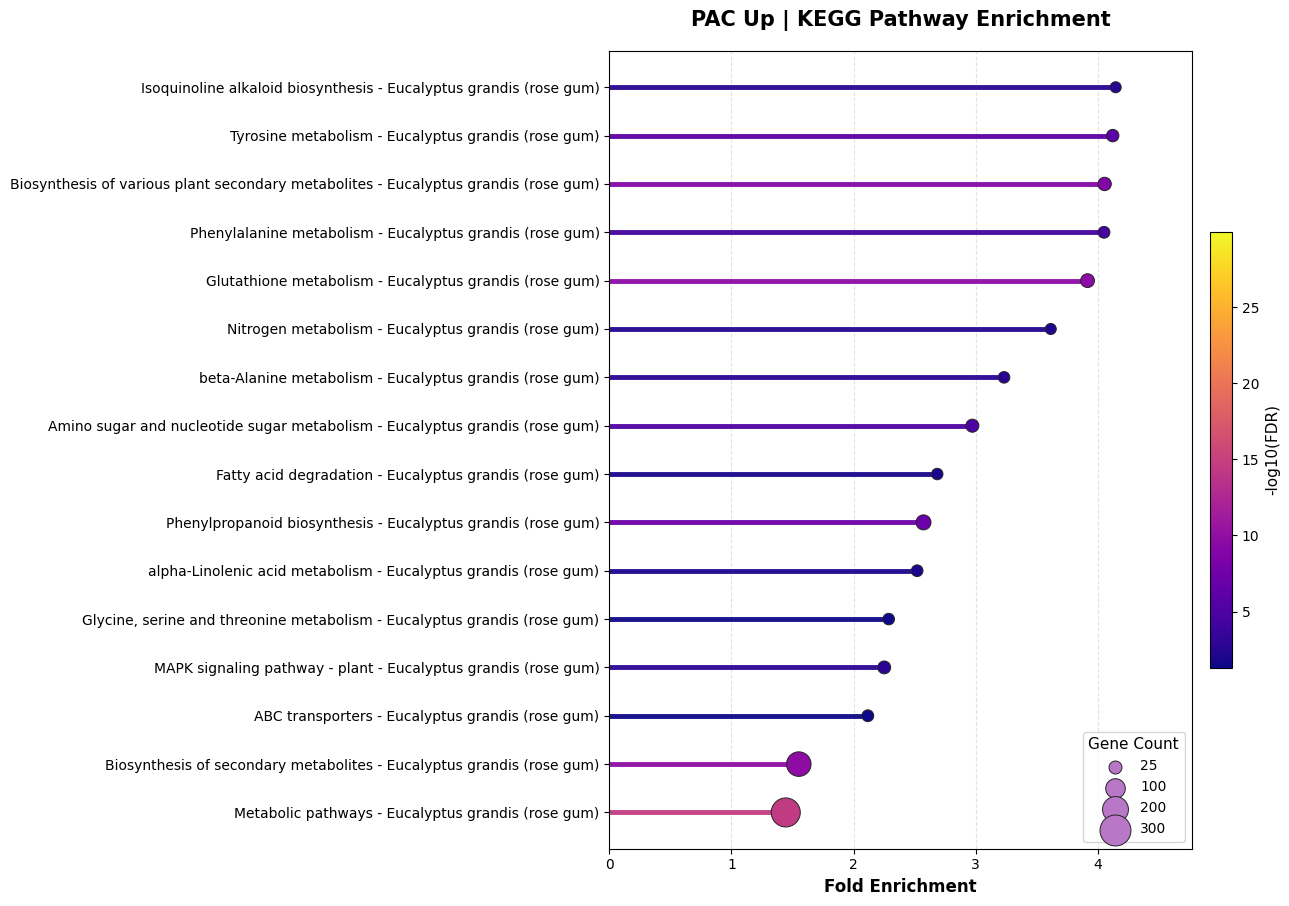

Saved: KEGG_Lollipop_Plots\Treatment\PAC_Down_KEGG_Lollipop.png


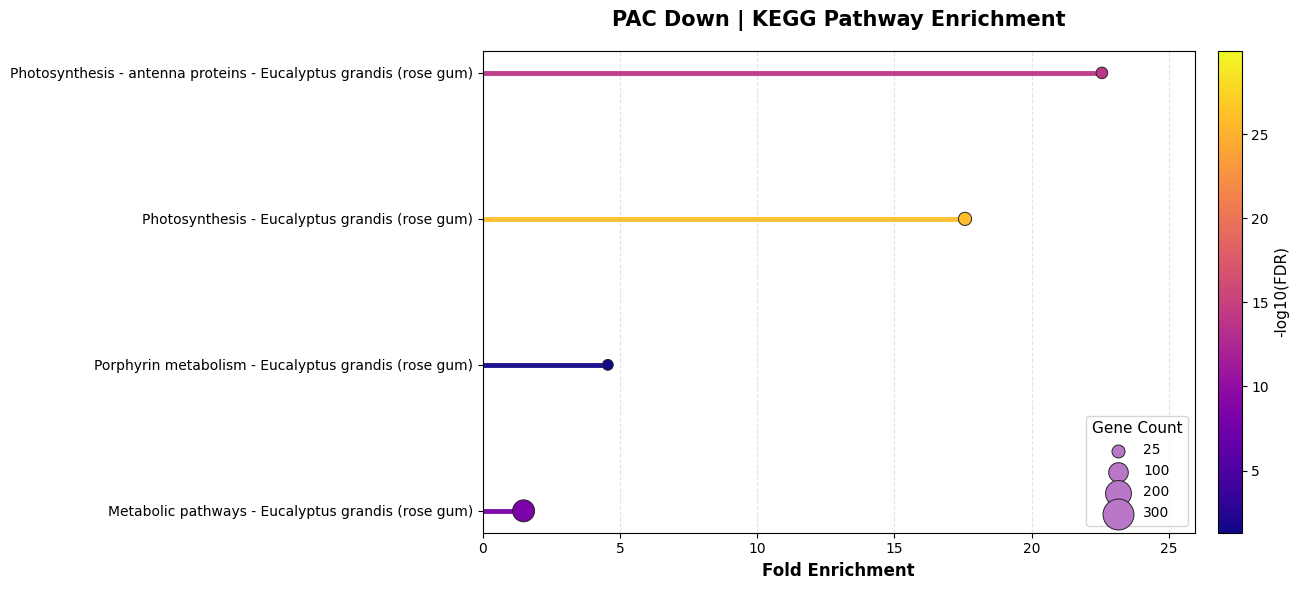

Saved: KEGG_Lollipop_Plots\Treatment\GA-PAC_Up_KEGG_Lollipop.png


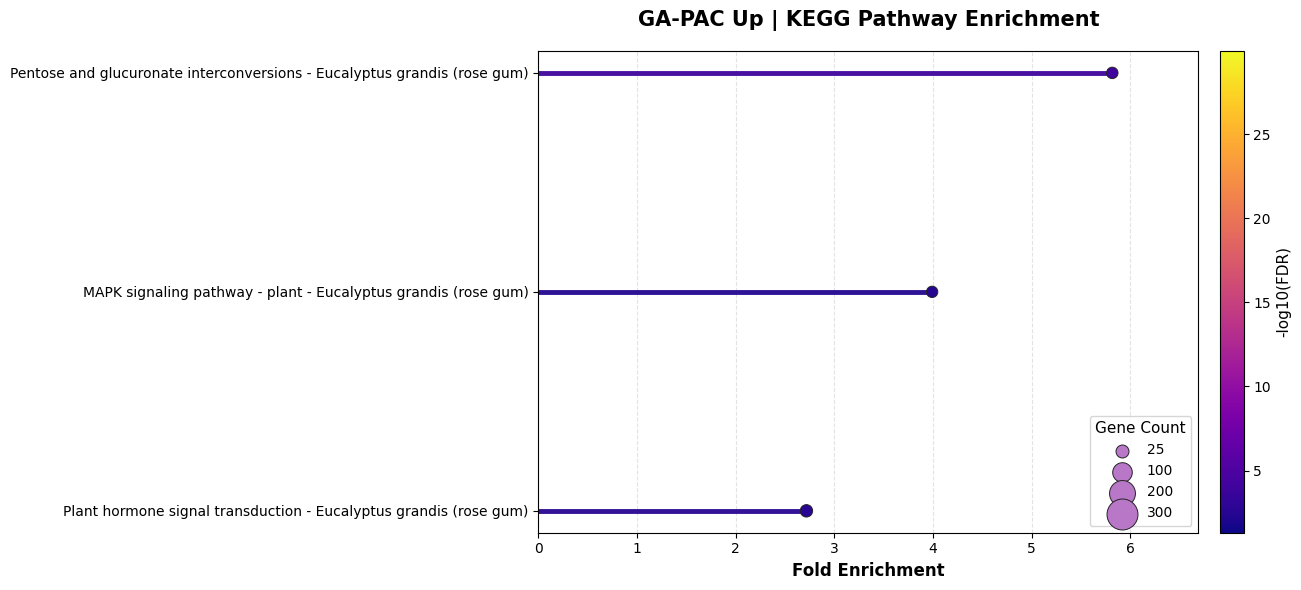

Saved: KEGG_Lollipop_Plots\Treatment\GA-PAC_Down_KEGG_Lollipop.png


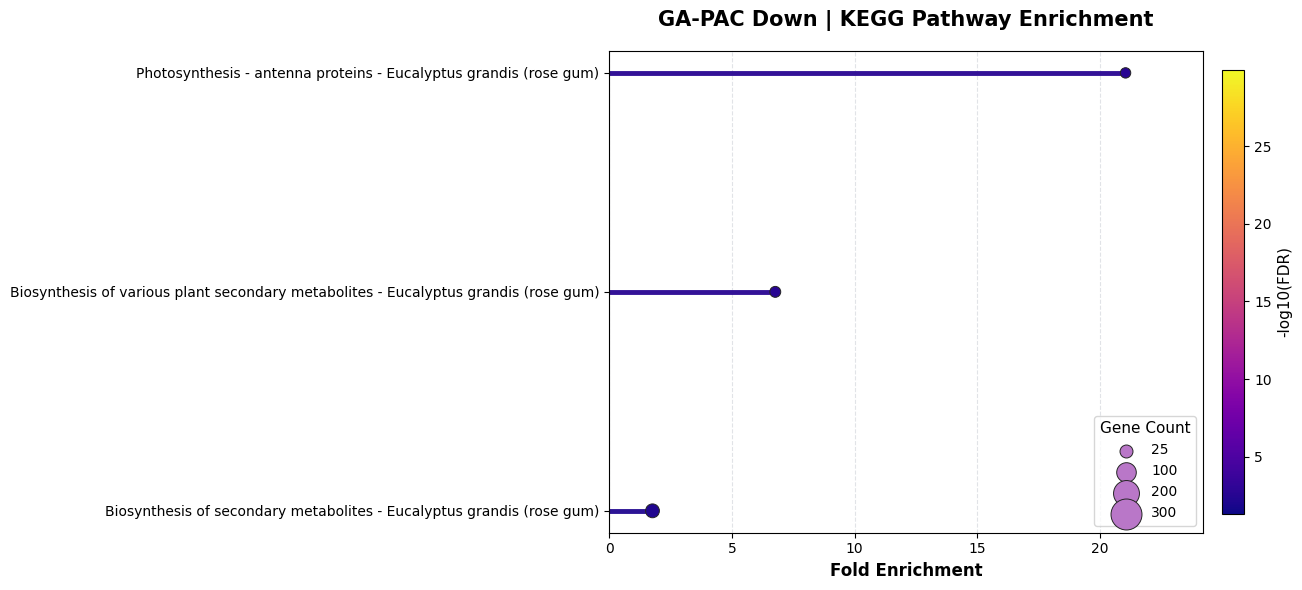


Generating Group plots...
Saved: KEGG_Lollipop_Plots\Group\Both_Up_KEGG_Lollipop.png


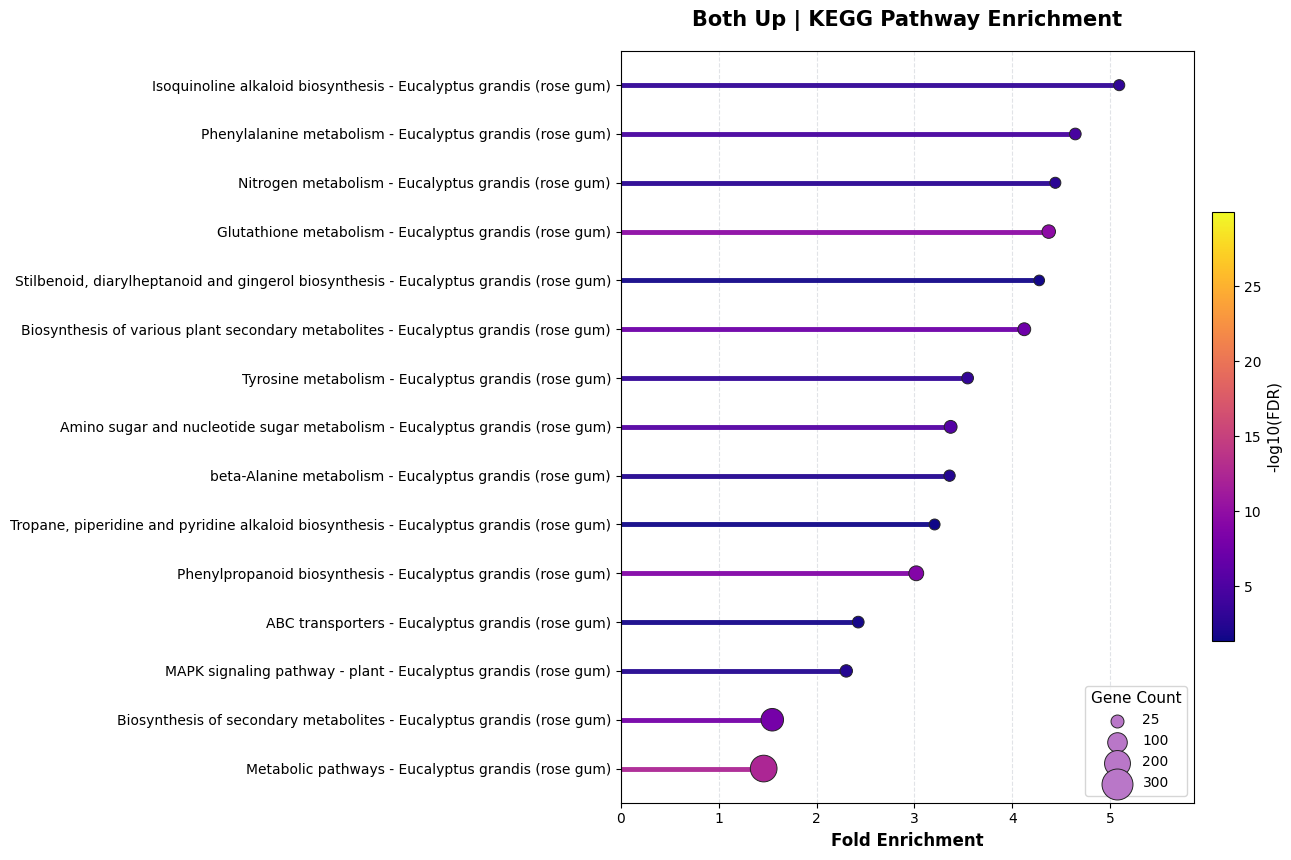

Saved: KEGG_Lollipop_Plots\Group\Both_Down_KEGG_Lollipop.png


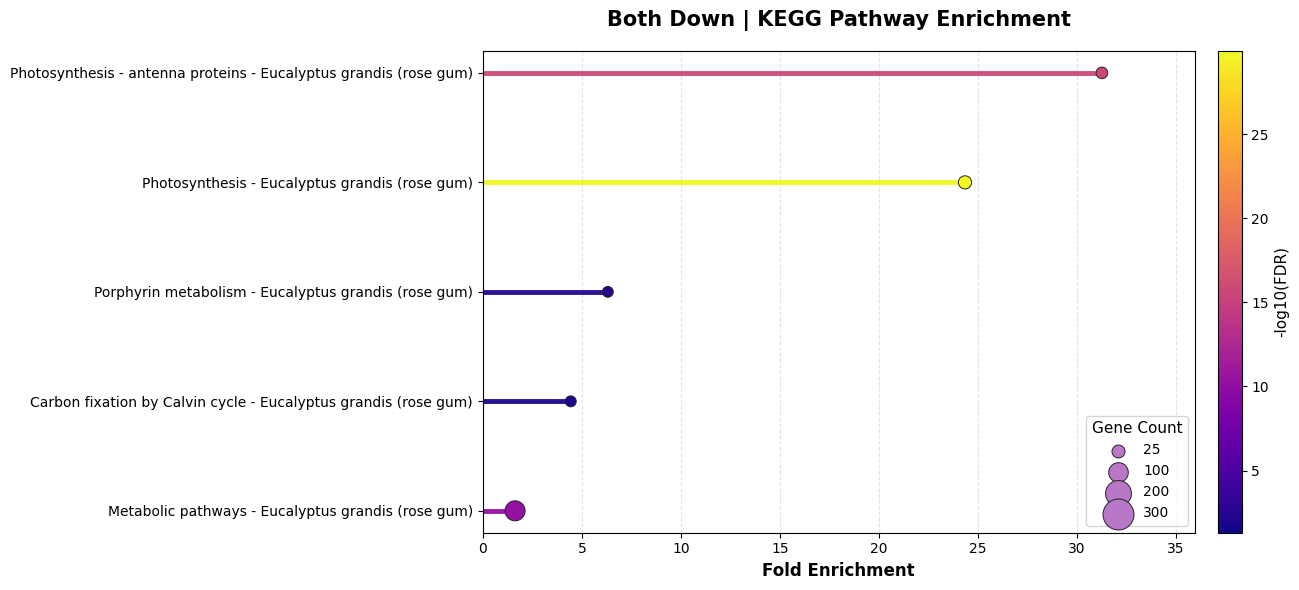

Saved: KEGG_Lollipop_Plots\Group\ga_up_only_KEGG_Lollipop.png


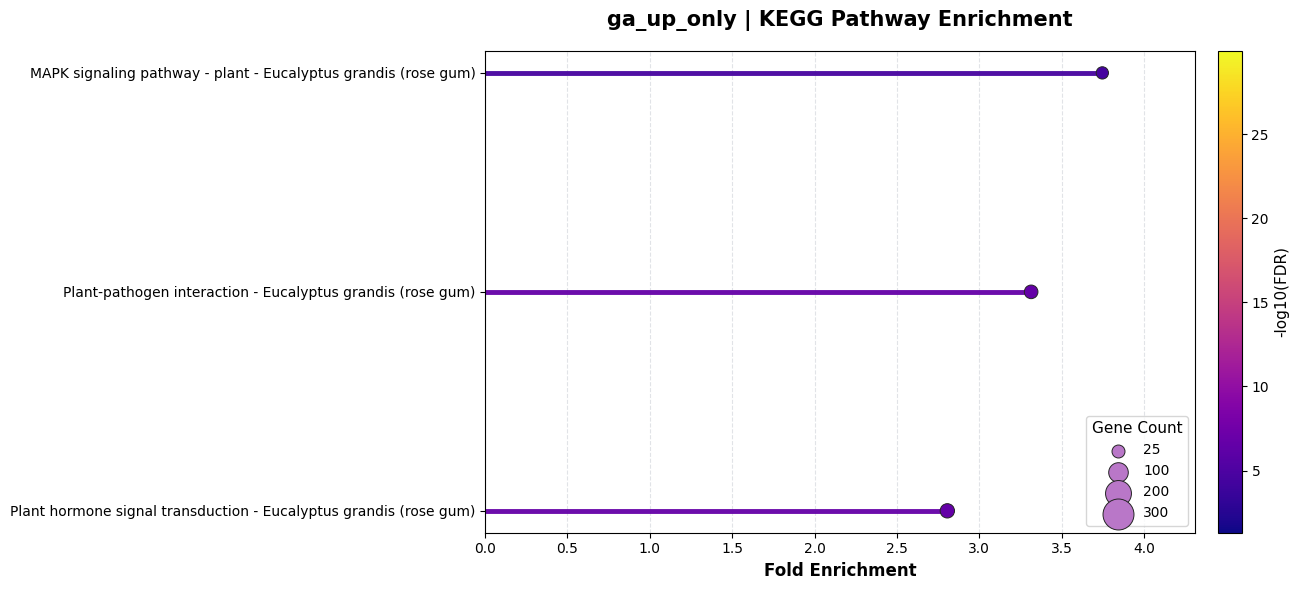

Saved: KEGG_Lollipop_Plots\Group\ga_down_only_KEGG_Lollipop.png


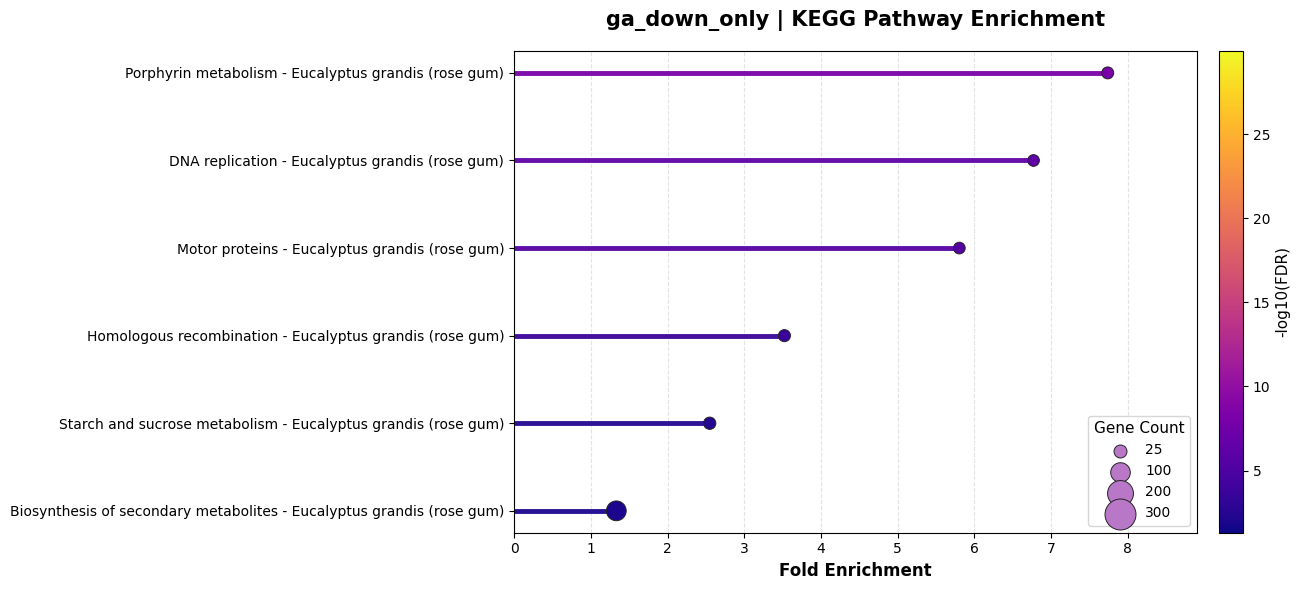

Saved: KEGG_Lollipop_Plots\Group\pac_up_only_KEGG_Lollipop.png


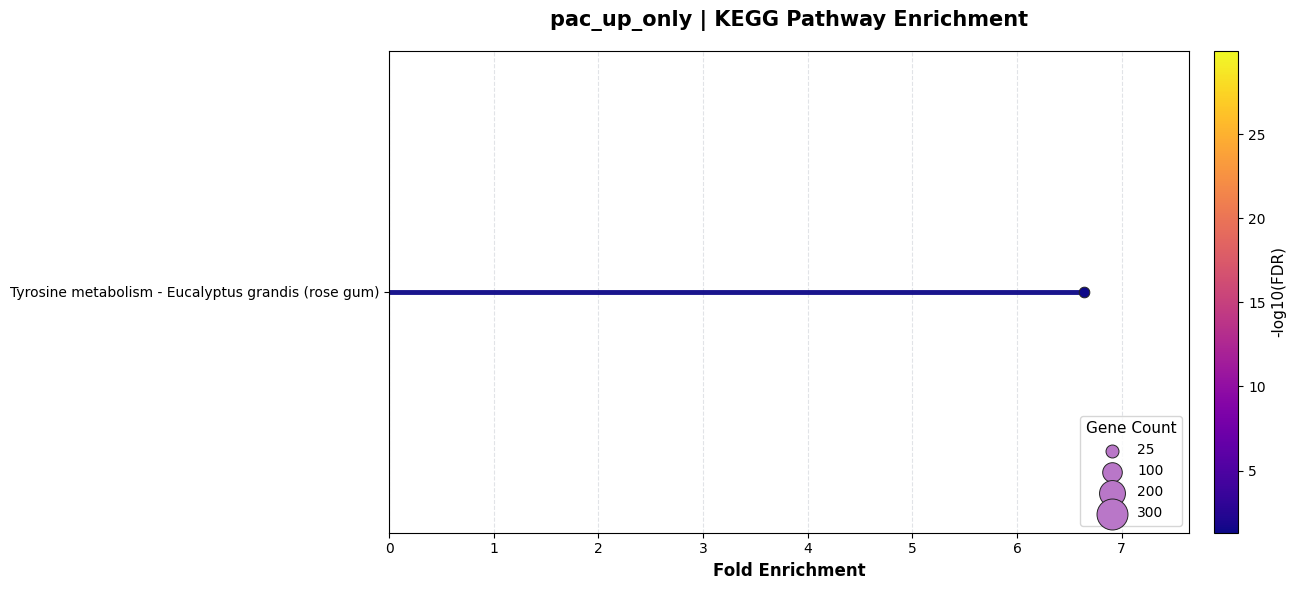

Saved: KEGG_Lollipop_Plots\Group\pac_down_only_KEGG_Lollipop.png


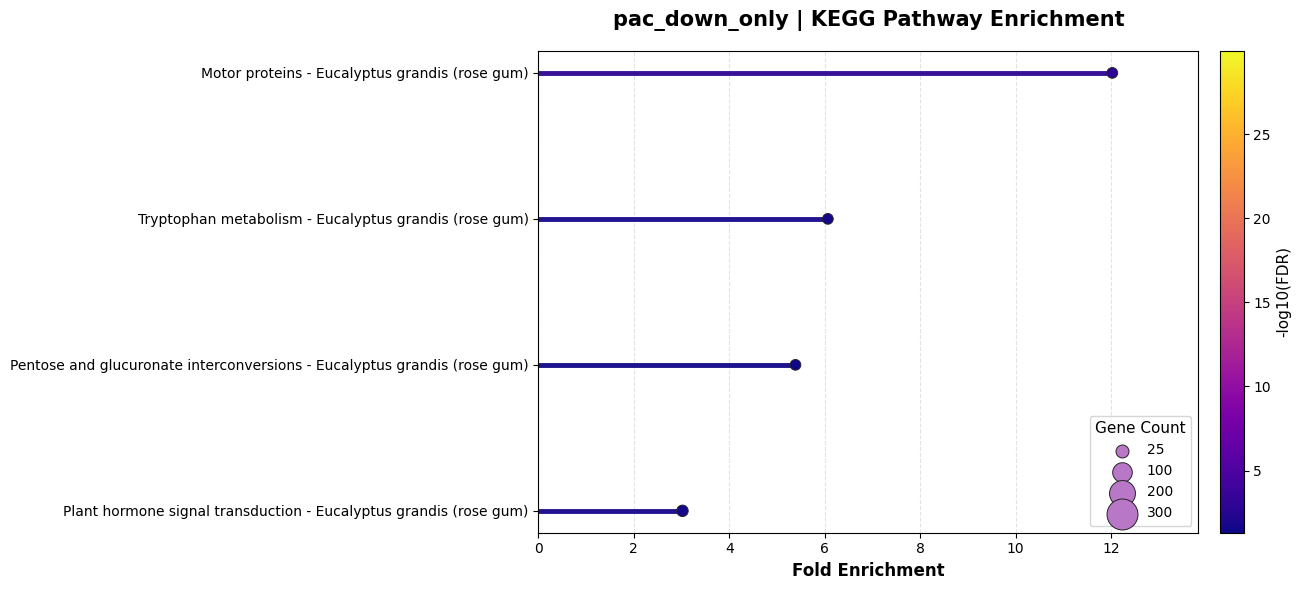

Saved: KEGG_Lollipop_Plots\Group\GA_Specific_Up_KEGG_Lollipop.png


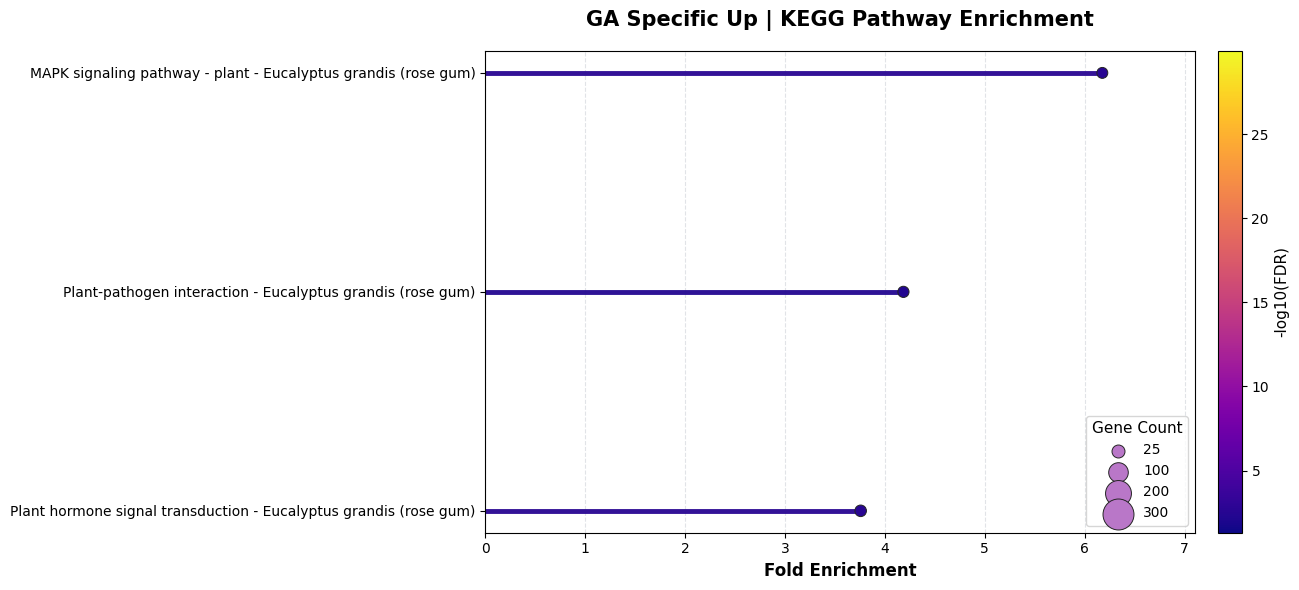

Saved: KEGG_Lollipop_Plots\Group\GA_Specific_Down_KEGG_Lollipop.png


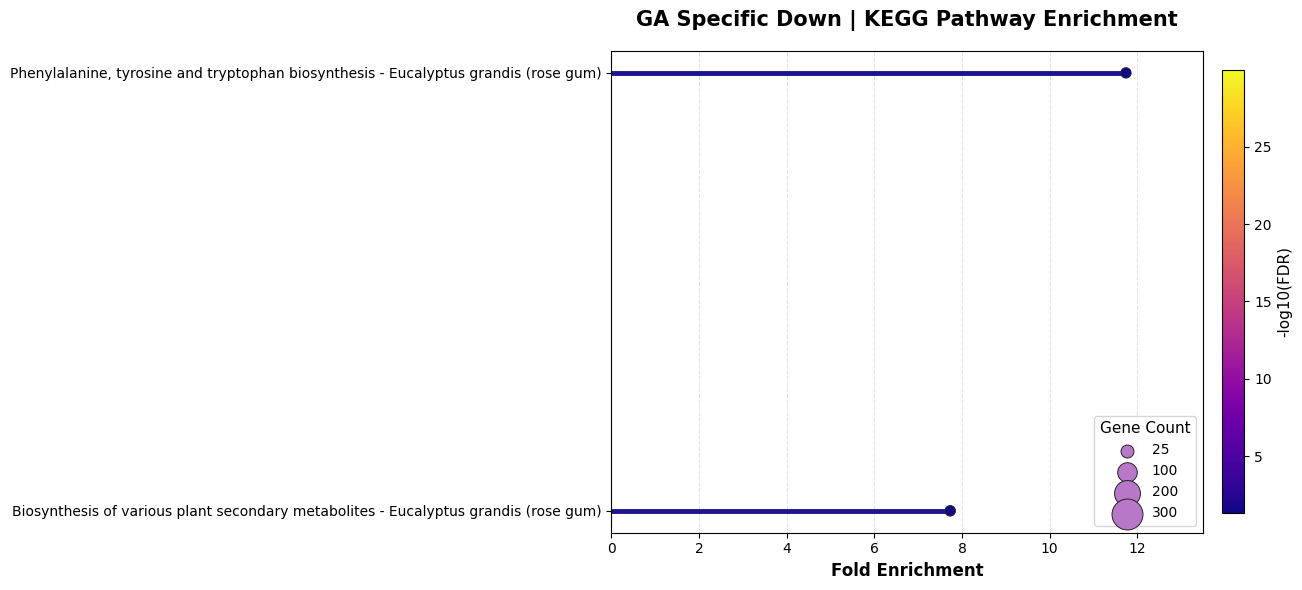

Saved: KEGG_Lollipop_Plots\Group\PAC_Specific_Down_KEGG_Lollipop.png


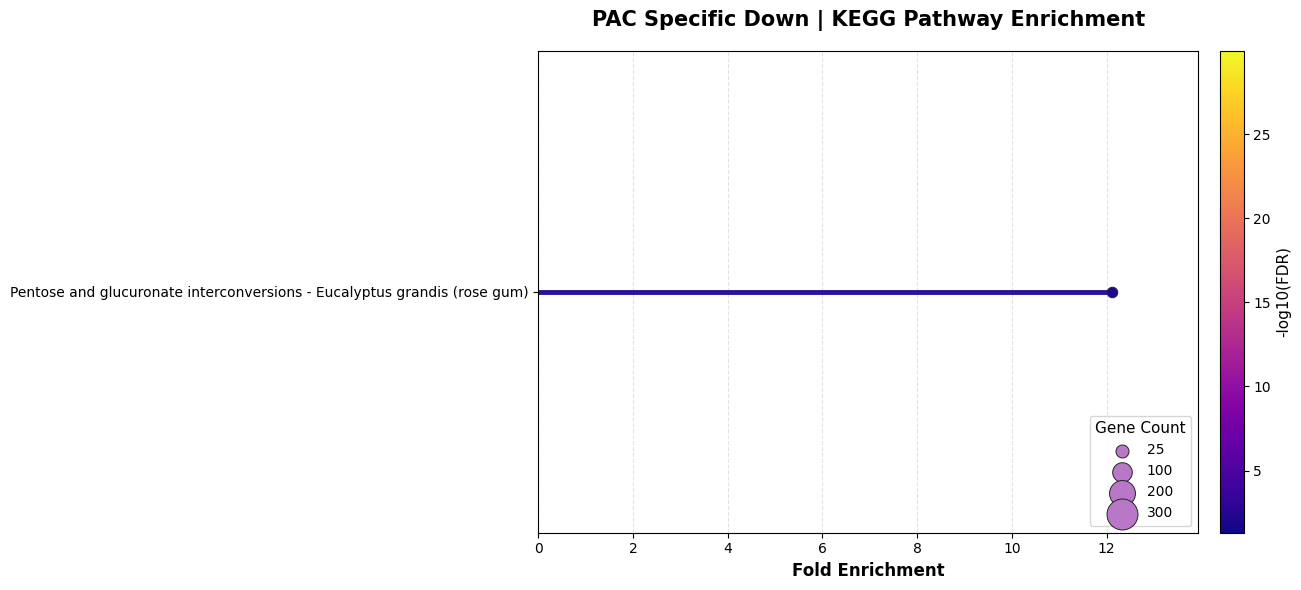


All KEGG Lollipop plots completed.


In [77]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib import colormaps
from pathlib import Path
from matplotlib.lines import Line2D

# =====================================================
# 1. SETTINGS
# =====================================================

TOP_N = 20
FDR_CUTOFF = 0.05
SHOW_PLOTS = True

# "FDR" or "Fold_Enrichment"
SORT_BY = "Fold_Enrichment"

LINE_WIDTH = 3.5

OUTPUT_DIR = Path("KEGG_Lollipop_Plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Previous KEGG analysis results
enrichment_sets = kegg_enrichment_results

# =====================================================
# 2. PREPARE SIGNIFICANT PATHWAYS
# =====================================================

required_columns = {
    "Pathway",
    "Pathway_Name",
    "Gene_Count",
    "Fold_Enrichment",
    "FDR"
}

prepared = {}
all_scores = []
all_counts = []

for analysis_name, groups in enrichment_sets.items():

    prepared[analysis_name] = {}

    for group_name, df_original in groups.items():

        df = df_original.copy()

        if df.empty:
            print(f"No KEGG results: {group_name}")
            continue

        missing = required_columns - set(df.columns)

        if missing:
            print(f"Missing columns in {group_name}: {missing}")
            continue

        for col in ["FDR", "Gene_Count", "Fold_Enrichment"]:
            df[col] = pd.to_numeric(
                df[col], errors="coerce"
            )

        df = df[
            (df["FDR"] >= 0) &
            (df["FDR"] < FDR_CUTOFF) &
            (df["Gene_Count"] > 0) &
            (df["Fold_Enrichment"] > 0)
        ].copy()

        df = df.replace(
            [np.inf, -np.inf], np.nan
        ).dropna(
            subset=["FDR", "Gene_Count", "Fold_Enrichment"]
        )

        if df.empty:
            print(f"No significant KEGG pathways: {group_name}")
            continue

        df["Score"] = -np.log10(
            df["FDR"].clip(lower=1e-300)
        )

        prepared[analysis_name][group_name] = df

        all_scores.extend(df["Score"].tolist())
        all_counts.extend(df["Gene_Count"].tolist())

if not all_scores:
    raise ValueError(
        "No significant KEGG pathways found in any group."
    )

# =====================================================
# 3. GLOBAL COLOR AND SIZE SCALES
# =====================================================

norm = Normalize(
    vmin=-np.log10(FDR_CUTOFF),
    vmax=max(max(all_scores), -np.log10(FDR_CUTOFF) + 0.1)
)

cmap = colormaps["plasma"]

max_count = max(all_counts)

def bubble_size(count):
    return 50 + 450 * np.asarray(count) / max(max_count, 1)


def nice_legend_counts(max_value):

    if max_value <= 10:
        step = 2
    elif max_value <= 30:
        step = 5
    elif max_value <= 80:
        step = 10
    elif max_value <= 150:
        step = 20
    else:
        step = 25

    values = list(
        range(step, int(max_value) + 1, step)
    )

    if not values:
        return [int(max_value)]

    if len(values) > 4:
        indices = np.linspace(
            0, len(values) - 1, 4
        ).astype(int)
        values = [values[i] for i in indices]

    return sorted(set(values))

legend_counts = nice_legend_counts(max_count)

# =====================================================
# 4. LOLLIPOP PLOTTING FUNCTION
# =====================================================

def plot_kegg_lollipop(df, analysis_name, group_name):

    # Remove duplicate pathways
    sub = (
        df.sort_values("FDR")
        .drop_duplicates("Pathway")
    )

    # Select top N according to sorting criterion
    if SORT_BY == "Fold_Enrichment":

        sub = sub.sort_values(
            ["Fold_Enrichment", "FDR"],
            ascending=[False, True]
        )

    else:

        sub = sub.sort_values(
            ["FDR", "Fold_Enrichment"],
            ascending=[True, False]
        )

    sub = sub.head(TOP_N).iloc[::-1].reset_index(drop=True)

    y = np.arange(len(sub))

    fig_height = max(6, len(sub) * 0.46 + 1.8)

    fig, ax = plt.subplots(
        figsize=(13, fig_height)
    )

    colors = cmap(norm(sub["Score"].values))

    # ---------------------------------------------
    # Thick lollipop lines
    # ---------------------------------------------

    for yi, fold, color in zip(
        y,
        sub["Fold_Enrichment"],
        colors
    ):
        ax.hlines(
            y=yi,
            xmin=0,
            xmax=fold,
            color=color,
            linewidth=LINE_WIDTH,
            alpha=0.95,
            zorder=2
        )

    # ---------------------------------------------
    # Bubbles
    # ---------------------------------------------

    scatter = ax.scatter(
        sub["Fold_Enrichment"],
        y,
        s=bubble_size(sub["Gene_Count"]),
        c=sub["Score"],
        cmap=cmap,
        norm=norm,
        edgecolors="#242424",
        linewidths=0.7,
        zorder=3
    )

    ax.set_yticks(y)
    ax.set_yticklabels(
        sub["Pathway_Name"],
        fontsize=10
    )

    ax.set_xlabel(
        "Fold Enrichment",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_title(
        f"{group_name} | KEGG Pathway Enrichment",
        fontsize=15,
        fontweight="bold",
        pad=18
    )

    ax.set_xlim(
        0,
        sub["Fold_Enrichment"].max() * 1.15
    )

    ax.grid(
        axis="x",
        linestyle="--",
        color="#D1D5DB",
        alpha=0.65
    )

    ax.set_axisbelow(True)

    # ---------------------------------------------
    # Colorbar
    # ---------------------------------------------

    cbar = fig.colorbar(
        scatter,
        ax=ax,
        fraction=0.035,
        pad=0.03
    )

    cbar.set_label(
        "-log10(FDR)",
        fontsize=11
    )

    # ---------------------------------------------
    # Gene Count legend
    # ---------------------------------------------

    handles = [
        ax.scatter(
            [],
            [],
            s=bubble_size(count),
            color="#B977C8",
            edgecolors="#242424",
            linewidths=0.7
        )
        for count in legend_counts
    ]

    ax.legend(
        handles,
        [str(count) for count in legend_counts],
        title="Gene Count",
        loc="lower right",
        fontsize=10,
        title_fontsize=11,
        frameon=True
    )

    # ---------------------------------------------
    # Save PNG
    # ---------------------------------------------

    plt.tight_layout()

    save_folder = OUTPUT_DIR / analysis_name
    save_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    safe_name = (
        group_name.replace(" ", "_")
        .replace("/", "_")
    )

    filename = f"{safe_name}_KEGG_Lollipop.png"

    save_path = save_folder / filename

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", save_path)

    if SHOW_PLOTS:
        plt.show()

    plt.close(fig)

# =====================================================
# 5. GENERATE PLOTS FOR ALL GROUPS
# =====================================================

for analysis_name, groups in prepared.items():

    print(f"\nGenerating {analysis_name} plots...")

    for group_name, df in groups.items():

        plot_kegg_lollipop(
            df=df,
            analysis_name=analysis_name,
            group_name=group_name
        )

print("\nAll KEGG Lollipop plots completed.")


## Inference

In [80]:
treatment_kegg = pd.read_excel('Treatment_KEGG_Enrichment.xlsx')

In [85]:
treatment_kegg['target_Gene_ids']

0      104414194, 104414195, 104414196, 104414197, 10...
1      104414609, 104418455, 104418719, 104418762, 10...
2      104414194, 104414195, 104414196, 104414197, 10...
3      104414565, 104414609, 104414620, 104414845, 10...
4      104414427, 104414483, 104414490, 104414518, 10...
                             ...                        
153                                 104416280, 108954993
154                                                  NaN
155    104418395, 104436573, 104441897, 104448221, 10...
156                      104432652, 104441257, 104441809
157                                                  NaN
Name: target_Gene_ids, Length: 158, dtype: object

In [86]:
kegg_enrichment_results

{'Treatment': {'GA Up':       Pathway                                       Pathway_Name  Gene_Count  \
  0    egr00480  Glutathione metabolism - Eucalyptus grandis (r...          38   
  1    egr00940  Phenylpropanoid biosynthesis - Eucalyptus gran...          57   
  2    egr01100  Metabolic pathways - Eucalyptus grandis (rose ...         302   
  3    egr01110  Biosynthesis of secondary metabolites - Eucaly...         209   
  4    egr04016  MAPK signaling pathway - plant - Eucalyptus gr...          39   
  ..        ...                                                ...         ...   
  153  egr00603  Glycosphingolipid biosynthesis - globo and iso...           2   
  154  egr00604  Glycosphingolipid biosynthesis - ganglio serie...           0   
  155  egr00620  Pyruvate metabolism - Eucalyptus grandis (rose...          10   
  156  egr00565  Ether lipid metabolism - Eucalyptus grandis (r...           3   
  157  egr05100  Bacterial invasion of epithelial cells - Eucal...          